# Agentic GraphRAG v4: especialistas, registro de hechos verificados y datos en vivo del tenant de Luna

**Taller final · MMIA 6021 Procesamiento de Lenguaje Natural**
**Autor:** David León Pilco
**Tema del curso:** 3 — RAG / Agentic RAG con LangChain y LangGraph

Esta es la **versión 4**. Conserva todo lo anterior y agrega la sección **5D**: un especialista de datos consulta en tiempo real la base MySQL de Garage84 mediante una herramienta de solo lectura, una guardia determinista valida cada SQL contra el grafo antes de ejecutarlo, y el motor solo acepta cifras que estén en el resultado de una consulta. Antes, la versión 3 conserva todo lo anterior y agrega la sección **5C**, una nueva arquitectura: el enrutador elige especialistas que trabajan en paralelo, un motor determinista valida sus hechos contra el grafo, y la respuesta se redacta y verifica contra ese registro. Antes, la versión 2: agrega la sección **4B (Reflexion)**, la evalúa en la sección 5 y, en la sección **5B**, diagnostica sus fallas, aplica una mejora por falla, entrena un manual de reglas con preguntas nuevas y mide todo en un conjunto reservado. Las respuestas de `rag_simple`, `linea_base` y `agente` se comparten con `taller_tenant_kg.ipynb` a través de `resultados/`: si ya existen, no se vuelven a pagar.

Relación con el trabajo de titulación: es el primer módulo del agente de consultas de Luna. Antes de generar SQL contra la base de un cliente, el agente tiene que saber qué tablas y columnas existen, cómo se unen y qué escribe cada pantalla.

| Sección | Criterio |
|---|---|
| 1. Problema y datos | 1 |
| 2. Instrumentación del costo | 2 |
| 3. Línea base (receta del README de `tenant-kg`) | 2 |
| 4. Solución propuesta (agente con verificación de esquema) | 1 |
| 4B. Reflexion: Actor + Evaluador híbrido + Auto-reflexión (`s4_p2`) | 1 |
| 5B. Versión 2: diagnóstico, mejoras, entrenamiento y conjunto reservado | 1, 2 |
| 5C. Versión 3: especialistas en paralelo, motor de hechos, verificación contra el registro y memoria de casos | 1, 2 |
| 5D. Versión 4: base en vivo como herramienta (especialista de datos, guardia SQL, anclaje numérico) | 1, 2 |
| 5. Evaluación comparativa | 2 |
| 6. Conclusiones | 3 |
| 7. Declaración de uso de IAG · 8. Referencias | — |

## Arquitectura de la solución (v4)

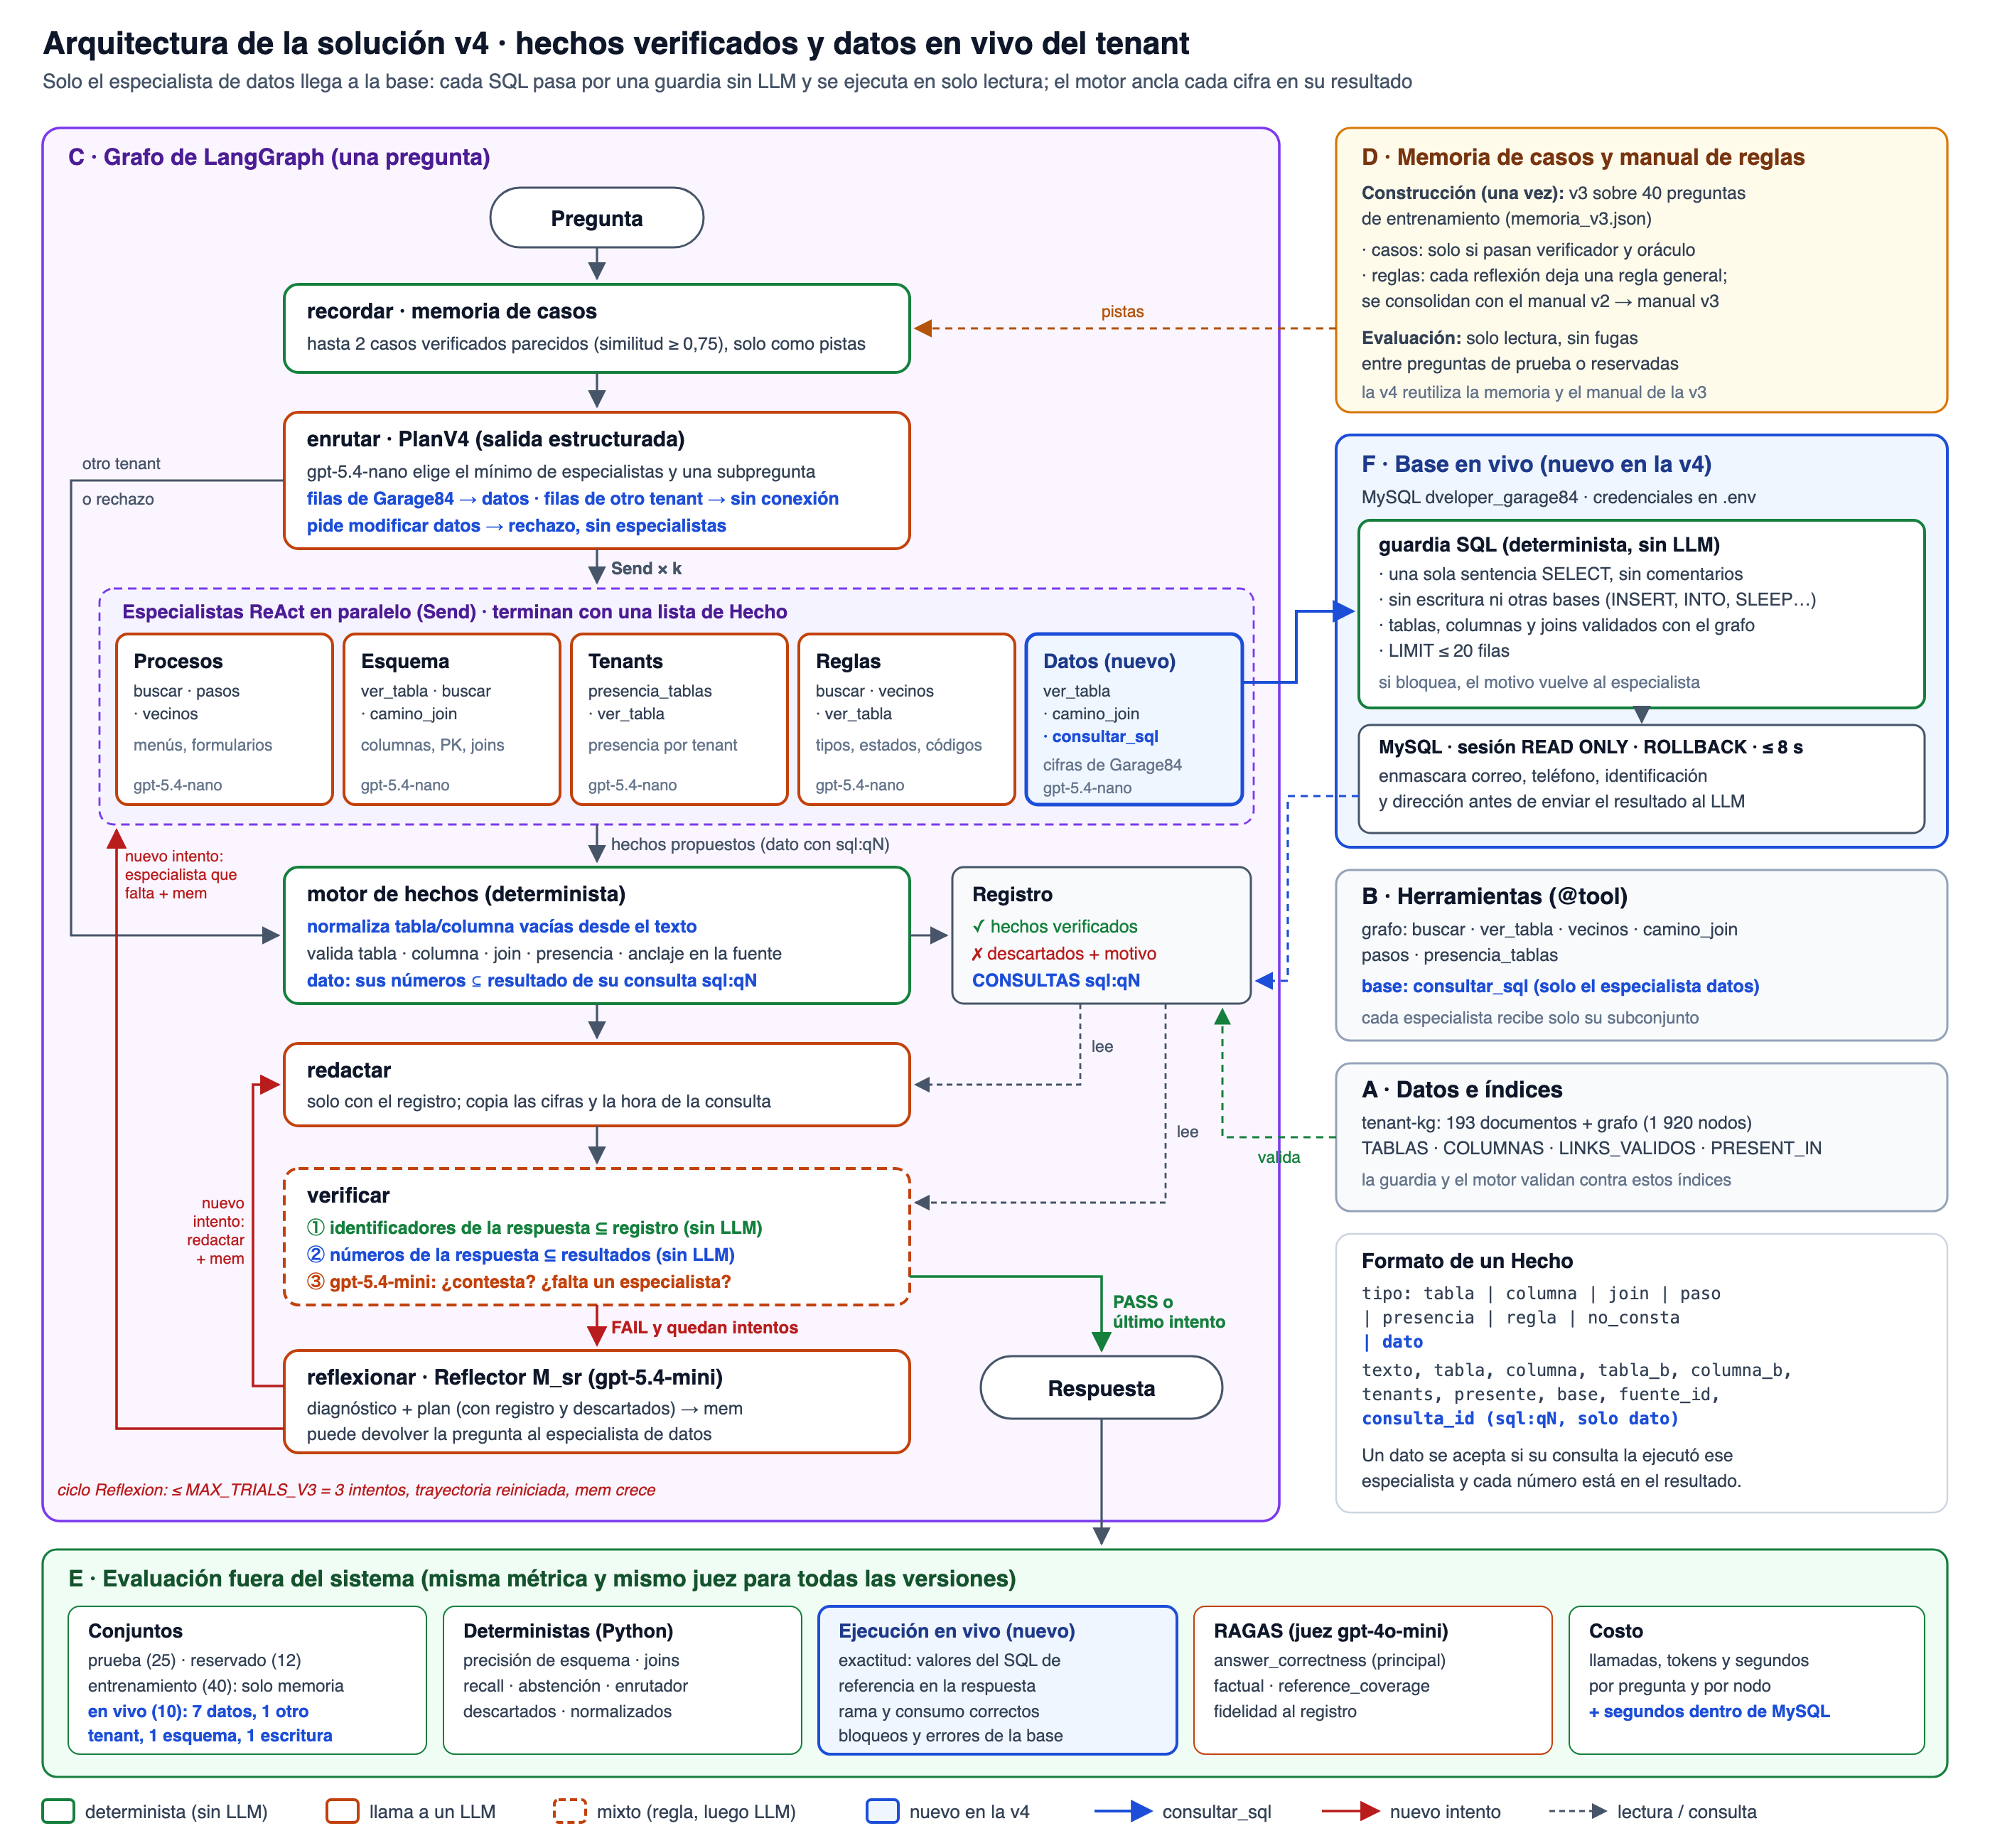

| Bloque del diagrama | Sección del notebook |
|---|---|
| A · Datos e índices (`tenant-kg/`, Chroma, `LINKS_VALIDOS`) | 1.2–1.6 |
| B · Herramientas del grafo y `consultar_sql` | 4.2, 5B.3 y 5D.3 |
| C · Grafo de LangGraph: enrutar → especialistas en paralelo (incluido **datos**) → motor → redactar → verificar → reflexionar | 5C.1–5C.4 y 5D.5–5D.7 |
| D · Memoria de casos y manual de reglas (Reflexion) | 5C.3 y 5C.5 |
| E · Evaluación fuera del sistema (incluido el conjunto en vivo) | 2, 5, 5B.9, 5C.8 y 5D.9–5D.11 |
| F · Base en vivo: guardia SQL, sesión de solo lectura y registro de consultas | 5D.1–5D.4 |

**Arreglo de la v4.** El único camino a la base es `especialista[datos] → consultar_sql → guardia → MySQL`. El enrutador decide si una pregunta necesita la base; la guardia (sin LLM) valida cada SQL contra el grafo y lo ejecuta en una transacción de solo lectura; cada resultado queda en `CONSULTAS` con un id `sql:qN`, y el motor solo acepta un hecho `dato` si sus números están en ese resultado. Las credenciales se leen de `.env`.

Verde: determinista, sin costo de LLM. Naranja: llama a un LLM. Punteado: mixto (regla primero, LLM después). Azul: nuevo en la v4. La fuente editable del diagrama está en `figuras/arquitectura_v4.svg`.

## 0. Configuración

```bash
# Una sola vez, en la terminal (el mismo entorno del curso)
# conda create -n lang python=3.11 && conda activate lang
pip install ragas==0.2.6 datasets "langchain<0.4" "langchain-core<0.4" "langchain-community<0.4" "langchain-openai<0.4" "langchain-chroma<0.3" "langgraph<0.7" python-dotenv pandas matplotlib tiktoken pymysql
# Solo si se usa GLM local:
pip install langchain-deepseek
```

`ragas==0.2.6` no importa con LangChain 1.x (le falta `langchain_community.chat_models.vertexai`); por eso se fija la serie 0.3. El notebook se probó con esas versiones.

El archivo `.env` debe tener `OPENAI_API_KEY` (o `OPENAI_KEY`, como en `s3_p5`). Para la sección 5D, también `KERBEROS_JDBC_URL='jdbc:mysql://host/base?user=...&password=...'`, entre comillas simples para que python-dotenv no interprete los `$` de la contraseña. `.env` está en `.gitignore`: la contraseña nunca va en el notebook. Las celdas que consultan la base llevan la etiqueta `bd`. El notebook se ejecuta desde la raíz del repositorio, al lado de la carpeta `tenant-kg/`.

In [1]:
import os
import re
import json
import time
import difflib
from collections import Counter, deque
from pathlib import Path
from typing import Annotated
from typing_extensions import TypedDict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
from dotenv import load_dotenv

from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from langchain_chroma import Chroma
from langchain_core.documents import Document
from langchain_core.tools import tool
from langchain_core.messages import BaseMessage, SystemMessage, HumanMessage, AIMessage, ToolMessage
from langgraph.graph import StateGraph, END
from langgraph.graph.message import add_messages

load_dotenv()
OPENAI_KEY = os.getenv("OPENAI_API_KEY") or os.getenv("OPENAI_KEY")

pd.options.display.max_colwidth = 120

/Users/peluchito/Desktop/procesamientoLenguajeNatural/.venv/lib/python3.11/site-packages/langgraph/cache/base/__init__.py:8: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit value (e.g., allowed_objects='messages' or allowed_objects='core') to suppress this warning.
  from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer


In [2]:
# Rutas
KG_DIR = Path("tenant-kg")                 # datos: grafo + corpus RAG (solo lectura)
EVAL_PATH = Path("eval/preguntas.jsonl")    # conjunto de evaluación
OUT_DIR = Path("resultados")                # respuestas, costos y RAGAS persistidos
OUT_DIR.mkdir(exist_ok=True)

# Modelos
BACKEND = "openai"                                   # "openai" o "glm"
# Modelos baratos por defecto; se cambian en .env sin tocar el código
LLM_MODEL = os.getenv("OPENAI_MODEL", "gpt-5.4-nano")   # generador de todos los sistemas
JUEZ_MODEL = os.getenv("JUEZ_MODEL", "gpt-4o-mini")     # juez fijo de RAGAS, distinto del generador
EMB_MODEL = "text-embedding-3-small"

# Recuperación y agente
TOP_K = 6          # documentos por búsqueda (el README pide 4 a 8)
MAX_VECINOS = 4    # documentos extra que agrega la expansión de un salto
MAX_STEPS = 6      # pasos think/act por intento
MAX_RETRIES = 2    # reintentos que puede pedir el verificador
N_EVAL = 25        # preguntas evaluadas
OBS_CHARS = 300    # caracteres de cada observación que se imprimen
VERBOSE = True     # True: imprime la traza del agente

# False: si ya existen resultados en OUT_DIR, se cargan y no se vuelve a pagar llamadas
RECALCULAR = False

In [3]:
if BACKEND == "openai":
    llm = ChatOpenAI(model=LLM_MODEL, api_key=OPENAI_KEY, temperature=0)
else:
    # GLM-5.3-Flash del servidor vLLM de la universidad (uso_glm.ipynb)
    from langchain_deepseek import ChatDeepSeek
    llm = ChatDeepSeek(
        api_base="http://172.28.230.10:12555/v1",
        api_key="local",
        model="zai-org/GLM-5.3-Flash",
        temperature=0.1,
        max_tokens=8000,
        reasoning_effort="low",
    )

embeddings = OpenAIEmbeddings(model=EMB_MODEL, api_key=OPENAI_KEY)

print(llm.invoke([HumanMessage(content="Hola")]).content)
print(f'{embeddings.embed_query("Hola")[:5]=}')

¡Hola! 😊 ¿En qué puedo ayudarte hoy?
embeddings.embed_query("Hola")[:5]=[0.02166748046875, -0.052978515625, -0.015350341796875, 0.034820556640625, 0.0213470458984375]


## 1. Problema y datos

### 1.1 Problema

Luna abre, después del login, la base MySQL de cada contribuyente: el ERP Kerberos (el *tenant*). Desarrolladores, soporte y el futuro agente de consultas necesitan responder preguntas como:

- ¿Qué tablas escribe la anulación de una factura?
- ¿Cómo uno la obligación de cartera con el cliente?
- ¿Cómo sé si un comprobante está pendiente de autorizar en el SRI?

Un LLM solo no basta por tres razones:

1. **El esquema es propio y críptico** (`t57011z1`, `szDutyStatus`, `mnNroDireccion`). No está en los datos de entrenamiento de ningún modelo.
2. **No hay claves foráneas declaradas.** Un join solo es seguro si el grafo tiene una arista `INFERRED_LINK`. La misma persona se llama `mnNroDireccion` en `t0101` y `nroDireccion` en cartera.
3. **Hay trampas de nombre.** Las tablas `t9801/t9802/t9803` del tenant **no** son el login de Luna, que vive en otra base (Sugar).

El riesgo principal es la **alucinación de esquema**: responder con tablas, columnas o joins que no existen. Una respuesta así, convertida en SQL, falla o, peor, devuelve datos equivocados.

Ejemplo: la misma pregunta de join, hecha al LLM **sin contexto**.

In [4]:
pregunta_demo = "En el ERP Kerberos de Luna, ¿cómo uno la tabla de obligaciones de cartera con el cliente? Responde con tabla.columna."
respuesta_sin_contexto = llm.invoke([HumanMessage(content=pregunta_demo)]).content
print(respuesta_sin_contexto)

No puedo dar una respuesta confiable porque “Kerberos de Luna” puede variar por versión/módulo y no tengo acceso a su diccionario de datos.  

Para ayudarte, necesito uno de estos datos:
1) el **nombre exacto** de la tabla de “obligaciones de cartera” y el **nombre exacto** de la tabla del **cliente** (tal como aparecen en el ERP), o  
2) un **pantallazo**/captura del “cómo relaciona” (catálogo de relaciones) o la **consulta**/reporte donde estás armando la unión.

Mientras tanto, en la mayoría de ERPs la unión se hace con algún identificador del cliente, típicamente en el formato:

- `obligaciones_cartera.id_cliente = cliente.id_cliente`

Pásame los nombres de las tablas/columnas reales y te lo devuelvo exacto en el formato **tabla.columna**.


La respuesta correcta es `t03b11.nroDireccion = t0101.mnNroDireccion`. La celda de la sección 4.4 aplica el verificador de esquema a esta misma respuesta.

### 1.2 Datos: `tenant-kg/`

Es el esquema leído de `information_schema` el 2026-10-09 en cuatro tenants de producción, más la documentación de procesos y formularios de Luna. **No contiene filas de negocio** (facturas, pacientes, correos). El corpus RAG ya viene fragmentado: cada línea JSONL es un documento con `id`, `kind` y `text`, y su `id` es (o se traduce a) un nodo del grafo.

In [5]:
manifest = json.loads((KG_DIR / "manifest.json").read_text(encoding="utf-8"))

# Muestra sin el RUC de los clientes
display(pd.DataFrame(manifest["samples"])[["base", "empresa", "table_count", "column_count", "fk_count"]])
print("Generado:", manifest["generated_at"], "| esquema leído:", manifest["source_sampled_at"])
print(manifest["counts"])

,base,empresa,table_count,column_count,fk_count
0,dveloper_lifecolor,LIFECOLOR,60,1275,0
1,dveloper_indupan,PANADERIA INDUPAN,54,1202,0
2,dveloper_garage84,GARAGE84,54,1213,0
3,dveloper_labclinico1,LABORATORIO BYT,55,1226,0


Generado: 2026-10-10T22:13:48.082741+00:00 | esquema leído: 2026-10-09T22:25:21-05:00
{'tables_union': 61, 'nodes': 1920, 'edges': 2742, 'table_chunks': 61, 'concept_chunks': 5, 'relation_chunks': 16, 'process_chunks': 22, 'form_chunks': 89, 'declared_foreign_keys': 0, 'inferred_links': 16}


In [6]:
ARCHIVOS_RAG = ["tables", "concepts", "relations", "procesos", "formularios"]

DOCS = []
for nombre in ARCHIVOS_RAG:
    with open(KG_DIR / "rag" / f"{nombre}.jsonl", encoding="utf-8") as f:
        for linea in f:
            d = json.loads(linea)
            d["archivo"] = nombre
            DOCS.append(d)

DOC_POR_ID = {d["id"]: d for d in DOCS}
df_docs = pd.DataFrame(DOCS)
df_docs["caracteres"] = df_docs["text"].str.len()

print(f"{len(DOCS)=}  caracteres totales={df_docs['caracteres'].sum():,}")
display(df_docs.groupby(["archivo", "kind"]).agg(docs=("id", "count"),
                                                 mediana_chars=("caracteres", "median"),
                                                 max_chars=("caracteres", "max")))
display(df_docs["domain"].value_counts().to_frame("docs").T)

len(DOCS)=193  caracteres totales=159,175


docs  mediana_chars  max_chars
archivo     kind                                       
concepts    concept         4          798.0       2482
            layer           1          724.0        724
formularios form_action    89          592.0       1666
procesos    process        22         1161.0       1503
relations   relation       16          123.5        256
tables      table          61          807.0       5812

domain,ventas,inventario,compras,cartera,turnos,laboratorio,fiscal,farmacia,otros,nomina,...,terceros,caja,sri,seguridad,catalogos,contabilidad,acceso,impuestos,tesoreria,consultas
docs,29,22,19,13,11,9,8,8,7,6,...,6,6,6,5,3,2,2,2,1,1


In [7]:
# Un documento de ejemplo por tipo
for kind, grupo in df_docs.groupby("kind"):
    d = grupo.iloc[0]
    print(f"[{kind}] {d['id']}\n    {d['text'][:350]}...\n")

[concept] concept:tipo_documento
    FT (t57011z1.szDocumentType): Factura de venta legal. NV (t57011z1.szDocumentType): Nota de venta / orden de despacho interna. El barrido SRI no la autoriza.. RI (t57011z1.szInvoiceType): Factura en el consolidado de ventas por producto (junto con NV).. PU (t57011z1.szDocumentType): Pedido. En laboratorio es la solicitud de examen.. CZ (t57011z1.sz...

[form_action] form_action:personas.consultar
    Formulario Libro de direcciones. Acción consultar. Cómo se abre: Personas → Libro de direcciones. Pantalla: personas. Localizar una ficha ya existente antes de abrirla. Contexto del formulario: Ficha de tercero. Arriba se busca; Nueva persona abre el modal. El modal tiene tres pestañas: Detalle, Códigos de categoría y Fiscal / crédito. Guardar escr...

[layer] layer:tenant
    Este grafo describe la base tenant: el ERP Kerberos de un cliente, una base MySQL por contribuyente. No describe el catálogo del operador ni la base Sugar donde Luna valida el log

### 1.3 El grafo

`graph.json` tiene las tablas, sus 1 292 columnas, los procesos con sus pasos, los formularios, los códigos de documento y las relaciones. `adjacency.json` es la misma información indexada por nodo.

In [8]:
GRAFO = json.loads((KG_DIR / "graph" / "graph.json").read_text(encoding="utf-8"))
ADJ = json.loads((KG_DIR / "graph" / "adjacency.json").read_text(encoding="utf-8"))
NODOS = {n["id"]: n for n in GRAFO["nodes"]}
ARISTAS = GRAFO["edges"]


def extremo(a):
    # Otro extremo de una entrada de adyacencia: 'to' si sale, 'from' si entra, None si es un atributo (índice)
    return a.get("to") or a.get("from")

print(f"nodos={len(NODOS)}  aristas={len(ARISTAS)}")
display(pd.DataFrame({
    "nodos": pd.Series(Counter(n["type"] for n in GRAFO["nodes"])),
    "aristas": pd.Series(Counter(e["type"] for e in ARISTAS)),
}).fillna(0).astype(int).sort_values(["nodos", "aristas"], ascending=False))

nodos=1920  aristas=2742


,nodos,aristas
column,1292,0
form_step,273,0
form_action,89,0
step,85,0
table,61,0
form,36,0
document_type,34,0
process,22,0
person_type,11,0
id_type,7,0


In [9]:
# Subgrafo de un proceso: qué tablas usa la emisión de una factura
vecinos_factura = [(a["type"], extremo(a)) for a in ADJ["process:venta_factura"] if extremo(a)]
display(pd.DataFrame(vecinos_factura, columns=["arista", "destino"]).groupby("arista")["destino"].apply(list).to_frame())

,destino
arista,
HAS_PROCESS,[layer:tenant]
HAS_STEP,"[step:venta_factura.1, step:venta_factura.2, step:venta_factura.3, step:venta_factura.4, step:venta_factura.5]"
IMPLEMENTS_PROCESS,[form:factura]
USES_TABLE,"[table:t0101, table:t4101, table:t4106, table:t4105, table:t57011z1, table:t57001, table:t57001d, table:t0022, table..."


### 1.4 Índices auxiliares y detalles del grafo

Al revisar los datos aparecieron cuatro detalles que el código tiene que resolver:

| Detalle | Cómo se resuelve |
|---|---|
| Los 16 ids `link:A.col->B.col` de `relations.jsonl` no son nodos de `adjacency.json` | `nodos_de()` los traduce a `column:A.col` y `column:B.col` |
| `concept:claves` no es un nodo y `concept:anulado` no tiene vecinos. `concept:personas` tampoco es un nodo, pero se alcanza desde los nodos `persona:*` e `idtipo:*` | Los dos primeros no se expanden: se recuperan solo por similitud |
| `concept:claves` documenta `t57011z1.mnCodItemNumberShort` ↔ `t4101.mnCodigoCorto`, pero el grafo no tiene esa arista `INFERRED_LINK` | Se agrega a `LINKS_DOCUMENTADOS`: el verificador la acepta y lo dice explícitamente. `tenant-kg` no se modifica |
| Las tablas `luna_turno_*`, `luna_sri_agente*` y `luna_compra_recurrente` se crean al instalar el módulo y no están en las muestras | El verificador no las marca como error, pero no les reconoce columnas |

`UNIDAD` asigna cada nodo al documento RAG que lo describe: una columna pertenece al documento de su tabla, un paso al de su proceso, un código de documento al concepto `tipo_documento`.

In [10]:
def nodos_de(doc_id):
    # Ids del grafo que corresponden a un documento RAG
    if doc_id.startswith("link:"):
        a, b = doc_id[len("link:"):].split("->")
        return [x if x.startswith("concept:") else "column:" + x for x in (a, b)]
    return [doc_id] if doc_id in NODOS else []


def unidad_de(nid):
    # Documento RAG que describe un nodo del grafo (o None)
    if nid in DOC_POR_ID:
        return nid
    tipo = NODOS.get(nid, {}).get("type")
    props = NODOS.get(nid, {}).get("properties", {})
    if tipo == "column":
        return "table:" + props["table"]
    if tipo == "step":
        return "process:" + props["process"]
    if tipo == "form_step":
        return f"form_action:{props['form']}.{props['action']}"
    if tipo == "document_type":
        return "concept:tipo_documento"
    if tipo in ("person_type", "id_type"):
        return "concept:personas"
    return None


UNIDAD = {nid: unidad_de(nid) for nid in NODOS}
MIEMBROS = {d: [] for d in DOC_POR_ID}
for nid, d in UNIDAD.items():
    if d:
        MIEMBROS[d].append(nid)
for d in DOC_POR_ID:
    if d.startswith("link:"):
        MIEMBROS[d] = nodos_de(d)

# Documento de cada arista INFERRED_LINK
LINK_DOC = {}
for d in DOC_POR_ID:
    if d.startswith("link:"):
        LINK_DOC[tuple(nodos_de(d))] = d

# Esquema para el verificador
TABLAS = {n["properties"]["name"] for n in GRAFO["nodes"] if n["type"] == "table"}
COLUMNAS = {}
for n in GRAFO["nodes"]:
    if n["type"] == "column":
        COLUMNAS.setdefault(n["properties"]["table"], set()).add(n["label"])
NOMBRES_COLUMNA = set().union(*COLUMNAS.values())
TABLAS_RUNTIME = ("luna_turno", "luna_sri_agente", "luna_compra_recurrente")

# Joins válidos: las aristas INFERRED_LINK entre columnas más las claves documentadas en concept:claves
LINKS_VALIDOS = set()
for e in ARISTAS:
    if e["type"] == "INFERRED_LINK" and e["target"].startswith("column:"):
        LINKS_VALIDOS.add(frozenset((e["source"][7:], e["target"][7:])))
LINKS_DOCUMENTADOS = {frozenset(("t57011z1.mnCodItemNumberShort", "t4101.mnCodigoCorto"))}
LINKS_VALIDOS |= LINKS_DOCUMENTADOS

sin_nodo = [d for d in DOC_POR_ID if not MIEMBROS[d]]
print(f"{len(TABLAS)=}  columnas={sum(len(c) for c in COLUMNAS.values())}  {len(LINKS_VALIDOS)=}")
print("Documentos que no se pueden expandir:", sin_nodo)

len(TABLAS)=61  columnas=1292  len(LINKS_VALIDOS)=16
Documentos que no se pueden expandir: ['concept:claves']


### 1.5 Conjunto de evaluación

25 preguntas escritas a mano contra los JSONL de `tenant-kg` (archivo `eval/preguntas.jsonl`). Cada una tiene su respuesta de referencia, su tipo, los `evidencia_ids` (documentos que contienen la evidencia, para el recall) y los `identificadores_esperados` (tablas y columnas que la respuesta debe nombrar).

| Tipo | n | Qué exige |
|---|---|---|
| Proceso / Formulario | 6 | Recuperar el proceso o la pantalla correcta y sus tablas |
| Esquema | 4 | Nombrar columnas exactas de una tabla |
| Join | 5 | Encontrar la relación entre tablas, a veces en dos saltos |
| Regla | 3 | Aplicar una regla de negocio que cruza tablas |
| Comparación | 3 | Comparar la presencia de tablas entre los cuatro tenants |
| Trampa | 2 | No confundir el tenant con Sugar ni inventar columnas de tablas *runtime* |
| Sin respuesta | 2 | Abstenerse: el grafo no tiene filas |

In [11]:
df_eval = pd.read_json(EVAL_PATH, lines=True).head(N_EVAL)
ESPERADOS_R = df_eval.set_index("id")

# Toda la evidencia debe existir en el corpus
faltan = [(q.id, e) for q in df_eval.itertuples() for e in q.evidencia_ids if e not in DOC_POR_ID]
assert not faltan, faltan

print(f"{len(df_eval)=}")
display(df_eval["tipo"].value_counts().to_frame("n").T)
display(df_eval[["id", "tipo", "pregunta", "referencia"]].head(3))

len(df_eval)=25


tipo,Join,Proceso,Esquema,Regla,Comparación,Formulario,Trampa,Sin respuesta
n,5,4,4,3,3,2,2,2


,id,tipo,pregunta,referencia
0,p01,Proceso,¿Cómo se anula una factura y qué tablas cambian?,"Solo se anulan FT o NV, desde Ventas → Consulta de comprobantes emitidos → Anular, con motivo y fecha. En una transa..."
1,p02,Proceso,"Al guardar una compra manual con productos inventariables, ¿qué se escribe en la base?","Se elige FI (inventariable). Guardar escribe las líneas de compra en t0411z1, la obligación por pagar (CxP) en t03b1..."
2,p03,Proceso,¿Cómo paso stock de una bodega a otra y cómo queda registrado?,Con una transferencia en Inventario → Transferencias de bodega: se envía TB desde la bodega origen (egreso) y se rec...


### 1.6 Índice vectorial

Un documento de Chroma por línea JSONL, con `id`, `kind` y `domain` como metadatos. **No se vuelve a fragmentar** con `SemanticChunker`: cortar un documento rompería la correspondencia `id` ↔ nodo del grafo. La base persiste en `resultados/` y se reutiliza si ya existe.

In [12]:
coleccion = "tenant_kg_" + EMB_MODEL.replace("/", "_")
vectorstore = Chroma(
    collection_name=coleccion,
    persist_directory=str(OUT_DIR / "chroma"),
    embedding_function=embeddings,
    collection_metadata={"hnsw:space": "cosine"},
)

if vectorstore._collection.count() == 0:
    t0 = time.perf_counter()
    vectorstore.add_documents(
        [Document(page_content=d["text"],
                  metadata={"id": d["id"], "kind": d["kind"], "domain": d.get("domain") or ""})
         for d in DOCS],
        ids=[d["id"] for d in DOCS],
    )
    print(f"Indexado en {time.perf_counter() - t0:.1f} s")

# Costo de indexar: se paga una vez y es igual para todos los sistemas
try:
    import tiktoken
    enc = tiktoken.get_encoding("cl100k_base")
    TOKENS_CORPUS = sum(len(enc.encode(d["text"])) for d in DOCS)
except Exception:
    TOKENS_CORPUS = int(df_docs["caracteres"].sum() / 4)   # aproximación
print(f"Documentos en Chroma: {vectorstore._collection.count()} | tokens embebidos ≈ {TOKENS_CORPUS:,}")

Documentos en Chroma: 193 | tokens embebidos ≈ 48,729


## 2. Instrumentación del costo

Toda llamada al LLM pasa por `llamar_llm`, que acumula llamadas, tokens de entrada y salida (`usage_metadata`) y no cambia la respuesta. `medir` ejecuta un sistema sobre las preguntas y devuelve una fila por pregunta con la respuesta, el costo y los documentos que vio. Si el resultado ya está en `resultados/` y `RECALCULAR = False`, lo carga en lugar de volver a pagar.

In [13]:
COSTO = {"llamadas": 0, "tokens_in": 0, "tokens_out": 0}


def llamar_llm(mensajes, modelo=None):
    # Llama al LLM (o al LLM con herramientas), suma el costo y devuelve el AIMessage
    respuesta = (modelo or llm).invoke(mensajes)
    uso = getattr(respuesta, "usage_metadata", None) or {}
    COSTO["llamadas"] += 1
    COSTO["tokens_in"] += uso.get("input_tokens", 0)
    COSTO["tokens_out"] += uso.get("output_tokens", 0)
    return respuesta


def medir(nombre, sistema, preguntas=None):
    # Ejecuta sistema(pregunta) -> dict con 'respuesta' y 'evidencia_ids'; persiste en OUT_DIR
    ruta = OUT_DIR / f"respuestas_{nombre}.jsonl"
    if ruta.exists() and not RECALCULAR:
        guardado = pd.read_json(ruta, lines=True)
        modelo = guardado["modelo"].iloc[0] if "modelo" in guardado else "?"
        if modelo == LLM_MODEL:
            print(f"[{nombre}] cargado desde {ruta} ({modelo})")
            return guardado
        print(f"[{nombre}] {ruta} se generó con {modelo}, no con {LLM_MODEL}: se vuelve a ejecutar")

    preguntas = df_eval if preguntas is None else preguntas
    filas = []
    for q in preguntas.itertuples():
        for k in COSTO:
            COSTO[k] = 0
        t0 = time.perf_counter()
        r = sistema(q.pregunta)
        fila = {"id": q.id, "tipo": q.tipo, "pregunta": q.pregunta, "referencia": q.referencia,
                "modelo": LLM_MODEL, "segundos": round(time.perf_counter() - t0, 2), **COSTO, **r}
        filas.append(fila)
        print(f"[{nombre}] {q.id} llamadas={COSTO['llamadas']} tokens={COSTO['tokens_in'] + COSTO['tokens_out']} "
              f"| {r['respuesta'][:90]!r}")
    df = pd.DataFrame(filas)
    df.to_json(ruta, orient="records", lines=True, force_ascii=False)
    return df

## 3. Línea base: la receta del README de `tenant-kg`

El README del grafo define cómo cargarlo en un agente RAG. Esa receta es la línea base:

1. Recuperar `TOP_K = 6` documentos por similitud.
2. Con los `id` recuperados, **expandir un salto** en el grafo. Una tabla se expande con sus columnas, de modo que un salto alcanza los procesos que la usan (`USES_TABLE`) y las relaciones de sus columnas (`INFERRED_LINK`). Los candidatos se ordenan por similitud con la pregunta y se agregan los `MAX_VECINOS = 4` primeros.
3. Responder en **una sola llamada** al LLM con las reglas del README.

Como ablación, `rag_simple` hace lo mismo sin el paso 2. Sirve para medir cuánto aporta el grafo por sí solo.

`REGLAS` es el prompt común a los tres sistemas: las diferencias entre ellos vienen solo de **qué contexto le llega** al LLM y de **si puede corregirse**.

In [14]:
REGLAS = '''Eres un asistente técnico de la base tenant del ERP Kerberos que usa Luna.
Responde en español, de forma corta y precisa.
Reglas:
- Usa solo tablas y columnas que aparezcan en el contexto. Escribe las columnas como tabla.columna.
- Una relación entre tablas solo es válida si el contexto la da (relación INFERRED_LINK o clave documentada). No inventes joins.
- Si el contexto dice que Luna no usa una tabla, no inventes un flujo.
- Las tablas t9801, t9802 y t9803 del tenant no son el login de Luna: ese vive en la base Sugar.
- El grafo describe el esquema, no las filas: no inventes conteos ni datos de clientes.
- Si la información no está en el contexto, responde: No consta en el grafo.'''


def buscar_docs(consulta, k=TOP_K, filtro=None):
    # Devuelve los k documentos más parecidos (lista de Document)
    return vectorstore.similarity_search(consulta, k=k, filter=filtro)


def vecinos_doc(doc_id):
    # Documentos a un salto de un documento, pasando por los nodos que describe
    salida = set()
    for nid in MIEMBROS.get(doc_id, []):
        for a in ADJ.get(nid, []):
            otro = extremo(a)
            if a["type"] == "INFERRED_LINK":
                par = (nid, otro) if a["dir"] == "out" else (otro, nid)
                if par in LINK_DOC:
                    salida.add(LINK_DOC[par])
            destino = UNIDAD.get(otro)
            if destino:
                salida.add(destino)
    salida.discard(doc_id)
    return salida


def responder(pregunta, docs):
    # Generador común: una llamada con los documentos como contexto
    contexto = "".join(f"<doc id='{d.metadata['id']}'>{d.page_content}</doc>\n" for d in docs)
    mensajes = [SystemMessage(content=REGLAS),
                HumanMessage(content=f"<contexto>\n{contexto}</contexto>\n<pregunta>{pregunta}</pregunta>")]
    return llamar_llm(mensajes).content.strip()


def rag_simple(pregunta):
    docs = buscar_docs(pregunta)
    return {"respuesta": responder(pregunta, docs), "evidencia_ids": [d.metadata["id"] for d in docs]}


def linea_base(pregunta):
    docs = buscar_docs(pregunta)
    ids = [d.metadata["id"] for d in docs]
    candidatos = set().union(*(vecinos_doc(i) for i in ids)) - set(ids)
    if candidatos:
        docs += buscar_docs(pregunta, k=min(MAX_VECINOS, len(candidatos)),
                            filtro={"id": {"$in": sorted(candidatos)}})
    return {"respuesta": responder(pregunta, docs), "evidencia_ids": [d.metadata["id"] for d in docs]}

In [15]:
# Qué agrega la expansión para una pregunta de join
q = df_eval.set_index("id").loc["p11", "pregunta"]
ids = [d.metadata["id"] for d in buscar_docs(q)]
print("Recuperados:", ids)
print("Candidatos a un salto:", len(set().union(*(vecinos_doc(i) for i in ids)) - set(ids)))

for k in COSTO:
    COSTO[k] = 0
r = linea_base(q)
print("Con expansión:", r["evidencia_ids"])
print("Respuesta:", r["respuesta"])
print(COSTO)

Recuperados: ['table:t03b11', 'form_action:cxc.registrar', 'form_action:cxc.consultar', 'process:caja_y_cartera', 'form_action:cxp.actualizar', 'form_action:cxc.actualizar']
Candidatos a un salto: 19
Con expansión: ['table:t03b11', 'form_action:cxc.registrar', 'form_action:cxc.consultar', 'process:caja_y_cartera', 'form_action:cxp.actualizar', 'form_action:cxc.actualizar', 'table:t03b13', 'link:t03b11.nroDireccion->t0101.mnNroDireccion', 'process:facturacion_masiva', 'process:reporteria_cartera']
Respuesta: Para “unir” (relacionar) una **obligación de cartera** con el **cliente**, se usa la relación desde la obligación hacia **direcciones**:

- **t03b11.nroDireccion → t0101.mnNroDireccion**  
  En el grafo, *t03b11* (obligación) apunta al libro de direcciones (*t0101*). Ahí queda identificado el tercero/cliente asociado mediante la dirección.

Con eso, desde el registro de la obligación (*t03b11: nroDoc, tipoDoc, companiaDoc, nroLinea*) puedes ir a la ficha del tercero vía la dirección

In [16]:
df_simple = medir("rag_simple", rag_simple)
df_base = medir("linea_base", linea_base)

[rag_simple] cargado desde resultados/respuestas_rag_simple.jsonl (gpt-5.4-nano)
[linea_base] cargado desde resultados/respuestas_linea_base.jsonl (gpt-5.4-nano)


## 4. Solución propuesta: Agentic GraphRAG con verificación de esquema

### 4.1 Del método al código

| Idea | Artículo | Implementación |
|---|---|---|
| Razonar y actuar en ciclo | ReAct (Yao et al., 2023) | Nodos `think` ⇄ `act` de `s4_p1`, con herramientas nativas (`bind_tools`) |
| Recuperar sobre un grafo, no solo por similitud | GraphRAG (Edge et al., 2024) | Herramientas `ver_tabla`, `vecinos`, `camino_join`, `pasos` sobre `tenant-kg` |
| Evaluar la respuesta y reintentar con retroalimentación | Reflexion (Shinn et al., 2023); CRAG (Yan et al., 2024) | Nodo `verificar` **determinista**: compara la respuesta con el esquema y, si hay errores, devuelve la lista al agente |
| Delegar lo simbólico a código | MRKL (Karpas et al., 2022) | El LLM no decide si una columna existe: lo decide Python contra el grafo |

El evaluador de Reflexion es un LLM. Aquí es un conjunto de reglas que no cuesta llamadas. El agente solo paga por los reintentos que el verificador provoca.

### 4.2 Herramientas

Todas devuelven texto y anotan en `EVIDENCIA` los documentos que mostraron, para medir el recall.

In [17]:
EVIDENCIA = []   # documentos vistos por el agente en la pregunta actual


def _anotar(*doc_ids):
    for d in doc_ids:
        if d and d not in EVIDENCIA:
            EVIDENCIA.append(d)


def _tabla_o_sugerencia(nombre):
    nombre = nombre.strip().removeprefix("table:")
    if nombre in TABLAS:
        return nombre, None
    if nombre.startswith(TABLAS_RUNTIME):
        return None, (f"{nombre} se crea al instalar el módulo y no estaba en las cuatro muestras: "
                      "el grafo no tiene sus columnas.")
    parecidas = difflib.get_close_matches(nombre, sorted(TABLAS), n=4, cutoff=0.6)
    return None, f"La tabla {nombre} no existe en el grafo. Parecidas: {parecidas}"


@tool
def buscar(consulta: str, kind: str = "", domain: str = "") -> str:
    '''Busca documentos del grafo por similitud.
    kind (opcional): table, process, form_action, relation, concept o layer.
    domain (opcional): ventas, compras, inventario, caja, cartera, sri, nomina, laboratorio, farmacia, turnos, fiscal, documentos, terceros...'''
    condiciones = [{c: v} for c, v in (("kind", kind), ("domain", domain)) if v]
    filtro = None if not condiciones else condiciones[0] if len(condiciones) == 1 else {"$and": condiciones}
    docs = buscar_docs(consulta, filtro=filtro)
    if not docs:
        return "Sin resultados con esos filtros. Prueba sin kind o sin domain."
    _anotar(*[d.metadata["id"] for d in docs])
    return "\n\n".join(f"[{d.metadata['id']}] {d.page_content}" for d in docs)


@tool
def ver_tabla(tabla: str) -> str:
    '''Devuelve la ficha de una tabla: PK, columnas con tipo y significado, tenants donde existe y relaciones válidas.'''
    nombre, error = _tabla_o_sugerencia(tabla)
    if error:
        return error
    nodo = NODOS["table:" + nombre]
    p = nodo["properties"]
    _anotar("table:" + nombre)
    columnas = []
    for a in ADJ["table:" + nombre]:
        if a["type"] == "HAS_COLUMN" and a["dir"] == "out":
            c = NODOS[a["to"]]["properties"]
            columnas.append((c["ordinal"], f"{NODOS[a['to']]['label']} {c['type']}"
                             + (" [PK]" if c["key"] == "PRI" else "")
                             + (f" ({c['meaning']})" if c.get("meaning") else "")))
    relaciones = sorted(" = ".join(sorted(par)) for par in LINKS_VALIDOS
                        if any(x.startswith(nombre + ".") for x in par))
    for par, doc in LINK_DOC.items():
        if any(x.startswith(f"column:{nombre}.") for x in par):
            _anotar(doc)
    return (f"Tabla {nombre}: {nodo['label']}. Dominio {p['domain']}. {p['summary']}\n"
            f"PK: {', '.join(p['primary_key']) or 'sin PK detectada'}\n"
            f"Presente en: {p['approx_rows']} (filas estimadas, no exactas)\n"
            f"Relaciones válidas: {relaciones or 'ninguna'}\n"
            f"Columnas: " + "; ".join(t for _, t in sorted(columnas)))


@tool
def vecinos(id: str, tipo_arista: str = "") -> str:
    '''Lista las aristas de un nodo del grafo (p. ej. table:t0101, process:venta_factura, doctype:FT, persona:CLI).
    tipo_arista (opcional): USES_TABLE, INFERRED_LINK, PRESENT_IN, CLASSIFIES, HAS_CODE, IMPLEMENTS_PROCESS, NEXT...
    Las columnas (HAS_COLUMN) se omiten: para eso está ver_tabla.'''
    nodos = nodos_de(id) or ([id] if id in ADJ else [])
    if not nodos:
        return f"El nodo {id} no existe. Usa buscar para encontrar el id correcto."
    lineas = []
    for nid in nodos:
        for a in ADJ.get(nid, []):
            if not extremo(a) or a["type"] == "HAS_COLUMN" or (tipo_arista and a["type"] != tipo_arista):
                continue
            flecha = "->" if a["dir"] == "out" else "<-"
            extra = f" {a['properties']}" if a["properties"] else ""
            lineas.append(f"{nid} {flecha}[{a['type']}] {extremo(a)}{extra}")
    _anotar(UNIDAD.get(nodos[0]))
    return "\n".join(lineas[:40]) + (f"\n... ({len(lineas) - 40} más)" if len(lineas) > 40 else "") or "Sin aristas."


# Grafo de tablas: dos tablas están unidas si hay un join válido entre sus columnas
JOINS_TABLA = {}
for par in LINKS_VALIDOS:
    a, b = sorted(par)
    ta, tb = a.split(".")[0], b.split(".")[0]
    JOINS_TABLA.setdefault(ta, []).append((tb, f"{a} = {b}"))
    JOINS_TABLA.setdefault(tb, []).append((ta, f"{a} = {b}"))


@tool
def camino_join(tabla_a: str, tabla_b: str) -> str:
    '''Camino más corto entre dos tablas usando SOLO relaciones válidas (INFERRED_LINK o clave documentada).
    Si no hay camino, no existe una relación confirmada: no la inventes.'''
    a, error_a = _tabla_o_sugerencia(tabla_a)
    b, error_b = _tabla_o_sugerencia(tabla_b)
    if error_a or error_b:
        return " ".join(x for x in (error_a, error_b) if x)
    previo, cola = {a: None}, deque([a])
    while cola:
        actual = cola.popleft()
        if actual == b:
            break
        for siguiente, condicion in JOINS_TABLA.get(actual, []):
            if siguiente not in previo:
                previo[siguiente] = (actual, condicion)
                cola.append(siguiente)
    if b not in previo:
        return f"No hay relación confirmada entre {a} y {b} en el grafo."
    pasos_join, actual = [], b
    while previo[actual]:
        actual, condicion = previo[actual]
        pasos_join.append(condicion)
    pasos_join.reverse()
    for condicion in pasos_join:
        x, y = condicion.split(" = ")
        _anotar(LINK_DOC.get(("column:" + x, "column:" + y)), LINK_DOC.get(("column:" + y, "column:" + x)))
        if frozenset((x, y)) in LINKS_DOCUMENTADOS:
            _anotar("concept:claves")
    nota = ""
    if any(frozenset(c.split(" = ")) in LINKS_DOCUMENTADOS for c in pasos_join):
        nota = "\nNota: un tramo es una clave documentada en concept:claves, sin arista INFERRED_LINK."
    return f"Camino {a} → {b} ({len(pasos_join)} saltos):\n" + "\n".join(pasos_join) + nota


@tool
def pasos(id: str) -> str:
    '''Pasos en orden de un proceso (process:...) o de una acción de formulario (form_action:...), con las tablas que usa.'''
    if id not in NODOS or NODOS[id]["type"] not in ("process", "form_action"):
        return f"{id} no es un proceso ni una acción de formulario. Usa buscar con kind=process o kind=form_action."
    lista, tablas = [], []
    for a in ADJ[id]:
        if a["dir"] != "out":
            continue
        if a["type"] == "HAS_STEP":
            nodo = NODOS[a["to"]]
            lista.append((nodo["properties"]["n"], nodo["label"]))
        elif a["type"] == "USES_TABLE":
            tablas.append(a["to"].split(":", 1)[1])
    _anotar(id)
    return (f"{NODOS[id]['label']}\n" + "\n".join(t for _, t in sorted(lista))
            + f"\nTablas: {', '.join(tablas) or 'ninguna tabla tenant'}")


TOOLS = [buscar, ver_tabla, vecinos, camino_join, pasos]
TOOLS_BY_NAME = {t.name: t for t in TOOLS}

print(camino_join.invoke({"tabla_a": "t4111", "tabla_b": "t4106"}))
print()
print(camino_join.invoke({"tabla_a": "t57011z1", "tabla_b": "t9801"}))
print()
print(ver_tabla.invoke({"tabla": "t57001d"})[:500])

Camino t4111 → t4106 (2 saltos):
t4101.mnCodigoCorto = t4111.mnCodigoCorto
t4101.mnCodigoCorto = t4106.mnCodigoCorto

No hay relación confirmada entre t57011z1 y t9801 en el grafo.

Tabla t57001d: Notificación del comprobante. Dominio sri. Correo y clave de acceso del comprobante. PK mnNroTrabajo. Loto lee szCorreo y szProceso (P pendiente, X notificado). Se une a t57001 por la clave de factura.
PK: mnNroTrabajo
Presente en: {'dveloper_lifecolor': 12549, 'dveloper_indupan': 70181, 'dveloper_garage84': 24622, 'dveloper_labclinico1': 3109} (filas estimadas, no exactas)
Relaciones válidas: ['t57001.mnInvoiceNumber = t57001d.mnInvoiceNumber']
Columnas: mnNroTrabajo int(9) [PK];


### 4.3 El verificador de esquema

`identificadores()` extrae de la respuesta tres cosas con expresiones regulares:

- nombres de tabla (`t0101`, `t57011z1`, `luna_presupuesto_compra`, …);
- columnas calificadas (`t0101.mnNroDireccion`);
- columnas sueltas con el prefijo de Kerberos (`mn`, `sz`, `jd`).

`verificar_esquema()` comprueba cada uno contra el grafo, y también cada igualdad `A.x = B.y`, que debe estar en `LINKS_VALIDOS`. Las mismas funciones sirven después como **métricas deterministas** de la evaluación: precisión de esquema y joins válidos.

In [18]:
PATRON_TABLA = r"t\d[0-9a-z_]*|luna_[a-z_]+|feriados|registro_marcaciones|resumenDocumentosProveedores"
RE_CALIFICADA = re.compile(rf"\b({PATRON_TABLA})\.([A-Za-z_][A-Za-z0-9_]*)\b")
RE_TABLA = re.compile(rf"\b({PATRON_TABLA})\b")
RE_COLUMNA = re.compile(r"\b((?:mn|sz|jd)[A-Z][A-Za-z0-9_]*)\b")
RE_JOIN = re.compile(rf"\b((?:{PATRON_TABLA})\.\w+)\s*=\s*((?:{PATRON_TABLA})\.\w+)\b")


def identificadores(texto):
    # Tablas, columnas calificadas, columnas sueltas y joins que cita un texto
    texto = texto.replace("`", "")   # el LLM suele escribir `t0101.mnNroDireccion` en Markdown
    calificadas = set(RE_CALIFICADA.findall(texto))
    tablas = set(RE_TABLA.findall(texto))
    columnas = set(RE_COLUMNA.findall(texto)) - {c for _, c in calificadas}
    joins = {frozenset(par) for par in RE_JOIN.findall(texto) if par[0] != par[1]}
    return tablas, calificadas, columnas, joins


def verificar_esquema(texto):
    # Devuelve (n_identificadores, errores, n_joins, errores_join)
    tablas, calificadas, columnas, joins = identificadores(texto)
    errores = []
    for t in sorted(tablas):
        if t not in TABLAS and not t.startswith(TABLAS_RUNTIME):
            errores.append(f"la tabla {t} no existe")
    for t, c in sorted(calificadas):
        if t.startswith(TABLAS_RUNTIME):
            continue
        if c not in COLUMNAS.get(t, set()):
            errores.append(f"la columna {t}.{c} no existe")
    for c in sorted(columnas):
        if c not in NOMBRES_COLUMNA:
            errores.append(f"la columna {c} no existe en ninguna tabla")
    errores_join = [f"el join {' = '.join(sorted(j))} no es una relación válida del grafo"
                    for j in joins if j not in LINKS_VALIDOS]
    return len(tablas) + len(calificadas) + len(columnas), errores, len(joins), errores_join


# Prueba con una respuesta inventada y con la correcta
for texto in ["Une t03b11.mnCodigoCliente = t0101.mnNroDireccion y filtra por t0101.szEstadoCliente.",
              "t03b11.nroDireccion = t0101.mnNroDireccion"]:
    print(texto, "→", verificar_esquema(texto))

Une t03b11.mnCodigoCliente = t0101.mnNroDireccion y filtra por t0101.szEstadoCliente. → (5, ['la columna t0101.szEstadoCliente no existe', 'la columna t03b11.mnCodigoCliente no existe'], 1, ['el join t0101.mnNroDireccion = t03b11.mnCodigoCliente no es una relación válida del grafo'])
t03b11.nroDireccion = t0101.mnNroDireccion → (4, [], 1, [])


In [19]:
# La respuesta del LLM sin contexto de la sección 1.1, pasada por el verificador
print(verificar_esquema(respuesta_sin_contexto))

(0, [], 0, [])


### 4.4 El grafo de LangGraph

```
START → think ──(pide herramienta y quedan pasos)──→ act ──→ think
          └──(respuesta)──→ verificar ──(errores y quedan reintentos)──→ think
                                └──(sin errores o sin reintentos)──→ END
```

- `think` y `act` son los de `s4_p1`, con el formato `Pensamiento:` / `Respuesta final:`.
- `verificar` no llama al LLM. Si encuentra errores, agrega un mensaje con la lista y vuelve a `think`. El agente tiene `MAX_STEPS` pasos más por cada reintento.

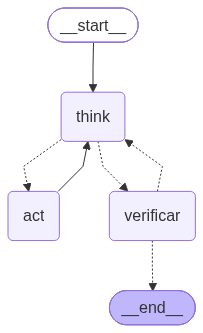

In [20]:
AGENTE_PROMPT = REGLAS + '''

Tienes herramientas sobre el grafo del esquema tenant. Estrategia:
- Procesos y pantallas: buscar con kind=process o kind=form_action, y pasos para el orden exacto.
- Columnas de una tabla: ver_tabla. No supongas nombres de columnas.
- Joins entre tablas: camino_join. Si responde que no hay relación confirmada, dilo así.
- Comparar tenants: ver_tabla o vecinos con tipo_arista=PRESENT_IN.
- Reglas de negocio y tipos de documento: buscar con kind=concept.

Formato de cada turno:
Pensamiento: <qué sabes y qué te falta>
y luego llama una herramienta, o termina con:
Respuesta final: <respuesta corta, con tabla.columna cuando corresponda>'''

SYSTEM_MSG = SystemMessage(content=AGENTE_PROMPT)


class AgentState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]
    final_answer: str
    steps: int
    intentos: int
    errores: list[str]


llm_tools = llm.bind_tools(TOOLS)


def think(state: AgentState) -> dict:
    # Pensamiento: el LLM lee el historial y decide si llama una herramienta o responde
    step = state.get("steps", 0) + 1
    response = llamar_llm([SYSTEM_MSG] + list(state["messages"]), modelo=llm_tools)
    texto = response.content if isinstance(response.content, str) else str(response.content)
    if VERBOSE:
        print(f"\n{'=' * 20} [Paso {step}] {'=' * 20}")
        for linea in texto.splitlines():
            if linea.strip():
                print(f"[LLM] {linea.strip()[:300]}")
    final_answer = state.get("final_answer", "")
    if not response.tool_calls:
        final_answer = texto.split("Respuesta final:", 1)[-1].strip()
    return {"messages": [response], "final_answer": final_answer, "steps": step}


def act(state: AgentState) -> dict:
    # Act + Obs: ejecuta cada herramienta pedida
    tool_messages = []
    for tool_call in state["messages"][-1].tool_calls:
        herramienta = TOOLS_BY_NAME.get(tool_call["name"])
        resultado = herramienta.invoke(tool_call["args"]) if herramienta else f"No existe la herramienta {tool_call['name']}."
        if VERBOSE:
            print(f"[Act] {tool_call['name']}({tool_call['args']})")
            print(f"[Obs] {resultado[:OBS_CHARS]}... ({len(resultado)} caracteres)")
        tool_messages.append(ToolMessage(content=resultado, tool_call_id=tool_call["id"]))
    return {"messages": tool_messages}


def verificar(state: AgentState) -> dict:
    # Verificador determinista: compara la respuesta con el esquema del grafo
    respuesta = state.get("final_answer") or ""
    if not respuesta:
        return {"final_answer": "No consta en el grafo (se alcanzó MAX_STEPS).", "errores": []}
    _, errores, _, errores_join = verificar_esquema(respuesta)
    errores = errores + errores_join
    if VERBOSE:
        print(f"[Verificar] {'sin errores' if not errores else errores}")
    if not errores or state.get("intentos", 0) >= MAX_RETRIES:
        return {"errores": errores}
    aviso = ("Revisión automática contra el esquema: " + "; ".join(errores) + ". "
             "Comprueba con las herramientas (ver_tabla, camino_join) y entrega otra Respuesta final "
             "sin identificadores que no existan. Si no hay relación confirmada, dilo.")
    return {"messages": [HumanMessage(content=aviso)], "errores": errores,
            "intentos": state.get("intentos", 0) + 1, "final_answer": ""}


def despues_de_think(state: AgentState) -> str:
    last = state["messages"][-1]
    limite = MAX_STEPS * (state.get("intentos", 0) + 1)
    if last.tool_calls and state["steps"] < limite:
        return "act"
    return "verificar"


def despues_de_verificar(state: AgentState) -> str:
    # Si verificar dejó la respuesta vacía, pidió un reintento
    return "think" if not state["final_answer"] else END


graph = StateGraph(AgentState)
graph.add_node("think", think)
graph.add_node("act", act)
graph.add_node("verificar", verificar)
graph.set_entry_point("think")
graph.add_conditional_edges("think", despues_de_think, {"act": "act", "verificar": "verificar"})
graph.add_edge("act", "think")
graph.add_conditional_edges("verificar", despues_de_verificar, {"think": "think", END: END})
agent = graph.compile()

try:
    display(Image(agent.get_graph().draw_mermaid_png()))
except Exception as e:   # draw_mermaid_png usa mermaid.ink: sin red, se imprime el texto
    print(agent.get_graph().draw_mermaid())


def agente(pregunta):
    EVIDENCIA.clear()
    res = agent.invoke({"messages": [HumanMessage(content=pregunta)], "final_answer": "",
                        "steps": 0, "intentos": 0, "errores": []},
                       {"recursion_limit": 4 * MAX_STEPS * (MAX_RETRIES + 1)})
    return {"respuesta": res["final_answer"], "evidencia_ids": list(EVIDENCIA),
            "pasos": res["steps"], "reintentos": res["intentos"], "errores_finales": res["errores"]}

### 4.5 Traza de la pregunta ancla

*"Desde un movimiento de kardex, ¿cómo llego al precio de venta del producto?"* (p13). Exige dos saltos (`t4111` → `t4101` → `t4106`) y una columna exacta (`mnPrecioVentaPublico`).

In [21]:
PREGUNTA_ANCLA = df_eval.set_index("id").loc["p13", "pregunta"]
for k in COSTO:
    COSTO[k] = 0
VERBOSE = True
r = agente(PREGUNTA_ANCLA)
print("\n" + "=" * 60)
print("Respuesta:", r["respuesta"])
print("Evidencia:", r["evidencia_ids"])
print(f"Pasos={r['pasos']} reintentos={r['reintentos']} | {COSTO}")


==================== [Paso 1] ====================
[LLM] Pensamiento: Necesito el flujo/proceso desde un movimiento de kardex hasta el precio de venta. Consultaré en el grafo procesos y relaciones desde tablas de kardex hacia tablas de precios/ventas.
[Act] buscar({'consulta': 'kardex movimiento precio de venta', 'kind': 'process', 'domain': 'inventario'})
[Obs] [process:inventario_movimiento] Proceso Mover inventario y reponer. Actor: Usuario de producto. Cómo se entra: Inventario → Movimientos, Transferencias, Bodegas, Consulta, Reposición. Pantalla: kardex. Perfil de menú: 11. El kardex es t4111. Un ingreso manual es IB y un egreso EB. Una transferencia ... (1285 caracteres)
[Act] buscar({'consulta': 'kardex movimiento', 'kind': 'table', 'domain': 'inventario'})
[Obs] [table:t4111] Tabla t4111. Kardex. Dominio inventario. Movimientos de inventario. mnCantidadTrans negativo es egreso. Tipos de orden IB ingreso, EB egreso, TB transferencia enviada, RB recepción. Bodega en szBodega. D

In [22]:
VERBOSE = False
df_prop = medir("agente", agente)
VERBOSE = True

[agente] cargado desde resultados/respuestas_agente.jsonl (gpt-5.4-nano)


## 4B. Reflexion sobre el agente del grafo

Esta sección extiende el agente con el método **Reflexion** (Shinn et al., 2023), siguiendo `s4_p2_reflexion_openai`. Si un intento falla, el agente escribe en lenguaje natural *por qué* falló y *qué hará distinto*. Esa lección se guarda en una **memoria** y se le entrega en el intento siguiente, que empieza con la trayectoria vacía.

| Rol | Símbolo | Qué hace | Nodo |
|---|---|---|---|
| Actor | $M_a$ | Agente ReAct con las 5 herramientas del grafo (sección 4.2) | `think` + `act` |
| Evaluador | $M_e$ | PASS o FAIL del intento, **sin ver la referencia** | `evaluate` |
| Auto-reflexión | $M_{sr}$ | Si falló, escribe una lección accionable | `reflect` |

**Pseudocódigo** (igual que en el curso)

1. $\text{mem} \leftarrow [\ ]$, $t \leftarrow 1$
2. El Actor genera la trayectoria $\tau_t$ con el prompt $s_i + \text{mem}$.
3. El Evaluador calcula $M_e(\tau_t) \in \{\text{PASS}, \text{FAIL}\}$.
4. Si PASS, o si $t = $ `MAX_TRIALS`: terminar.
5. Si FAIL: $sr_t = M_{sr}(\tau_t, M_e(\tau_t))$; $\text{mem} \leftarrow \text{mem} + [sr_t]$; $t \leftarrow t + 1$; volver al paso 2.

**Cambio respecto de `s4_p2`: un evaluador híbrido.** En el curso, $M_e$ es solo un LLM. Aquí tiene dos etapas:

1. **Etapa determinista** (sin costo): `verificar_esquema()` de la sección 4.3. Si la respuesta cita una tabla, una columna o un join que no existe, el intento es FAIL sin llamar al LLM. El motivo lista los identificadores inválidos, y eso le da al Reflector un diagnóstico exacto.
2. **Etapa LLM**: si el esquema está bien, el LLM juzga la respuesta contra la **evidencia** que recuperó el Actor, como en el curso.

El evaluador no conoce la respuesta de referencia: usarla sería hacer trampa, porque después se mide con ella.

**Diferencia con el agente de la sección 4.** Allí el verificador devuelve los errores **dentro de la misma trayectoria**, y el agente corrige sin reiniciar. Reflexion **reinicia la trayectoria** y solo conserva la lección. Además juzga la respuesta completa, no solo los identificadores.

| Artículo | Este notebook |
|---|---|
| Trayectoria $\tau_t$ | `state["messages"]` del intento $t$ (se **reinicia**) |
| Memoria $\text{mem}$ | `state["mem"]` (se **conserva y crece**) |
| $M_e$ | `evaluate`: `verificar_esquema` + LLM contra la evidencia |
| $M_{sr}$ | `reflect`: diagnóstico + plan con llamadas concretas a herramientas |
| $s_i + \text{mem}$ | `AGENTE_PROMPT` de la sección 4.4 + lecciones de `mem` |

De cada ejecución salen **dos sistemas** sin pagar dos veces: `react` (la respuesta del intento 1, un ReAct sin verificador ni memoria) y `reflexion` (la respuesta final).

In [23]:
MAX_TRIALS = 3            # intentos de Reflexion (1 = ReAct puro)
EVIDENCIA_CHARS = 12000   # evidencia máxima que ve el Evaluador


def say(texto=""):
    if VERBOSE:
        print(texto)


def texto_de(mensaje):
    # Texto de un AIMessage, sea str o lista de bloques (Responses API)
    contenido = mensaje.content
    if isinstance(contenido, str):
        return contenido
    return "".join(b.get("text", "") if isinstance(b, dict) else str(b) for b in contenido)


def separar_actor(texto):
    # (pensamiento, respuesta final) del texto del Actor
    respuesta = ""
    if "Respuesta final:" in texto:
        texto, respuesta = texto.split("Respuesta final:", 1)
    pensamiento = texto.split("Pensamiento:", 1)[-1].strip()
    return pensamiento, respuesta.strip()


def evidencia_de(mensajes):
    observaciones = [m.content for m in mensajes if isinstance(m, ToolMessage)]
    texto = "\n\n".join(observaciones) if observaciones else "(el agente no consultó herramientas)"
    return texto[:EVIDENCIA_CHARS]


def trayectoria_de(mensajes, obs_chars=600):
    lineas = []
    for m in mensajes:
        if isinstance(m, AIMessage):
            if texto_de(m).strip():
                lineas.append(f"AGENTE: {texto_de(m).strip()}")
            for tc in m.tool_calls:
                lineas.append(f"HERRAMIENTA: {tc['name']}({tc['args']})")
        elif isinstance(m, ToolMessage):
            lineas.append(f"OBSERVACIÓN: {m.content[:obs_chars]}...")
    return "\n".join(lineas)


def leer_veredicto(texto):
    # Lee 'VEREDICTO: PASS/FAIL' y 'MOTIVO: ...'. Sin formato se asume FAIL
    veredicto = re.search(r"VEREDICTO:\s*\**\s*(PASS|FAIL)", texto, flags=re.IGNORECASE)
    motivo = re.search(r"MOTIVO:\s*(.*)", texto, flags=re.DOTALL)
    paso = bool(veredicto) and veredicto.group(1).upper() == "PASS"
    return paso, (motivo.group(1).strip() if motivo else texto.strip())

### 4B.1 Los tres prompts

- **Actor:** el mismo `AGENTE_PROMPT` del agente de la sección 4, más las lecciones de `mem`.
- **Evaluador:** recibe la pregunta, la evidencia y la respuesta, y contesta en dos líneas fijas (`VEREDICTO`, `MOTIVO`). Aprueba un "No consta" solo si la evidencia de verdad no tiene el dato.
- **Reflector:** recibe la trayectoria, la respuesta y el motivo del fallo, y devuelve diagnóstico + plan con **llamadas concretas** a las herramientas (`ver_tabla('t4106')`, `camino_join('t4111', 't4106')`).

In [24]:
def prompt_actor(mem):
    # s_i + mem: el prompt del agente más las lecciones de los intentos fallidos
    if not mem:
        return AGENTE_PROMPT
    lecciones = "\n".join(f"- Lección del intento {i + 1}: {l}" for i, l in enumerate(mem))
    return (AGENTE_PROMPT + "\n\nYa intentaste esta pregunta y tu respuesta fue REPROBADA.\n"
            "Usa estas lecciones para no repetir los mismos errores:\n" + lecciones)


EVALUADOR_PROMPT = '''Eres un evaluador estricto pero justo de un asistente técnico del esquema tenant del ERP Kerberos.

PREGUNTA:
{pregunta}

EVIDENCIA que el asistente obtuvo de las herramientas del grafo:
{evidencia}

RESPUESTA DEL ASISTENTE:
{respuesta}

Decide FAIL si se cumple ALGUNA de estas condiciones:
- No hay respuesta, o la respuesta no contesta lo que se pregunta (otra tabla, otro proceso, solo una parte de la pregunta).
- La respuesta contradice la evidencia o afirma tablas, columnas, pasos o relaciones que no aparecen en la evidencia.
- La respuesta propone un join que la evidencia no confirma.
- La respuesta dice "No consta", pero la evidencia sí contiene el dato pedido.
- La evidencia trata de otro tema, así que la respuesta no es confiable.
Si la respuesta dice "No consta" y la evidencia de verdad no tiene el dato, decide PASS.
En otro caso decide PASS. No repruebes una respuesta solo por ser breve.

Responde exactamente en dos líneas:
VEREDICTO: PASS o FAIL
MOTIVO: <una oración>'''


REFLECTOR_PROMPT = '''Ayudas a un agente a aprender de un intento fallido. El agente responde preguntas sobre el esquema tenant
del ERP Kerberos con estas herramientas: buscar(consulta, kind, domain), ver_tabla(tabla), vecinos(id, tipo_arista),
camino_join(tabla_a, tabla_b) y pasos(id).

PREGUNTA:
{pregunta}

TRAYECTORIA del intento fallido (pensamientos, herramientas y observaciones):
{trayectoria}

RESPUESTA FINAL del intento:
{respuesta}

MOTIVO DEL EVALUADOR:
{motivo}

Escribe una reflexión corta (máximo 3 oraciones) para el próximo intento:
1. DIAGNÓSTICO: qué paso causó el fallo (búsqueda mal planteada, herramienta equivocada, evidencia ignorada,
   columna supuesta sin ver_tabla, join sin camino_join, respuesta incompleta...).
2. PLAN: qué hacer distinto, con 1 o 2 llamadas concretas a herramientas.
Responde solo con la reflexión.'''


print(prompt_actor(["(ejemplo) Usa ver_tabla('t4106') antes de nombrar la columna del precio."])[-260:])

ta corta, con tabla.columna cuando corresponda>

Ya intentaste esta pregunta y tu respuesta fue REPROBADA.
Usa estas lecciones para no repetir los mismos errores:
- Lección del intento 1: (ejemplo) Usa ver_tabla('t4106') antes de nombrar la columna del precio.


### 4B.2 El estado y los nodos

Como en `s4_p2`, `messages` es una **lista simple, sin `add_messages`**: cada nodo devuelve la lista completa, así que reiniciar la trayectoria es asignar una lista nueva.

| Campo | Ciclo de vida | Significado |
|---|---|---|
| `question`, `mem`, `trial`, `history` | Persisten | Tarea, memoria episódica, intento actual y registro de cada intento |
| `messages`, `steps`, `answer`, `passed`, `critique` | Se reinician | Trayectoria y veredicto del intento actual |

`PRIMER_INTENTO` guarda el costo, el tiempo y la evidencia del intento 1 **antes** de llamar al Evaluador. Con eso se mide el sistema `react` sin ejecutarlo aparte.

In [25]:
class ReflexionState(TypedDict):
    # Persisten entre intentos
    question: str
    mem: list[str]
    trial: int
    history: list[dict]
    # Se reinician en cada intento
    messages: list[BaseMessage]
    steps: int
    answer: str
    passed: bool
    critique: str


PRIMER_INTENTO = {}
_T0 = [0.0]


def start_trial(state: ReflexionState) -> dict:
    # Intento nuevo: trayectoria vacía + prompt del Actor con la memoria
    trial = state["trial"] + 1
    say(f"\n{'#' * 22} INTENTO {trial} de {MAX_TRIALS} {'#' * 22}")
    if not state["mem"]:
        say("[Memoria] Vacía: en este intento el agente es un ReAct normal.")
    else:
        say(f"[Memoria] El Actor recibe {len(state['mem'])} lección(es):")
        for i, leccion in enumerate(state["mem"]):
            say(f"          - (intento {i + 1}) {leccion}")
    messages = [SystemMessage(content=prompt_actor(state["mem"])), HumanMessage(content=state["question"])]
    return {"trial": trial, "messages": messages, "steps": 0, "answer": "", "passed": False, "critique": ""}


def think_r(state: ReflexionState) -> dict:
    # M_a: el Actor lee la trayectoria y decide si llama una herramienta o responde
    step = state["steps"] + 1
    response = llamar_llm(state["messages"], modelo=llm_tools)
    pensamiento, respuesta = separar_actor(texto_de(response))
    say(f"\n  -- [Paso {step}] Actor M_a --")
    say(f"  [Pensamiento] {pensamiento[:300] or '(sin pensamiento escrito)'}")
    if respuesta:
        say(f"  [Respuesta]   {respuesta[:300]}")
    answer = respuesta or ("" if response.tool_calls else texto_de(response).strip())
    return {"messages": state["messages"] + [response], "steps": step, "answer": answer}


def act_r(state: ReflexionState) -> dict:
    # M_a (Act → Obs): ejecuta todas las herramientas pedidas
    tool_messages = []
    for tool_call in state["messages"][-1].tool_calls:
        herramienta = TOOLS_BY_NAME.get(tool_call["name"])
        resultado = herramienta.invoke(tool_call["args"]) if herramienta else f"No existe la herramienta {tool_call['name']}."
        say(f"  [Act] {tool_call['name']}({tool_call['args']})")
        say(f"  [Obs] {resultado[:OBS_CHARS]!r}... ({len(resultado)} caracteres)")
        tool_messages.append(ToolMessage(content=resultado, tool_call_id=tool_call["id"]))
    return {"messages": state["messages"] + tool_messages}


def evaluate(state: ReflexionState) -> dict:
    # M_e híbrido: primero el esquema (gratis), después el LLM contra la evidencia
    if state["trial"] == 1:
        PRIMER_INTENTO.update(respuesta=state["answer"], evidencia=list(EVIDENCIA), costo=dict(COSTO),
                              segundos=round(time.perf_counter() - _T0[0], 2))
    etapa = "esquema"
    if not state["answer"]:
        passed, critique = False, "El agente no produjo respuesta (se acabaron los pasos)."
    else:
        _, errores, _, errores_join = verificar_esquema(state["answer"])
        if errores + errores_join:
            passed = False
            critique = "Identificadores que no existen en el grafo: " + "; ".join(errores + errores_join) + "."
        else:
            etapa = "LLM"
            prompt = EVALUADOR_PROMPT.format(pregunta=state["question"], evidencia=evidencia_de(state["messages"]),
                                             respuesta=state["answer"])
            passed, critique = leer_veredicto(texto_de(llamar_llm([HumanMessage(content=prompt)])))

    say(f"\n  [Evaluador M_e · {etapa}] {'PASS' if passed else 'FAIL'}: {critique}")
    registro = {"trial": state["trial"], "steps": state["steps"], "answer": state["answer"], "passed": passed,
                "etapa": etapa, "critique": critique, "reflection": ""}
    return {"passed": passed, "critique": critique, "history": state["history"] + [registro]}


def reflect(state: ReflexionState) -> dict:
    # M_sr: convierte el fallo en una lección y la agrega a la memoria
    prompt = REFLECTOR_PROMPT.format(pregunta=state["question"], trayectoria=trayectoria_de(state["messages"]),
                                     respuesta=state["answer"] or "(sin respuesta)", motivo=state["critique"])
    leccion = texto_de(llamar_llm([HumanMessage(content=prompt)])).strip()
    say(f"\n  [Reflexión M_sr] {leccion}")
    history = state["history"][:-1] + [{**state["history"][-1], "reflection": leccion}]
    return {"mem": state["mem"] + [leccion], "history": history}


def after_think(state: ReflexionState) -> str:
    if state["messages"][-1].tool_calls and state["steps"] < MAX_STEPS:
        return "act"
    return "evaluate"


def after_evaluate(state: ReflexionState) -> str:
    if state["passed"]:
        say("  [Decisión] PASS → fin.")
        return END
    if state["trial"] >= MAX_TRIALS:
        say(f"  [Decisión] FAIL en el último intento ({MAX_TRIALS}) → fin con la mejor respuesta disponible.")
        return END
    say("  [Decisión] FAIL y quedan intentos → el Reflector analiza el error.")
    return "reflect"

### 4B.3 El grafo

Dos ciclos: el **interno** (ReAct: `think` ⇄ `act`) y el **externo** (Reflexion: `start_trial` → … → `evaluate` → `reflect` → `start_trial`).

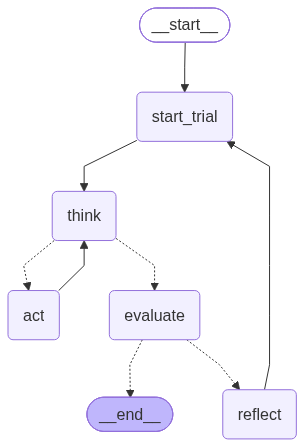

In [26]:
from langgraph.graph import START

g = StateGraph(ReflexionState)
g.add_node("start_trial", start_trial)
g.add_node("think", think_r)
g.add_node("act", act_r)
g.add_node("evaluate", evaluate)
g.add_node("reflect", reflect)
g.add_edge(START, "start_trial")
g.add_edge("start_trial", "think")
g.add_conditional_edges("think", after_think, {"act": "act", "evaluate": "evaluate"})
g.add_edge("act", "think")                        # ciclo interno (ReAct)
g.add_conditional_edges("evaluate", after_evaluate, {"reflect": "reflect", END: END})
g.add_edge("reflect", "start_trial")              # ciclo externo (Reflexion)
reflexion_agent = g.compile()

try:
    display(Image(reflexion_agent.get_graph().draw_mermaid_png()))
except Exception:
    print(reflexion_agent.get_graph().draw_mermaid())


def run_reflexion(pregunta):
    EVIDENCIA.clear()
    PRIMER_INTENTO.clear()
    _T0[0] = time.perf_counter()
    estado = {"question": pregunta, "mem": [], "trial": 0, "history": [],
              "messages": [], "steps": 0, "answer": "", "passed": False, "critique": ""}
    final = reflexion_agent.invoke(estado, {"recursion_limit": MAX_TRIALS * (2 * MAX_STEPS + 3) + 5})
    respuestas = [h["answer"] for h in final["history"] if h["answer"]]
    final["final_answer"] = respuestas[-1] if respuestas else "No consta en el grafo (sin respuesta)."
    return final


def reflexion(pregunta):
    # Envoltorio para medir(): respuesta final + el intento 1 como sistema 'react'
    final = run_reflexion(pregunta)
    p = PRIMER_INTENTO
    return {"respuesta": final["final_answer"], "evidencia_ids": list(EVIDENCIA),
            "intentos": final["trial"],
            "veredictos": " → ".join("PASS" if h["passed"] else "FAIL" for h in final["history"]),
            "etapas": " → ".join(h["etapa"] for h in final["history"]),
            "lecciones": final["mem"],
            "react_respuesta": p.get("respuesta") or "No consta en el grafo (sin respuesta).",
            "react_evidencia": p.get("evidencia", []),
            "react_llamadas": p.get("costo", {}).get("llamadas", 0),
            "react_tokens_in": p.get("costo", {}).get("tokens_in", 0),
            "react_tokens_out": p.get("costo", {}).get("tokens_out", 0),
            "react_segundos": p.get("segundos", 0.0)}


def resumen_reflexion(final, referencia=None):
    print(f"\n{'=' * 64}\nRESUMEN DE REFLEXION\n{'=' * 64}")
    print(f"Intentos usados : {final['trial']} de {MAX_TRIALS} | aprobado por M_e: {final['passed']}")
    for h in final["history"]:
        print(f"\n  Intento {h['trial']} ({h['steps']} pasos) → {'PASS' if h['passed'] else 'FAIL'} [{h['etapa']}]")
        print(f"    Respuesta : {h['answer'] or '(vacía)'}")
        print(f"    Evaluador : {h['critique']}")
        if h["reflection"]:
            print(f"    Reflexión : {h['reflection']}")
    print(f"\nRespuesta final : {final['final_answer']}")
    if referencia is not None:
        print(f"Referencia      : {referencia}  (el agente nunca la ve)")

### 4B.4 Traza con la pregunta ancla y con una trampa

- **p13** (la pregunta ancla de la sección 4.5): ¿el intento 1 ya aprueba, o la etapa de esquema lo reprueba?
- **p23** (trampa): las tablas `luna_turno_*` no están en el grafo. Muestra cómo reacciona el ciclo cuando la evidencia no tiene el dato: el Evaluador debería aprobar un "No consta" bien fundamentado, y el agente no debería inventar columnas.

In [27]:
VERBOSE = True
for k in COSTO:
    COSTO[k] = 0
final_ancla = run_reflexion(PREGUNTA_ANCLA)
resumen_reflexion(final_ancla, ESPERADOS_R.loc["p13", "referencia"])
print(COSTO)


###################### INTENTO 1 de 3 ######################
[Memoria] Vacía: en este intento el agente es un ReAct normal.

  -- [Paso 1] Actor M_a --
  [Pensamiento] (sin pensamiento escrito)
  [Act] buscar({'consulta': 'precio de venta desde movimiento de kardex', 'kind': 'process', 'domain': 'inventario'})
  [Obs] '[process:inventario_movimiento] Proceso Mover inventario y reponer. Actor: Usuario de producto. Cómo se entra: Inventario → Movimientos, Transferencias, Bodegas, Consulta, Reposición. Pantalla: kardex. Perfil de menú: 11. El kardex es t4111. Un ingreso manual es IB y un egreso EB. Una transferencia '... (1285 caracteres)

  -- [Paso 2] Actor M_a --
  [Pensamiento] (sin pensamiento escrito)
  [Act] ver_tabla({'tabla': 't4111'})
  [Obs] 'Tabla t4111: Kardex. Dominio inventario. Movimientos de inventario. mnCantidadTrans negativo es egreso. Tipos de orden IB ingreso, EB egreso, TB transferencia enviada, RB recepción. Bodega en szBodega. Disponibilidad = suma de cantidades.

In [28]:
for k in COSTO:
    COSTO[k] = 0
final_trampa = run_reflexion(ESPERADOS_R.loc["p23", "pregunta"])
resumen_reflexion(final_trampa, ESPERADOS_R.loc["p23", "referencia"])
print(COSTO)
for k, leccion in enumerate(final_trampa["mem"], start=1):
    print(f"Lección {k}: {leccion}")


###################### INTENTO 1 de 3 ######################
[Memoria] Vacía: en este intento el agente es un ReAct normal.

  -- [Paso 1] Actor M_a --
  [Pensamiento] necesito identificar la tabla de “citas” en el módulo turnos y luego listar sus columnas con ver_tabla.
  [Act] buscar({'consulta': 'citas turnos tabla', 'kind': 'table', 'domain': 'turnos'})
  [Obs] '[table:t42011] Tabla t42011. Agenda Kerberos (turnos). Dominio turnos. Documento de turno o cita. PK nroDoc + tipoDoc + companiaDoc + ID. Vacía en las cuatro muestras. El módulo de turnos de Luna no modifica esta tabla; la peluquería puede leerla junto con t0101 y t4101. Clave primaria: nroDoc, tipo'... (2286 caracteres)

  -- [Paso 2] Actor M_a --
  [Pensamiento] (sin pensamiento escrito)
  [Act] ver_tabla({'tabla': 't42011'})
  [Obs] 'Tabla t42011: Agenda Kerberos (turnos). Dominio turnos. Documento de turno o cita. PK nroDoc + tipoDoc + companiaDoc + ID. Vacía en las cuatro muestras. El módulo de turnos de Luna no modif

### 4B.5 Ejecución sobre las 25 preguntas

Una sola ejecución da los dos sistemas: `react` (intento 1, con su propio costo) y `reflexion` (respuesta final, con el costo total del Actor, el Evaluador y el Reflector).

In [29]:
VERBOSE = False
df_refl = medir("reflexion", reflexion)
VERBOSE = True

df_react = df_refl.assign(
    respuesta=df_refl["react_respuesta"], evidencia_ids=df_refl["react_evidencia"],
    llamadas=df_refl["react_llamadas"], tokens_in=df_refl["react_tokens_in"],
    tokens_out=df_refl["react_tokens_out"], segundos=df_refl["react_segundos"],
)[["id", "tipo", "pregunta", "referencia", "modelo", "segundos", "llamadas", "tokens_in", "tokens_out",
   "respuesta", "evidencia_ids"]]

ultimo = df_refl["veredictos"].str.split(" → ").str[-1]
print(f"Aprobadas en el intento 1             : {(df_refl['intentos'].eq(1) & ultimo.eq('PASS')).sum()}")
print(f"Necesitaron reflexión                 : {(df_refl['intentos'] > 1).sum()}")
print(f"Aprobadas tras reflexionar            : {(df_refl['intentos'].gt(1) & ultimo.eq('PASS')).sum()}")
print(f"Reprobadas en todos los intentos      : {(~df_refl['veredictos'].str.contains('PASS')).sum()}")
print(f"Fallos detectados por la etapa esquema: {df_refl['etapas'].str.count('esquema').sum()} (sin costo de LLM)")

[reflexion] cargado desde resultados/respuestas_reflexion.jsonl (gpt-5.4-nano)
Aprobadas en el intento 1             : 12
Necesitaron reflexión                 : 13
Aprobadas tras reflexionar            : 8
Reprobadas en todos los intentos      : 5
Fallos detectados por la etapa esquema: 1 (sin costo de LLM)


## 5. Evaluación comparativa

Las mismas 25 preguntas, el mismo LLM generador, el mismo prompt de reglas y el mismo juez para los cinco sistemas. Si RAGAS deja filas en NaN (timeout o falta de crédito), basta con volver a ejecutar la celda de RAGAS: solo reevalúa esas filas.

**Métricas deterministas (sin juez, sin costo)**, calculadas con las funciones del verificador:

| Métrica | Definición |
|---|---|
| `precision_esquema` | identificadores citados que existen en el grafo / identificadores citados |
| `joins_validos` | joins `A.x = B.y` citados que están en `LINKS_VALIDOS` / joins citados |
| `recall_evidencia` | `evidencia_ids` de la referencia que el sistema recuperó o visitó |
| `cobertura_ids` | `identificadores_esperados` que aparecen en la respuesta |
| `abstencion` | en las 3 preguntas cuya referencia es "No consta", la respuesta también lo dice |
| `falsa_abstencion` | en las otras 22, la respuesta dice "No consta" aunque sí había respuesta |

**Métricas RAGAS** (juez `JUEZ_MODEL`): `answer_correctness` (**métrica principal**), `factual_correctness` y la métrica propia `reference_coverage` de `s4_p1`.

In [30]:
SISTEMAS = {"rag_simple": df_simple, "linea_base": df_base, "react": df_react,
            "agente": df_prop, "reflexion": df_refl}
ESPERADOS = df_eval.set_index("id")


def cobertura(respuesta, esperados):
    if not esperados:
        return np.nan
    def presente(x):
        if "." in x:
            t, c = x.split(".", 1)
            return x in respuesta or (t in respuesta and c in respuesta)
        return x in respuesta
    return sum(presente(x) for x in esperados) / len(esperados)


def metricas_deterministas(df):
    filas = []
    for r in df.itertuples():
        q = ESPERADOS.loc[r.id]
        n_ids, errores, n_joins, errores_join = verificar_esquema(r.respuesta)
        dice_no_consta = "no consta" in r.respuesta.lower()
        sin_respuesta = q.referencia.startswith("No consta")
        filas.append({
            "id": r.id,
            "precision_esquema": (n_ids - len(errores)) / n_ids if n_ids else np.nan,
            "joins_validos": (n_joins - len(errores_join)) / n_joins if n_joins else np.nan,
            "recall_evidencia": len(set(q.evidencia_ids) & set(r.evidencia_ids)) / len(q.evidencia_ids),
            "cobertura_ids": cobertura(r.respuesta, q.identificadores_esperados),
            "abstencion": float(dice_no_consta) if sin_respuesta else np.nan,
            "falsa_abstencion": np.nan if sin_respuesta else float(dice_no_consta),
            "errores_esquema": "; ".join(errores + errores_join),
        })
    return pd.DataFrame(filas)


DET = {nombre: df.merge(metricas_deterministas(df), on="id") for nombre, df in SISTEMAS.items()}
display(DET["agente"][["id", "tipo", "precision_esquema", "joins_validos", "recall_evidencia",
                       "cobertura_ids", "errores_esquema"]].head(10))

,id,tipo,precision_esquema,joins_validos,recall_evidencia,cobertura_ids,errores_esquema
0,p01,Proceso,1.0,NaN,1.0,1.00,
1,p02,Proceso,1.0,NaN,1.0,0.20,
2,p03,Proceso,1.0,NaN,0.5,0.50,
3,p04,Proceso,NaN,NaN,1.0,0.00,
4,p05,Formulario,1.0,NaN,1.0,1.00,
5,p06,Formulario,NaN,NaN,1.0,NaN,
6,p07,Esquema,1.0,NaN,1.0,1.00,
7,p08,Esquema,1.0,1.0,1.0,1.00,
8,p09,Esquema,1.0,NaN,1.0,1.00,
9,p10,Esquema,1.0,NaN,0.5,0.75,


In [31]:
from ragas import evaluate
from ragas.metrics import AnswerCorrectness, FactualCorrectness, MetricWithLLM, SingleTurnMetric
from ragas.metrics.base import MetricType
from ragas.dataset_schema import SingleTurnSample
from ragas.llms import LangchainLLMWrapper
from ragas.embeddings import LangchainEmbeddingsWrapper
from ragas.run_config import RunConfig
from langchain_core.prompt_values import StringPromptValue
from dataclasses import dataclass, field
from datasets import Dataset
import typing as t

llm_juez = ChatOpenAI(model=JUEZ_MODEL, api_key=OPENAI_KEY, temperature=0)
ragas_llm = LangchainLLMWrapper(llm_juez)
ragas_embeddings = LangchainEmbeddingsWrapper(embeddings)

answer_correctness = AnswerCorrectness(llm=ragas_llm, embeddings=ragas_embeddings)
answer_correctness.name = "answer_correctness"
factual_correctness = FactualCorrectness(llm=ragas_llm)
factual_correctness.name = "factual_correctness"


@dataclass
class ReferenceCoverage(MetricWithLLM, SingleTurnMetric):
    # Proporción del dato principal de la referencia que aparece en la respuesta (0 a 1), como en s4_p1
    name: str = "reference_coverage"
    _required_columns: t.Dict[MetricType, t.Set[str]] = field(
        default_factory=lambda: {MetricType.SINGLE_TURN: {"response", "reference"}}
    )

    async def _single_turn_ascore(self, sample: SingleTurnSample, callbacks) -> float:
        prompt_text = f'''You are checking whether a response contains the key fact from a reference.

Reference (the key fact the response must contain):
{sample.reference}

Response (the actual answer being evaluated):
{sample.response}

Does the response contain the main fact stated in the reference?
Ignore any extra information in the response — only check whether the reference's main fact is present.
Answer only with the proportion that is present: a number between 0 and 1.'''
        result = await self.llm.generate(StringPromptValue(text=prompt_text), n=1, temperature=0)
        match = re.search(r"\d+(?:\.\d+)?", result.generations[0][0].text)
        return min(1.0, float(match.group())) if match else np.nan


reference_coverage = ReferenceCoverage(llm=ragas_llm)
METRICAS_RAGAS = [answer_correctness, factual_correctness, reference_coverage]


# Pocas llamadas en paralelo y timeout largo: evita los TimeoutError y los 429 por ráfagas
RUN_CONFIG = RunConfig(timeout=240, max_retries=5, max_wait=60, max_workers=4)
COLS_RAGAS = ["answer_correctness", "factual_correctness", "reference_coverage"]


def _ragas(df):
    dataset = Dataset.from_dict({"user_input": df["pregunta"].tolist(),
                                 "response": df["respuesta"].tolist(),
                                 "reference": df["referencia"].tolist()})
    res = evaluate(dataset, metrics=METRICAS_RAGAS, run_config=RUN_CONFIG).to_pandas()
    res.insert(0, "id", df["id"].values)
    res["juez"] = JUEZ_MODEL
    return res


def evaluar_ragas(nombre, df):
    # Reutiliza lo guardado si es del mismo juez y de las mismas respuestas; solo reevalúa las filas con NaN
    ruta = OUT_DIR / f"ragas_{nombre}.csv"
    if ruta.exists() and not RECALCULAR:
        guardado = pd.read_csv(ruta)
        mismas = (guardado.get("juez", pd.Series(["?"])).iloc[0] == JUEZ_MODEL
                  and guardado["response"].fillna("").tolist() == df["respuesta"].tolist())
        if mismas:
            faltan = guardado[COLS_RAGAS].isna().any(axis=1)
            if not faltan.any():
                return guardado
            print(f"[{nombre}] reevaluando {faltan.sum()} filas con NaN")
            nuevo = _ragas(df[df["id"].isin(guardado.loc[faltan, "id"])])
            guardado = pd.concat([guardado[~faltan], nuevo]).set_index("id").loc[df["id"]].reset_index()
            guardado.to_csv(ruta, index=False)
            return guardado
    res = _ragas(df)
    res.to_csv(ruta, index=False)
    return res


RAGAS = {nombre: evaluar_ragas(nombre, df) for nombre, df in SISTEMAS.items()}
for nombre, r in RAGAS.items():
    n_nan = int(r[COLS_RAGAS].isna().any(axis=1).sum())
    if n_nan:
        print(f"ATENCIÓN [{nombre}]: {n_nan} filas sin puntaje RAGAS (timeout o sin crédito). Vuelve a ejecutar esta celda.")
# Aprox. 5 a 8 minutos la primera vez

/Users/peluchito/Desktop/procesamientoLenguajeNatural/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [32]:
COLS_DET = ["precision_esquema", "joins_validos", "recall_evidencia", "cobertura_ids", "abstencion", "falsa_abstencion"]

TODO = {n: DET[n].merge(RAGAS[n][["id"] + COLS_RAGAS], on="id") for n in SISTEMAS}
for n, df in TODO.items():
    df["tokens"] = df["tokens_in"] + df["tokens_out"]

resumen = pd.DataFrame({
    n: {**df[COLS_RAGAS + COLS_DET].mean().to_dict(),
        "llamadas/preg": df["llamadas"].mean(),
        "tokens/preg": df["tokens"].mean(),
        "segundos/preg": df["segundos"].mean(),
        "tokens_total": df["tokens"].sum(),
        "segundos_total": df["segundos"].sum()}
    for n, df in TODO.items()
}).T
resumen.to_csv(OUT_DIR / "resumen_v1_en_v4.csv")
display(resumen.round(3))
print(f"Costo común de indexar: ≈ {TOKENS_CORPUS:,} tokens de embeddings (una sola vez)")

,answer_correctness,factual_correctness,reference_coverage,precision_esquema,joins_validos,recall_evidencia,cobertura_ids,abstencion,falsa_abstencion,llamadas/preg,tokens/preg,segundos/preg,tokens_total,segundos_total
rag_simple,0.482,0.522,0.780,0.978,1.0,0.664,0.707,0.667,0.364,1.00,2176.36,1.910,54409.0,47.74
linea_base,0.461,0.479,0.820,1.000,1.0,0.797,0.817,0.667,0.182,1.00,4174.80,2.156,104370.0,53.91
react,0.466,0.344,0.744,0.999,1.0,0.639,0.784,0.667,0.227,3.08,7480.60,4.995,187015.0,124.88
agente,0.517,0.444,0.820,1.000,1.0,0.692,0.780,0.667,0.182,3.28,7145.84,4.197,178646.0,104.92
reflexion,0.458,0.366,0.740,1.000,1.0,0.679,0.711,0.333,0.273,8.04,21282.16,11.879,532054.0,296.97


Costo común de indexar: ≈ 48,729 tokens de embeddings (una sola vez)


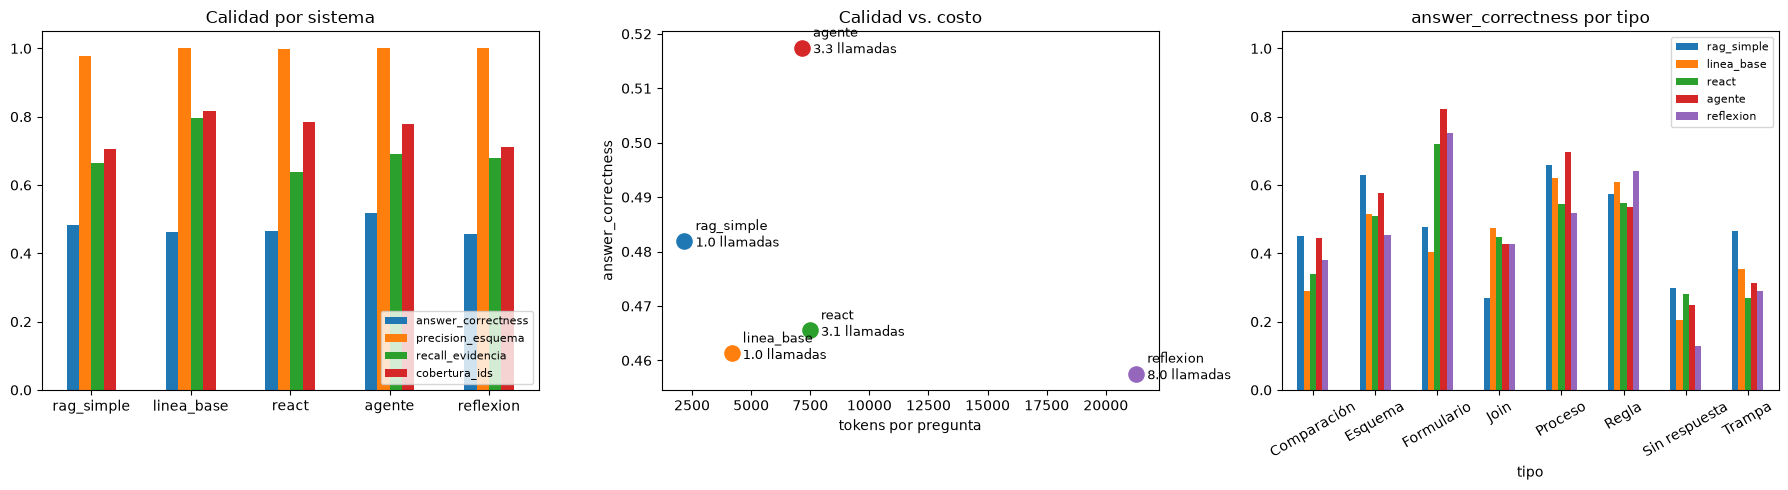

In [33]:
fig, ejes = plt.subplots(1, 3, figsize=(18, 5))
nombres = list(TODO)

# 1) Calidad por sistema
resumen.loc[nombres, ["answer_correctness", "precision_esquema", "recall_evidencia", "cobertura_ids"]].plot.bar(ax=ejes[0], rot=0)
ejes[0].set_title("Calidad por sistema")
ejes[0].set_ylim(0, 1.05)
ejes[0].legend(fontsize=8, loc="lower right")

# 2) Calidad vs. costo
for n in nombres:
    ejes[1].scatter(resumen.loc[n, "tokens/preg"], resumen.loc[n, "answer_correctness"], s=120)
    ejes[1].annotate(f"{n}\n{resumen.loc[n, 'llamadas/preg']:.1f} llamadas",
                     (resumen.loc[n, "tokens/preg"], resumen.loc[n, "answer_correctness"]),
                     textcoords="offset points", xytext=(8, -4), fontsize=9)
ejes[1].set_xlabel("tokens por pregunta")
ejes[1].set_ylabel("answer_correctness")
ejes[1].set_title("Calidad vs. costo")

# 3) Calidad por tipo de pregunta
pd.DataFrame({n: TODO[n].groupby("tipo")["answer_correctness"].mean() for n in nombres}).plot.bar(ax=ejes[2], rot=30)
ejes[2].set_title("answer_correctness por tipo")
ejes[2].set_ylim(0, 1.05)
ejes[2].legend(fontsize=8)

plt.tight_layout()
plt.savefig(OUT_DIR / "comparacion_v1_en_v4.png", dpi=150)
plt.show()

### Análisis por pregunta

Diferencia de `answer_correctness` entre el agente y la línea base, y los errores de esquema que quedaron en cada respuesta.

In [34]:
cmp = (TODO["linea_base"][["id", "tipo", "answer_correctness", "precision_esquema", "errores_esquema"]]
       .merge(TODO["agente"][["id", "answer_correctness", "precision_esquema", "errores_esquema", "pasos", "reintentos"]],
              on="id", suffixes=("_base", "_agente")))
cmp["delta"] = cmp["answer_correctness_agente"] - cmp["answer_correctness_base"]
display(cmp.sort_values("delta")[["id", "tipo", "answer_correctness_base", "answer_correctness_agente", "delta",
                                  "precision_esquema_base", "precision_esquema_agente", "pasos", "reintentos"]])

print("Gana el agente:", (cmp["delta"] > 0.05).sum(), "| empata:", (cmp["delta"].abs() <= 0.05).sum(),
      "| pierde:", (cmp["delta"] < -0.05).sum())
print("Preguntas donde el verificador pidió reintento:", int((cmp["reintentos"] > 0).sum()))

,id,tipo,answer_correctness_base,answer_correctness_agente,delta,precision_esquema_base,precision_esquema_agente,pasos,reintentos
13,p14,Join,0.914896,0.436621,-0.478276,1.0,1.0,3,0
14,p15,Join,0.462731,0.105996,-0.356735,1.0,NaN,6,0
6,p07,Esquema,0.411055,0.180314,-0.230741,1.0,1.0,4,0
0,p01,Proceso,0.792581,0.563295,-0.229286,1.0,1.0,6,0
1,p02,Proceso,0.781831,0.558368,-0.223464,1.0,1.0,3,0
15,p16,Regla,0.610473,0.509294,-0.101179,1.0,1.0,4,0
17,p18,Regla,0.596949,0.504950,-0.091999,1.0,1.0,3,0
21,p22,Trampa,0.538260,0.464153,-0.074108,1.0,1.0,2,0
16,p17,Regla,0.619732,0.595650,-0.024082,1.0,1.0,2,0
22,p23,Trampa,0.172054,0.161629,-0.010425,1.0,1.0,3,0


Gana el agente: 13 | empata: 4 | pierde: 8
Preguntas donde el verificador pidió reintento: 0


In [35]:
# Caso inspeccionado a fondo: la pregunta donde más gana y donde más pierde el agente
for etiqueta, fila in [("Más gana", cmp.loc[cmp["delta"].idxmax()]), ("Más pierde", cmp.loc[cmp["delta"].idxmin()])]:
    q = ESPERADOS.loc[fila["id"]]
    print(f"===== {etiqueta}: {fila['id']} ({q.tipo}) | delta={fila['delta']:+.2f}")
    print("Pregunta:  ", q.pregunta)
    print("Referencia:", q.referencia)
    for n in ("linea_base", "agente"):
        r = TODO[n].set_index("id").loc[fila["id"]]
        print(f"\n[{n}] {r['respuesta']}")
        print(f"    evidencia={r['evidencia_ids']}")
        print(f"    errores de esquema: {r['errores_esquema'] or 'ninguno'}")
    print()

===== Más gana: p06 (Formulario) | delta=+0.61
Pregunta:   ¿Qué pestañas tiene el formulario de factura y qué se llena en la pestaña Negociación?
Referencia: Tiene tres pestañas: Detalle, Información adicional y Negociación. En Negociación se indica Condición de pago, Tipo pago y Monto, y se usa Agregar pago, Completar con efectivo o Completar con crédito. Si el origen trae anticipo, la línea CRUCE DE ANTICIPO va bloqueada.

[linea_base] El formulario **factura** tiene estas pestañas:
- **Detalle**
- **Información adicional**
- **Negociación**

En la pestaña **Negociación** se llena:
- **Condición de pago**
- **Tipo pago**
- **Monto** (y desde allí se **Agrega pago** / **Completar con efectivo** / **Completar con crédito**)

Además, si el origen trae **anticipo** la línea **CRUCE DE ANTICIPO** queda **bloqueada**.
    evidencia=['form_action:factura.registrar', 'process:venta_factura', 'form_action:cotizacion.consultar', 'form_action:factura.actualizar', 'form_action:nota_credito.consu

### ¿Dónde cambió algo la reflexión?

Solo en las preguntas con más de un intento puede diferir la respuesta. La tabla compara el intento 1 (`react`) con la respuesta final (`reflexion`). Después se mide qué tan confiable fue el Evaluador: cuántas veces **aprobó una respuesta incorrecta** o **reprobó una correcta**, tomando `answer_correctness ≥ 0.6` como criterio de acierto.

In [36]:
cambios = (TODO["react"][["id", "tipo", "respuesta", "answer_correctness", "precision_esquema"]]
           .merge(TODO["reflexion"][["id", "respuesta", "answer_correctness", "precision_esquema",
                                     "intentos", "veredictos", "etapas"]],
                  on="id", suffixes=("_react", "_reflexion")))
cambios["delta"] = cambios["answer_correctness_reflexion"] - cambios["answer_correctness_react"]
con_reflexion = cambios[cambios["intentos"] > 1]
print(f"Preguntas con más de un intento: {len(con_reflexion)} de {len(cambios)}")
print(f"Mejoran: {(con_reflexion['delta'] > 0.05).sum()} | igual: {(con_reflexion['delta'].abs() <= 0.05).sum()} "
      f"| empeoran: {(con_reflexion['delta'] < -0.05).sum()}")
with pd.option_context("display.max_colwidth", 90):
    display(con_reflexion[["id", "tipo", "veredictos", "etapas", "answer_correctness_react",
                           "answer_correctness_reflexion", "delta", "respuesta_react", "respuesta_reflexion"]])

# Confiabilidad del Evaluador M_e: su veredicto final contra la referencia que no vio
aprobada = cambios["veredictos"].str.split(" → ").str[-1].eq("PASS")
correcta = cambios["answer_correctness_reflexion"] >= 0.6
display(pd.crosstab(aprobada.map({True: "M_e: PASS", False: "M_e: FAIL"}),
                    correcta.map({True: "correcta (≥0.6)", False: "incorrecta"})))
print("Falsos PASS:", int((aprobada & ~correcta).sum()), "| Falsos FAIL:", int((~aprobada & correcta).sum()))

Preguntas con más de un intento: 13 de 25
Mejoran: 6 | igual: 1 | empeoran: 6


,id,tipo,veredictos,etapas,answer_correctness_react,answer_correctness_reflexion,delta,respuesta_react,respuesta_reflexion
0,p01,Proceso,FAIL → FAIL → PASS,LLM → LLM → LLM,0.480231,0.670642,0.190411,"Para anular una factura (proceso **process:venta_anular**), el sistema marca el compro...","Para **anular una factura (FT)**, se usa el proceso **process:venta_anular** (Ventas →..."
2,p03,Proceso,FAIL → PASS,LLM → LLM,0.929508,0.521255,-0.408252,Para pasar stock de una bodega a otra en Kerberos (Luna):\n\n1) Ve a **Inventario → Tr...,"Para transferir stock de **una bodega a otra**, en Luna debes registrar una **transfer..."
4,p05,Formulario,FAIL → FAIL → FAIL,LLM → LLM → LLM,0.672272,0.773587,0.101314,El formulario **cierre_caja.registrar** pide para la **apertura**: \n- **Monto** \n-...,"El formulario **cierre_caja.registrar** pide para **Apertura**: **Monto**, **Tipo de p..."
7,p08,Esquema,FAIL → PASS,LLM → LLM,0.757857,0.715009,-0.042848,El **precio de venta** (PVP) está en la tabla **t4106.mnPrecioVentaPublico**. \n\nLa ...,"- **Precio de venta (PVP) de un producto:** en **t4106.mnPrecioVentaPublico**, asociad..."
10,p11,Join,FAIL → FAIL → FAIL,LLM → LLM → LLM,0.474476,0.409394,-0.065082,Une la obligación de cartera con el cliente usando **t03b11.nroDireccion** contra **t0...,Une la obligación de cartera `t03b11` con la ficha del cliente/persona `t0101` por:\n-...
12,p13,Join,FAIL → PASS,LLM → LLM,0.548377,0.313315,-0.235062,El precio de venta (PVP) del producto no se “calcula” desde el movimiento de t4111: se...,"En un movimiento de kardex (`t4111`), el precio de venta del producto se obtiene consu..."
14,p15,Join,FAIL → PASS,LLM → LLM,0.367624,0.657549,0.289925,Usa la clave `t4101.mnCodigoCorto` para enlazar la línea de venta con el maestro de pr...,Une la línea de venta **t57011z1** con el maestro de productos **t4101** así: \n- **t...
17,p18,Regla,FAIL → FAIL → FAIL,LLM → LLM → LLM,0.647246,0.909449,0.262204,"El tipo de documento es **`NX` (Nota de crédito de ventas)**, donde **`t57011z1.szInvo...",Se guarda con **t57011z1.szDocumentType = NX** (**Nota de crédito de ventas**).
18,p19,Comparación,FAIL → PASS,LLM → LLM,0.399248,0.082952,-0.316296,"En el grafo, las tablas que aparecen **solo en Lifecolor** (no en los demás tenants pr...",No consta en el grafo ninguna tabla que exista **solo** en Lifecolor (todas las tablas...
19,p20,Comparación,FAIL → FAIL → FAIL,LLM → LLM → LLM,0.121665,0.565835,0.444169,"En la muestra, **t57011a no existe** en el tenant **`dveloper_lifecolor`**, **`dvelope...","En la muestra mostrada, **no consta ningún tenant** donde falte `t57011a`: la tabla ap..."


answer_correctness_reflexion,correcta (≥0.6),incorrecta
veredictos,,
M_e: FAIL,2,3
M_e: PASS,4,16


Falsos PASS: 16 | Falsos FAIL: 2


### Variabilidad del juez (opcional)

El juez es un LLM: dos evaluaciones de las mismas respuestas pueden diferir. Esta celda repite `answer_correctness` dos veces más sobre el agente y reporta la desviación. Cuesta unas 50 llamadas al juez.

In [37]:
CORRER_VARIABILIDAD = False
if CORRER_VARIABILIDAD:
    corridas = [RAGAS["agente"]["answer_correctness"].mean()]
    ds = Dataset.from_dict({"user_input": df_prop["pregunta"].tolist(), "response": df_prop["respuesta"].tolist(),
                            "reference": df_prop["referencia"].tolist()})
    for _ in range(2):
        corridas.append(evaluate(ds, metrics=[answer_correctness], run_config=RUN_CONFIG).to_pandas()["answer_correctness"].mean())
    print(f"answer_correctness del agente en 3 corridas: {np.round(corridas, 3)} | desviación={np.std(corridas):.3f}")

## 5B. Versión 2: diagnóstico, mejoras y entrenamiento

La sección 5 mide Reflexion v1. Esta sección **lee esos resultados, identifica qué falla, propone una mejora para cada falla y la mide**: con las mismas 25 preguntas de prueba y, sobre todo, con un **conjunto reservado** de 12 preguntas nuevas que no se usó para diseñar nada.

### 5B.1 Diagnóstico de la v1 con sus propios números

In [38]:
diag = (TODO["react"][["id", "tipo", "respuesta", "answer_correctness"]]
        .merge(TODO["reflexion"][["id", "respuesta", "answer_correctness", "intentos", "veredictos"]],
               on="id", suffixes=("_react", "_refl")))
diag["referencia"] = diag["id"].map(ESPERADOS["referencia"])
diag["paso_final"] = diag["veredictos"].str.split(" → ").str[-1].eq("PASS")
diag["correcta"] = diag["answer_correctness_refl"] >= 0.6
abstiene = lambda s: s.str.lower().str.contains("no consta|^no[.,]", regex=True)

print("1) Evaluador M_e de la v1 (veredicto final vs. referencia):")
print(f"   falsos PASS = {int((diag.paso_final & ~diag.correcta).sum())}, "
      f"falsos FAIL = {int((~diag.paso_final & diag.correcta).sum())}, "
      f"aciertos = {int((diag.paso_final == diag.correcta).sum())} de {len(diag)}")

perdidas = diag[abstiene(diag["respuesta_react"]) & ~abstiene(diag["respuesta_refl"])
                & diag["referencia"].str.lower().str.match("no")]
print(f"2) Abstenciones correctas que la reflexión convirtió en otra respuesta: {perdidas['id'].tolist()}")

empeoran = diag[(diag["intentos"] > 1) & (diag["answer_correctness_refl"] < diag["answer_correctness_react"] - 0.05)]
print(f"3) Preguntas donde reflexionar empeoró la respuesta: {empeoran['id'].tolist()} "
      f"(sin ningún PASS: {empeoran[~empeoran.paso_final]['id'].tolist()})")

largo = TODO["reflexion"]["respuesta"].str.len().mean() / ESPERADOS["referencia"].str.len().mean()
print(f"4) Las respuestas de reflexion miden {largo:.1f}× la referencia: más afirmaciones no pedidas bajan factual/answer_correctness")

por_tipo = pd.DataFrame({n: TODO[n].groupby("tipo")["answer_correctness"].mean() for n in ["react", "reflexion"]})
print("5) answer_correctness por tipo (los más bajos):")
display(por_tipo.sort_values("reflexion").head(4).round(2))

lecciones = [l for ls in TODO["reflexion"].get("lecciones", pd.Series(dtype=object)).dropna() for l in ls]
genericas = sum(bool(re.search(r"sin (verificar|confirmar|contrastar)|evidencia adicional|asum", l, re.I)) for l in lecciones)
print(f"6) Lecciones de la v1 que solo piden 'verificar más': {genericas} de {len(lecciones)}; "
      "ninguna se reutiliza en otra pregunta")

1) Evaluador M_e de la v1 (veredicto final vs. referencia):
   falsos PASS = 16, falsos FAIL = 2, aciertos = 7 de 25
2) Abstenciones correctas que la reflexión convirtió en otra respuesta: ['p25']
3) Preguntas donde reflexionar empeoró la respuesta: ['p03', 'p11', 'p13', 'p19', 'p22', 'p25'] (sin ningún PASS: ['p11', 'p25'])
4) Las respuestas de reflexion miden 2.1× la referencia: más afirmaciones no pedidas bajan factual/answer_correctness
5) answer_correctness por tipo (los más bajos):


,react,reflexion
tipo,,
Sin respuesta,0.28,0.13
Trampa,0.27,0.29
Comparación,0.34,0.38
Join,0.45,0.43


6) Lecciones de la v1 que solo piden 'verificar más': 17 de 19; ninguna se reutiliza en otra pregunta


### 5B.2 De cada falla a una mejora

| # | Falla observada en la v1 | Mejora en la v2 | Dónde |
|---|---|---|---|
| 1 | El Evaluador reprueba respuestas bien fundamentadas ("falta verificar") y aprueba otras que no lo están | Evaluador con **criterio por afirmación**: cada tabla, columna, paso o join debe estar en la evidencia; se prohíbe reprobar "por falta de verificación adicional". Conoce las **mismas reglas** que el Actor. Usa un modelo más capaz (`EVAL_MODEL`) que el Actor | `EVALUADOR_V2` |
| 2 | La reflexión convierte un "No consta" o un "No" correcto en una respuesta inventada | Regla explícita de abstención para preguntas sobre **filas** (conteos, clientes concretos, saldos), que el Evaluador también aplica | `REGLAS_V2`, `EVALUADOR_V2` |
| 3 | Si ningún intento aprueba, se devuelve el último, a menudo peor que el primero | Se devuelve el primer intento **sin errores de esquema** | `seleccionar_respuesta` |
| 4 | Comparaciones entre tenants mal leídas desde `ver_tabla` | Herramienta determinista `presencia_tablas` (MRKL): presencia y **ausencia** por tenant, y tablas exclusivas | `presencia_tablas` |
| 5 | Respuestas del doble de largo, con afirmaciones no pedidas | Formato de 1 a 4 líneas, solo lo preguntado; una pregunta Sí/No empieza con Sí o No; un "No consta" dice el motivo | `AGENTE_PROMPT_V2` |
| 6 | Lecciones genéricas que mueren con cada pregunta | **Entrenamiento**: Reflexion sobre 40 preguntas nuevas con un evaluador que sí ve la referencia (permitido, porque no se evalúa con ellas). El Reflector extrae una **regla general** por fallo y una llamada final las consolida en un manual de ≤ 8 reglas que el Actor recibe desde el intento 1 | `entrenar()` |
| 7 | El agente recupera menos evidencia que la línea base (recall 0,70 vs 0,80) | **Pre-recuperación**: el primer mensaje incluye los ids y títulos de los 8 documentos más parecidos | `start_trial_v2` |

**Riesgo de sobreajuste.** Las fallas 1–5 se diagnosticaron sobre las 25 preguntas de prueba, así que mejorar en ellas no basta como evidencia. Por eso se agregan dos conjuntos nuevos:

| Conjunto | Archivo | n | Uso |
|---|---|---|---|
| Prueba | `eval/preguntas.jsonl` | 25 | El mismo de la sección 5 (ya visto al diagnosticar) |
| Entrenamiento | `eval/preguntas_entrenamiento.jsonl` | 40 | Solo para aprender las reglas. Nunca se evalúa con él. Las 24 últimas (e17–e40) son más difíciles: varias partes, joins de dos saltos, un join sin relación confirmada y trampas Sugar/tenant |
| Reservado | `eval/preguntas_holdout.jsonl` | 12 | No se usó para diseñar nada. Mide si las mejoras **generalizan** |

In [39]:
EVAL_MODEL = os.getenv("EVAL_MODEL", "gpt-5.4-mini")   # Evaluador, Reflector y consolidación (más capaz que el Actor)
MAX_REGLAS = 8
N_PRECANDIDATOS = 8

llm_eval = ChatOpenAI(model=EVAL_MODEL, api_key=OPENAI_KEY, temperature=0) if BACKEND == "openai" else llm

df_train = pd.read_json("eval/preguntas_entrenamiento.jsonl", lines=True)
df_holdout = pd.read_json("eval/preguntas_holdout.jsonl", lines=True)
for nombre, d in [("entrenamiento", df_train), ("reservado", df_holdout)]:
    faltan = [(q.id, e) for q in d.itertuples() for e in q.evidencia_ids if e not in DOC_POR_ID]
    assert not faltan, faltan
    print(f"{nombre}: {len(d)} preguntas | {d['tipo'].value_counts().to_dict()}")

# Las métricas deterministas buscan la referencia por id en los tres conjuntos
ESPERADOS = pd.concat([df_eval, df_train, df_holdout]).set_index("id")
print("Generador:", LLM_MODEL, "| Evaluador/Reflector:", EVAL_MODEL, "| Juez RAGAS:", JUEZ_MODEL)

entrenamiento: 40 preguntas | {'Proceso': 9, 'Formulario': 7, 'Join': 7, 'Regla': 5, 'Comparación': 4, 'Trampa': 4, 'Esquema': 2, 'Sin respuesta': 2}
reservado: 12 preguntas | {'Proceso': 3, 'Esquema': 2, 'Join': 2, 'Formulario': 1, 'Regla': 1, 'Comparación': 1, 'Trampa': 1, 'Sin respuesta': 1}
Generador: gpt-5.4-nano | Evaluador/Reflector: gpt-5.4-mini | Juez RAGAS: gpt-4o-mini


### 5B.3 Herramienta nueva: `presencia_tablas`

Calcula desde las aristas `PRESENT_IN` lo que el agente leía mal en `ver_tabla`: en qué tenants está una tabla, en cuáles **no** está, y qué tablas son exclusivas de un tenant.

In [40]:
TENANTS = [m["base"] for m in manifest["samples"]]
CORTO = {b: b.replace("dveloper_", "") for b in TENANTS}


def _tenant(nombre):
    nombre = nombre.lower().strip()
    return next((b for b in TENANTS if nombre in b or CORTO[b] in nombre), None)


@tool
def presencia_tablas(tabla: str = "", tenant: str = "") -> str:
    '''Presencia de tablas en los cuatro tenants de la muestra (lifecolor, indupan, garage84, labclinico1).
    Con tabla: en qué tenants está (con filas estimadas) y en cuáles NO está.
    Con tenant: qué tablas existen SOLO en ese tenant y cuáles le faltan respecto de los demás.'''
    if tabla:
        nombre, error = _tabla_o_sugerencia(tabla)
        if error:
            return error
        _anotar("table:" + nombre)
        filas = NODOS["table:" + nombre]["properties"]["approx_rows"]
        presente = [f"{CORTO[b]} (≈{filas[b]} filas{', vacía' if filas[b] == 0 else ''})" for b in TENANTS if b in filas]
        ausente = [CORTO[b] for b in TENANTS if b not in filas]
        return (f"{nombre} está en: {', '.join(presente)}.\n"
                f"{nombre} NO está en: {', '.join(ausente) or 'ninguno (está en los cuatro)'}.\n"
                "Filas estimadas por el motor, no un conteo exacto.")
    if tenant:
        base = _tenant(tenant)
        if not base:
            return f"Tenant desconocido: {tenant}. Usa uno de {list(CORTO.values())}."
        bases = {n["properties"]["name"]: set(n["properties"]["bases"]) for n in GRAFO["nodes"] if n["type"] == "table"}
        solo = sorted(t for t, b in bases.items() if b == {base})
        faltan = sorted(t for t, b in bases.items() if base not in b)
        _anotar(*("table:" + t for t in solo))
        return (f"Tablas que existen SOLO en {CORTO[base]}: {', '.join(solo) or 'ninguna'}.\n"
                f"Tablas que NO están en {CORTO[base]} (sí en otro tenant): {', '.join(faltan) or 'ninguna'}.")
    return "Indica tabla o tenant."


TOOLS_V2 = TOOLS + [presencia_tablas]
TOOLS_BY_NAME_V2 = {t.name: t for t in TOOLS_V2}
llm_tools_v2 = llm.bind_tools(TOOLS_V2)

print(presencia_tablas.invoke({"tenant": "lifecolor"}))
print(presencia_tablas.invoke({"tabla": "t57011a"}))

Tablas que existen SOLO en lifecolor: feriados, luna_presupuesto_compra, registro_marcaciones, t57011_aud, t980101.
Tablas que NO están en lifecolor (sí en otro tenant): resumenDocumentosProveedores.
t57011a está en: lifecolor (≈0 filas, vacía), garage84 (≈0 filas, vacía), labclinico1 (≈0 filas, vacía).
t57011a NO está en: indupan.
Filas estimadas por el motor, no un conteo exacto.


### 5B.4 Prompts de la v2

Las reglas base se amplían con tres instrucciones de formato y de abstención. El Evaluador recibe **las mismas reglas** que el Actor, para que no repruebe lo que el Actor tiene ordenado hacer.

In [41]:
REGLAS_V2 = REGLAS + '''
- Preguntas sobre filas o datos de negocio (cuántos documentos, qué cliente, saldos, el producto más vendido): responde
  "No consta en el grafo: el grafo describe el esquema, no las filas." No propongas una consulta en su lugar.
- Formato: de 1 a 4 líneas, solo lo que se pregunta, sin columnas ni alternativas que no se pidieron.
  Si la pregunta es de Sí/No, empieza con "Sí." o "No.". Si respondes "No consta", di brevemente por qué.'''

AGENTE_PROMPT_V2 = AGENTE_PROMPT.replace(REGLAS, REGLAS_V2) + '''
- Presencia de tablas por tenant o tablas exclusivas: presencia_tablas (no lo deduzcas de ver_tabla).'''

EVALUADOR_V2 = '''Evalúas a un asistente técnico del esquema tenant del ERP Kerberos. Estas son las REGLAS que el asistente debe cumplir:
{reglas}

PREGUNTA:
{pregunta}

EVIDENCIA que el asistente obtuvo de las herramientas:
{evidencia}

RESPUESTA:
{respuesta}

Revisa afirmación por afirmación.
FAIL si: (a) alguna tabla, columna, paso, código o relación de la respuesta NO aparece en la evidencia;
(b) la respuesta no contesta lo que se pregunta o contesta solo una parte;
(c) la respuesta dice "No consta" pero la evidencia contiene el dato;
(d) la pregunta pide filas o datos de negocio y la respuesta no se abstiene;
(e) la respuesta contradice una regla (por ejemplo, confundir t9801 del tenant con el login de Sugar).
PASS en otro caso. NO repruebes porque "faltó verificar más" si la evidencia ya respalda la respuesta,
ni por ser breve.

Responde exactamente en dos líneas:
VEREDICTO: PASS o FAIL
MOTIVO: <una oración; si es FAIL, la afirmación concreta que falla>'''

ORACULO_V2 = '''Comparas la respuesta de un asistente con la respuesta de referencia (solo en entrenamiento).

PREGUNTA: {pregunta}
REFERENCIA: {referencia}
RESPUESTA: {respuesta}

PASS si la respuesta contiene el dato principal de la referencia y no lo contradice ni agrega afirmaciones falsas.
FAIL en otro caso. En el MOTIVO di qué falta o qué sobra, sin copiar la referencia entera.

VEREDICTO: PASS o FAIL
MOTIVO: <una oración>'''

REFLECTOR_V2 = (REFLECTOR_PROMPT
                .replace("camino_join(tabla_a, tabla_b) y pasos(id).",
                         "camino_join(tabla_a, tabla_b), pasos(id) y presencia_tablas(tabla, tenant).")
                .replace("Responde solo con la reflexión.", "")) + '''

Además, en una última línea escribe una REGLA GENERAL que sirva para OTRAS preguntas (sin nombrar tablas ni datos de
esta pregunta, salvo que la regla sea sobre una herramienta). Formato exacto de las tres líneas:
DIAGNÓSTICO: ...
PLAN: ...
REGLA GENERAL: ...'''

CONSOLIDAR_V2 = '''Estas son reglas candidatas que un agente escribió tras fallar preguntas de entrenamiento sobre el esquema tenant:
{reglas}

Fusiónalas en un manual de máximo {n} reglas generales, accionables y sin contradicciones con estas reglas base:
{base}
Prioriza las que se repiten. Descarta las específicas de una sola pregunta. Una regla por línea, empezando con "- ".'''

print(AGENTE_PROMPT_V2[-700:])

uema tenant. Estrategia:
- Procesos y pantallas: buscar con kind=process o kind=form_action, y pasos para el orden exacto.
- Columnas de una tabla: ver_tabla. No supongas nombres de columnas.
- Joins entre tablas: camino_join. Si responde que no hay relación confirmada, dilo así.
- Comparar tenants: ver_tabla o vecinos con tipo_arista=PRESENT_IN.
- Reglas de negocio y tipos de documento: buscar con kind=concept.

Formato de cada turno:
Pensamiento: <qué sabes y qué te falta>
y luego llama una herramienta, o termina con:
Respuesta final: <respuesta corta, con tabla.columna cuando corresponda>
- Presencia de tablas por tenant o tablas exclusivas: presencia_tablas (no lo deduzcas de ver_tabla).


### 5B.5 El agente v2

Mismo grafo de dos ciclos que la sección 4B. Cambian cuatro cosas:

- `start_trial_v2` incluye el **manual de reglas aprendidas** y la **pre-recuperación** (ids y títulos de 8 candidatos).
- `evaluate_v2` usa `EVALUADOR_V2` en modo `interno`, o `ORACULO_V2` en modo `oraculo` (solo en entrenamiento).
- `reflect_v2` separa la lección episódica de la **regla general**.
- `seleccionar_respuesta` aplica la mejora 3.

In [42]:
class ReflexionV2State(ReflexionState):
    reglas: list[str]       # manual aprendido en entrenamiento (fijo durante la pregunta)
    modo: str               # "interno" (sin referencia) u "oraculo" (entrenamiento)
    referencia: str
    reglas_nuevas: list[str]


def prompt_actor_v2(mem, reglas):
    texto = AGENTE_PROMPT_V2
    if reglas:
        texto += "\n\nManual de reglas aprendidas en entrenamiento:\n" + "\n".join(f"- {r}" for r in reglas)
    if mem:
        texto += ("\n\nYa intentaste esta pregunta y tu respuesta fue REPROBADA. Lecciones:\n"
                  + "\n".join(f"- Intento {i + 1}: {l}" for i, l in enumerate(mem)))
    return texto


def precandidatos(pregunta):
    docs = buscar_docs(pregunta, k=N_PRECANDIDATOS)
    _anotar(*[d.metadata["id"] for d in docs])
    return "\n".join(f"- [{d.metadata['id']}] {d.page_content[:110]}..." for d in docs)


def start_trial_v2(state):
    trial = state["trial"] + 1
    say(f"\n{'#' * 22} INTENTO {trial} de {MAX_TRIALS} (v2, {state['modo']}) {'#' * 22}")
    say(f"[Memoria] reglas aprendidas={len(state['reglas'])} | lecciones de esta pregunta={len(state['mem'])}")
    humano = (f"{state['question']}\n\nDocumentos candidatos por similitud (léelos con las herramientas si los usas):\n"
              f"{precandidatos(state['question'])}")
    messages = [SystemMessage(content=prompt_actor_v2(state["mem"], state["reglas"])), HumanMessage(content=humano)]
    return {"trial": trial, "messages": messages, "steps": 0, "answer": "", "passed": False, "critique": ""}


def think_v2(state):
    step = state["steps"] + 1
    response = llamar_llm(state["messages"], modelo=llm_tools_v2)
    pensamiento, respuesta = separar_actor(texto_de(response))
    say(f"\n  -- [Paso {step}] Actor --\n  [Pensamiento] {pensamiento[:250] or '(vacío)'}")
    if respuesta:
        say(f"  [Respuesta]   {respuesta[:300]}")
    answer = respuesta or ("" if response.tool_calls else texto_de(response).strip())
    return {"messages": state["messages"] + [response], "steps": step, "answer": answer}


def act_v2(state):
    tool_messages = []
    for tool_call in state["messages"][-1].tool_calls:
        herramienta = TOOLS_BY_NAME_V2.get(tool_call["name"])
        resultado = herramienta.invoke(tool_call["args"]) if herramienta else f"No existe la herramienta {tool_call['name']}."
        say(f"  [Act] {tool_call['name']}({tool_call['args']})\n  [Obs] {resultado[:OBS_CHARS]!r}...")
        tool_messages.append(ToolMessage(content=resultado, tool_call_id=tool_call["id"]))
    return {"messages": state["messages"] + tool_messages}


def evaluate_v2(state):
    if state["trial"] == 1:
        PRIMER_INTENTO.update(respuesta=state["answer"], evidencia=list(EVIDENCIA), costo=dict(COSTO),
                              segundos=round(time.perf_counter() - _T0[0], 2))
    etapa, n_err = "esquema", 0
    if not state["answer"]:
        passed, critique = False, "El agente no produjo respuesta (se acabaron los pasos)."
    else:
        _, errores, _, errores_join = verificar_esquema(state["answer"])
        n_err = len(errores + errores_join)
        if n_err:
            passed, critique = False, "Identificadores que no existen en el grafo: " + "; ".join(errores + errores_join) + "."
        elif state["modo"] == "oraculo":
            etapa = "oráculo"
            prompt = ORACULO_V2.format(pregunta=state["question"], referencia=state["referencia"], respuesta=state["answer"])
            passed, critique = leer_veredicto(texto_de(llamar_llm([HumanMessage(content=prompt)], modelo=llm_eval)))
        else:
            etapa = "LLM"
            prompt = EVALUADOR_V2.format(reglas=REGLAS_V2, pregunta=state["question"],
                                         evidencia=evidencia_de(state["messages"]), respuesta=state["answer"])
            passed, critique = leer_veredicto(texto_de(llamar_llm([HumanMessage(content=prompt)], modelo=llm_eval)))
    say(f"\n  [Evaluador · {etapa}] {'PASS' if passed else 'FAIL'}: {critique}")
    registro = {"trial": state["trial"], "steps": state["steps"], "answer": state["answer"], "passed": passed,
                "etapa": etapa, "critique": critique, "errores_esquema": n_err, "reflection": ""}
    return {"passed": passed, "critique": critique, "history": state["history"] + [registro]}


def reflect_v2(state):
    prompt = REFLECTOR_V2.format(pregunta=state["question"], trayectoria=trayectoria_de(state["messages"]),
                                 respuesta=state["answer"] or "(sin respuesta)", motivo=state["critique"])
    texto = texto_de(llamar_llm([HumanMessage(content=prompt)], modelo=llm_eval)).strip()
    regla = re.search(r"REGLA GENERAL:\s*(.+)", texto)
    leccion = re.sub(r"\n?REGLA GENERAL:.*", "", texto, flags=re.DOTALL).strip()
    say(f"\n  [Reflexión] {leccion}\n  [Regla general] {regla.group(1).strip() if regla else '(no escribió)'}")
    history = state["history"][:-1] + [{**state["history"][-1], "reflection": leccion}]
    return {"mem": state["mem"] + [leccion], "history": history,
            "reglas_nuevas": state.get("reglas_nuevas", []) + ([regla.group(1).strip()] if regla else [])}


def seleccionar_respuesta(history):
    # Mejora 3: el intento aprobado; si no hay, el primero sin errores de esquema; si no, el último con respuesta
    aprobados = [h for h in history if h["passed"] and h["answer"]]
    if aprobados:
        return aprobados[-1]["answer"]
    limpios = [h for h in history if h["answer"] and h["errores_esquema"] == 0]
    if limpios:
        return limpios[0]["answer"]
    con_respuesta = [h for h in history if h["answer"]]
    return con_respuesta[-1]["answer"] if con_respuesta else "No consta en el grafo (sin respuesta)."


g2 = StateGraph(ReflexionV2State)
g2.add_node("start_trial", start_trial_v2)
g2.add_node("think", think_v2)
g2.add_node("act", act_v2)
g2.add_node("evaluate", evaluate_v2)
g2.add_node("reflect", reflect_v2)
g2.add_edge(START, "start_trial")
g2.add_edge("start_trial", "think")
g2.add_conditional_edges("think", after_think, {"act": "act", "evaluate": "evaluate"})
g2.add_edge("act", "think")
g2.add_conditional_edges("evaluate", after_evaluate, {"reflect": "reflect", END: END})
g2.add_edge("reflect", "start_trial")
reflexion_v2_agent = g2.compile()


def run_v2(pregunta, reglas, modo="interno", referencia=""):
    EVIDENCIA.clear()
    PRIMER_INTENTO.clear()
    _T0[0] = time.perf_counter()
    estado = {"question": pregunta, "mem": [], "trial": 0, "history": [], "messages": [], "steps": 0,
              "answer": "", "passed": False, "critique": "", "reglas": reglas, "modo": modo,
              "referencia": referencia, "reglas_nuevas": []}
    final = reflexion_v2_agent.invoke(estado, {"recursion_limit": MAX_TRIALS * (2 * MAX_STEPS + 3) + 5})
    final["final_answer"] = seleccionar_respuesta(final["history"])
    return final

### 5B.6 Entrenamiento: aprender un manual de reglas

Reflexion "entrena" con refuerzo verbal: no cambia pesos, cambia texto. Aquí la memoria deja de morir con cada pregunta:

1. Se ejecuta el agente v2 **sin reglas** sobre las 40 preguntas de entrenamiento, con el evaluador **oráculo**, que ve la referencia. Esto está permitido porque con esas preguntas nunca se evalúa (es el mismo uso que hacen Shinn et al. en HotpotQA).
2. Cada fallo deja una **regla general**.
3. Una llamada a `EVAL_MODEL` consolida las reglas en un manual de ≤ 8, que se guarda en `resultados/lecciones_v2.json` y se reutiliza.

In [43]:
def entrenar(preguntas):
    ruta = OUT_DIR / "lecciones_v2.json"
    if ruta.exists() and not RECALCULAR:
        guardado = json.loads(ruta.read_text(encoding="utf-8"))
        if (guardado.get("modelo") == LLM_MODEL and guardado.get("eval_model") == EVAL_MODEL
                and guardado.get("preguntas") == preguntas["id"].tolist()):
            print(f"Manual cargado desde {ruta}")
            return guardado
        print("El manual guardado es de otro modelo o de otras preguntas de entrenamiento: se vuelve a entrenar")
    for k in COSTO:
        COSTO[k] = 0
    t0 = time.perf_counter()
    crudas, registro = [], []
    for q in preguntas.itertuples():
        final = run_v2(q.pregunta, reglas=[], modo="oraculo", referencia=q.referencia)
        crudas += final["reglas_nuevas"]
        registro.append({"id": q.id, "intentos": final["trial"],
                         "veredictos": " → ".join("PASS" if h["passed"] else "FAIL" for h in final["history"]),
                         "reglas": final["reglas_nuevas"]})
        print(f"[entrenamiento] {q.id} {registro[-1]['veredictos']} | reglas nuevas={len(final['reglas_nuevas'])}")
    reglas = []
    if crudas:
        texto = texto_de(llamar_llm([HumanMessage(content=CONSOLIDAR_V2.format(
            reglas="\n".join(f"- {r}" for r in crudas), n=MAX_REGLAS, base=REGLAS_V2))], modelo=llm_eval))
        reglas = [l.lstrip("-• ").strip() for l in texto.splitlines() if l.strip().startswith(("-", "•"))][:MAX_REGLAS]
    resultado = {"modelo": LLM_MODEL, "eval_model": EVAL_MODEL, "preguntas": preguntas["id"].tolist(),
                 "reglas": reglas, "crudas": crudas,
                 "registro": registro, "costo": dict(COSTO), "segundos": round(time.perf_counter() - t0, 1)}
    ruta.write_text(json.dumps(resultado, ensure_ascii=False, indent=1), encoding="utf-8")
    return resultado


VERBOSE = False
MANUAL = entrenar(df_train)
VERBOSE = True
REGLAS_APRENDIDAS = MANUAL["reglas"]

display(pd.DataFrame(MANUAL["registro"])[["id", "intentos", "veredictos"]].T)
print(f"\nReglas candidatas: {len(MANUAL['crudas'])} → manual de {len(REGLAS_APRENDIDAS)} reglas "
      f"| costo del entrenamiento: {MANUAL['costo']} en {MANUAL['segundos']} s (se paga una vez)\n")
for i, r in enumerate(REGLAS_APRENDIDAS, 1):
    print(f"{i}. {r}")

Manual cargado desde resultados/lecciones_v2.json


,0,1,2,3,4,5,6,7,8,9,...,30,31,32,33,34,35,36,37,38,39
id,e01,e02,e03,e04,e05,e06,e07,e08,e09,e10,...,e31,e32,e33,e34,e35,e36,e37,e38,e39,e40
intentos,3,1,1,1,1,1,1,1,2,1,...,1,2,1,1,2,1,1,1,1,1
veredictos,FAIL → FAIL → PASS,PASS,PASS,PASS,PASS,PASS,PASS,PASS,FAIL → PASS,PASS,...,PASS,FAIL → PASS,PASS,PASS,FAIL → PASS,PASS,PASS,PASS,PASS,PASS



Reglas candidatas: 12 → manual de 8 reglas | costo del entrenamiento: {'llamadas': 192, 'tokens_in': 337485, 'tokens_out': 15246} en 241.6 s (se paga una vez)

1. Usa solo tablas y columnas que aparezcan en el contexto; escribe las columnas como `tabla.columna`.
2. Una relación entre tablas solo es válida si el contexto la da explícitamente (`INFERRED_LINK`, clave documentada o `camino_join`/`vecinos`); no inventes joins.
3. Si la pregunta pide qué se genera, qué pasa al guardar, cómo separa o cómo funciona, sigue primero el flujo/acción explícita en `pasos` y confirma con `ver_tabla` o `camino_join` antes de responder.
4. No completes con inferencias: confirma siempre con evidencia directa qué objetos, campos o pasos existen; no asumas columnas, tablas, vínculos ni datos “probables”.
5. Si la pregunta pide ubicación, relación o cálculo de un dato, primero localiza la entidad/columna con búsquedas amplias y luego valida el proceso con evidencia directa; no des por existente un dato se

### 5B.7 Traza de la v2 con las preguntas donde la v1 falló

- **p22**: en la v1, la reflexión convirtió un "No" correcto en "Sí".
- **p19**: es la comparación que la v1 dejó en 0,08.

In [44]:
for pid in ["p22", "p19"]:
    for k in COSTO:
        COSTO[k] = 0
    final = run_v2(ESPERADOS.loc[pid, "pregunta"], reglas=REGLAS_APRENDIDAS)
    print("\n" + "=" * 70)
    print(f"{pid} | intentos={final['trial']} | " + " → ".join("PASS" if h["passed"] else "FAIL" for h in final["history"]))
    print("Respuesta v2:", final["final_answer"])
    print("Referencia  :", ESPERADOS.loc[pid, "referencia"])
    print(COSTO)


###################### INTENTO 1 de 3 (v2, interno) ######################
[Memoria] reglas aprendidas=8 | lecciones de esta pregunta=0

  -- [Paso 1] Actor --
  [Pensamiento] (vacío)
  [Act] ver_tabla({'tabla': 't9801'})
  [Obs] "Tabla t9801: Usuarios locales del ERP. Dominio seguridad. Usuarios de la estación Kerberos dentro del tenant. PK szUser. Pocas filas. No es la t9801 de Sugar: el login de Luna autentica contra Sugar, en otra base, y de ahí abre este tenant.\nPK: szUser\nPresente en: {'dveloper_lifecolor': 2, 'dveloper"...
  [Act] buscar({'consulta': 'login valida contra t9801', 'kind': 'process'})
  [Obs] '[process:menu_perfil] Proceso Qué pantallas ve el usuario. Actor: Operador asigna; el usuario de producto solo ve. Cómo se entra: Operador → Catálogo → Perfiles de menú; el producto lee t9803.menu. Pantalla: admin_menu_perfiles. Perfil de menú: 11 ERP, 12 laboratorio, 15 farmacia, 17 peluquería; pun'...
  [Act] buscar({'consulta': 'validar usuario login t9801', 'kind': 'pr

### 5B.8 Ejecución: prueba (25) y reservado (12)

De cada ejecución salen dos sistemas: `react_v2` (intento 1: prompt, herramientas y manual nuevos, **sin reflexión**) y `reflexion_v2` (respuesta final). En el conjunto reservado también se ejecuta Reflexion **v1**, porque esas preguntas son nuevas para todos.

In [45]:
def reflexion_v2(pregunta):
    final = run_v2(pregunta, reglas=REGLAS_APRENDIDAS)
    p = PRIMER_INTENTO
    return {"respuesta": final["final_answer"], "evidencia_ids": list(EVIDENCIA), "intentos": final["trial"],
            "veredictos": " → ".join("PASS" if h["passed"] else "FAIL" for h in final["history"]),
            "etapas": " → ".join(h["etapa"] for h in final["history"]), "lecciones": final["mem"],
            "react_respuesta": p.get("respuesta") or "No consta en el grafo (sin respuesta).",
            "react_evidencia": p.get("evidencia", []),
            "react_llamadas": p.get("costo", {}).get("llamadas", 0),
            "react_tokens_in": p.get("costo", {}).get("tokens_in", 0),
            "react_tokens_out": p.get("costo", {}).get("tokens_out", 0),
            "react_segundos": p.get("segundos", 0.0)}


def intento_1(df):
    # El intento 1 de una ejecución de Reflexion, como sistema aparte (con su propio costo)
    return df.assign(respuesta=df["react_respuesta"], evidencia_ids=df["react_evidencia"],
                     llamadas=df["react_llamadas"], tokens_in=df["react_tokens_in"],
                     tokens_out=df["react_tokens_out"], segundos=df["react_segundos"])


VERBOSE = False
df_refl_v2 = medir("reflexion_v2", reflexion_v2)
df_h_refl_v1 = medir("holdout_reflexion", reflexion, preguntas=df_holdout)
df_h_refl_v2 = medir("holdout_reflexion_v2", reflexion_v2, preguntas=df_holdout)
VERBOSE = True

PRUEBA_V2 = {**SISTEMAS, "react_v2": intento_1(df_refl_v2), "reflexion_v2": df_refl_v2}
RESERVADO = {"react": intento_1(df_h_refl_v1), "reflexion": df_h_refl_v1,
             "react_v2": intento_1(df_h_refl_v2), "reflexion_v2": df_h_refl_v2}

[reflexion_v2] cargado desde resultados/respuestas_reflexion_v2.jsonl (gpt-5.4-nano)
[holdout_reflexion] cargado desde resultados/respuestas_holdout_reflexion.jsonl (gpt-5.4-nano)
[holdout_reflexion_v2] cargado desde resultados/respuestas_holdout_reflexion_v2.jsonl (gpt-5.4-nano)


### 5B.9 Resultados

Las mismas métricas de la sección 5, con el mismo juez. Los sistemas de la v1 se cargan de `resultados/`, sin volver a pagar.

In [46]:
def tabla_resumen(sistemas, sufijo):
    filas, detalle = {}, {}
    for n, df in sistemas.items():
        det = df.merge(metricas_deterministas(df), on="id")
        rag = evaluar_ragas(f"{sufijo}{n}" if sufijo else n, df)
        if rag[COLS_RAGAS].isna().any(axis=1).any():
            print(f"ATENCIÓN [{sufijo}{n}]: hay filas sin puntaje RAGAS. Vuelve a ejecutar esta celda.")
        t_ = det.merge(rag[["id"] + COLS_RAGAS], on="id")
        t_["tokens"] = t_["tokens_in"] + t_["tokens_out"]
        detalle[n] = t_
        filas[n] = {**t_[COLS_RAGAS + COLS_DET].mean().to_dict(), "llamadas/preg": t_["llamadas"].mean(),
                    "tokens/preg": t_["tokens"].mean(), "segundos/preg": t_["segundos"].mean()}
    return pd.DataFrame(filas).T, detalle


res_prueba, TODO_V2 = tabla_resumen(PRUEBA_V2, "")
res_reservado, TODO_H = tabla_resumen(RESERVADO, "holdout_")
res_prueba.to_csv(OUT_DIR / "resumen_v2_prueba.csv")
res_reservado.to_csv(OUT_DIR / "resumen_v2_reservado.csv")

cols = ["answer_correctness", "factual_correctness", "reference_coverage", "precision_esquema", "recall_evidencia",
        "abstencion", "falsa_abstencion", "llamadas/preg", "tokens/preg", "segundos/preg"]
print("PRUEBA (25 preguntas, ya vistas al diagnosticar)")
display(res_prueba[cols].round(3))
print("RESERVADO (12 preguntas nuevas, no usadas para diseñar)")
display(res_reservado[cols].round(3))
print(f"Costo del entrenamiento (una vez): {MANUAL['costo']}")

PRUEBA (25 preguntas, ya vistas al diagnosticar)


,answer_correctness,factual_correctness,reference_coverage,precision_esquema,recall_evidencia,abstencion,falsa_abstencion,llamadas/preg,tokens/preg,segundos/preg
rag_simple,0.482,0.522,0.780,0.978,0.664,0.667,0.364,1.00,2176.36,1.910
linea_base,0.461,0.479,0.820,1.000,0.797,0.667,0.182,1.00,4174.80,2.156
react,0.466,0.344,0.744,0.999,0.639,0.667,0.227,3.08,7480.60,4.995
agente,0.517,0.444,0.820,1.000,0.692,0.667,0.182,3.28,7145.84,4.197
reflexion,0.458,0.366,0.740,1.000,0.679,0.333,0.273,8.04,21282.16,11.879
react_v2,0.584,0.451,0.780,1.000,0.827,0.667,0.182,2.24,5467.60,3.272
reflexion_v2,0.631,0.456,0.820,1.000,0.847,0.667,0.182,4.88,12122.32,6.422


RESERVADO (12 preguntas nuevas, no usadas para diseñar)


,answer_correctness,factual_correctness,reference_coverage,precision_esquema,recall_evidencia,abstencion,falsa_abstencion,llamadas/preg,tokens/preg,segundos/preg
react,0.597,0.466,0.750,1.000,0.667,1.0,0.273,2.333,3456.667,3.273
reflexion,0.552,0.444,0.708,1.000,0.667,1.0,0.273,6.000,11411.833,8.050
react_v2,0.713,0.592,1.000,0.963,0.917,1.0,0.000,2.167,5170.417,3.149
reflexion_v2,0.645,0.608,1.000,0.944,0.917,1.0,0.000,3.583,8108.917,4.672


Costo del entrenamiento (una vez): {'llamadas': 192, 'tokens_in': 337485, 'tokens_out': 15246}


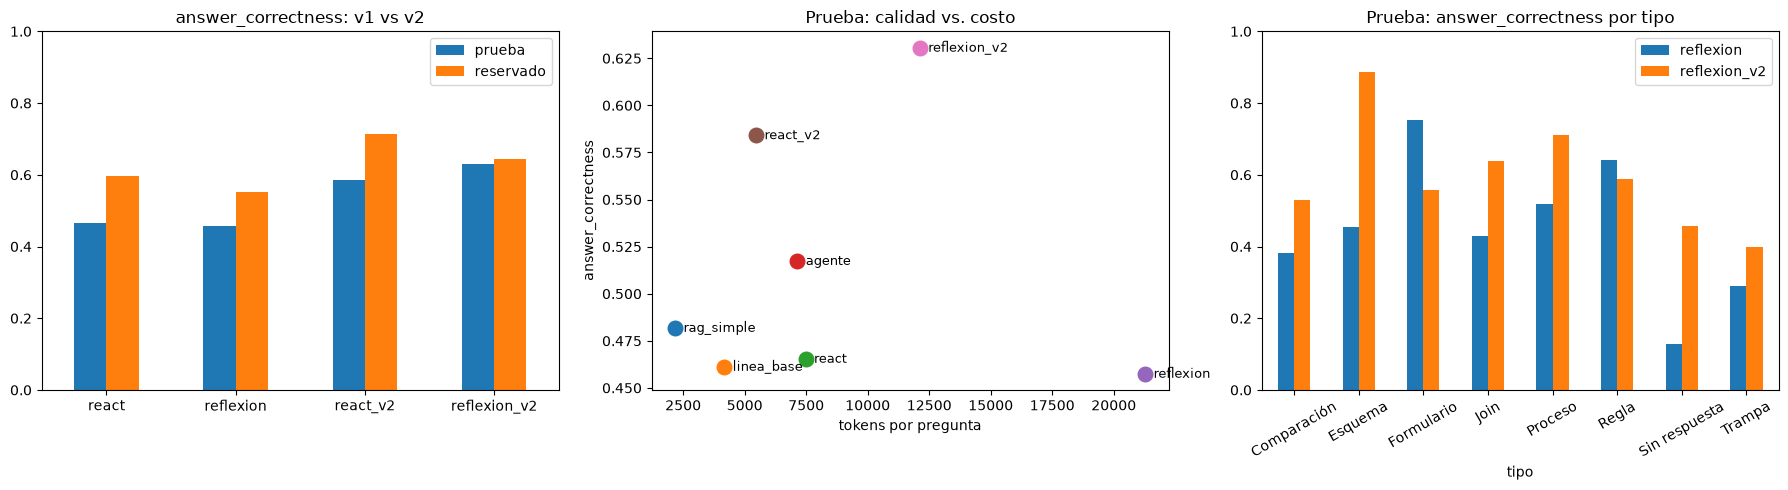

In [47]:
fig, ejes = plt.subplots(1, 3, figsize=(18, 5))
orden = ["react", "reflexion", "react_v2", "reflexion_v2"]

pd.DataFrame({"prueba": res_prueba.loc[orden, "answer_correctness"],
              "reservado": res_reservado.loc[orden, "answer_correctness"]}).plot.bar(ax=ejes[0], rot=0)
ejes[0].set_title("answer_correctness: v1 vs v2")
ejes[0].set_ylim(0, 1)

for n in res_prueba.index:
    ejes[1].scatter(res_prueba.loc[n, "tokens/preg"], res_prueba.loc[n, "answer_correctness"], s=110)
    ejes[1].annotate(n, (res_prueba.loc[n, "tokens/preg"], res_prueba.loc[n, "answer_correctness"]),
                     textcoords="offset points", xytext=(6, -3), fontsize=9)
ejes[1].set_xlabel("tokens por pregunta")
ejes[1].set_ylabel("answer_correctness")
ejes[1].set_title("Prueba: calidad vs. costo")

pd.DataFrame({n: TODO_V2[n].groupby("tipo")["answer_correctness"].mean() for n in ["reflexion", "reflexion_v2"]}
             ).plot.bar(ax=ejes[2], rot=30)
ejes[2].set_title("Prueba: answer_correctness por tipo")
ejes[2].set_ylim(0, 1)
plt.tight_layout()
plt.savefig(OUT_DIR / "comparacion_v2.png", dpi=150)
plt.show()

### 5B.10 ¿Se corrigieron las fallas?

Cada fila de la tabla corresponde a una falla de la sección 5B.1, medida en v1 y en v2.

In [48]:
def chequeo(detalle, nombre_refl):
    d = detalle[nombre_refl].copy()
    d["ref"] = d["id"].map(ESPERADOS["referencia"])
    paso = d["veredictos"].str.split(" → ").str[-1].eq("PASS")
    ok = d["answer_correctness"] >= 0.6
    r1 = detalle["react" if nombre_refl == "reflexion" else "react_v2"].set_index("id")["answer_correctness"]
    multi = d["intentos"] > 1
    delta = d.set_index("id")["answer_correctness"] - r1
    sin_resp = d["ref"].str.startswith("No consta")
    return {
        "falsos PASS del Evaluador": int((paso & ~ok).sum()),
        "falsos FAIL del Evaluador": int((~paso & ok).sum()),
        "preguntas que reflexionaron": int(multi.sum()),
        "reflexionar mejoró (>0.05)": int((delta[multi.values] > 0.05).sum()),
        "reflexionar empeoró (<-0.05)": int((delta[multi.values] < -0.05).sum()),
        "answer_correctness 'Sin respuesta'": round(d.loc[sin_resp, "answer_correctness"].mean(), 3) if sin_resp.any() else np.nan,
        "answer_correctness 'Comparación'": round(d.loc[d["tipo"] == "Comparación", "answer_correctness"].mean(), 3),
        "largo respuesta / referencia": round(d["respuesta"].str.len().mean() / d["ref"].str.len().mean(), 2),
    }


display(pd.DataFrame({
    "prueba · v1": chequeo(TODO_V2, "reflexion"), "prueba · v2": chequeo(TODO_V2, "reflexion_v2"),
    "reservado · v1": chequeo(TODO_H, "reflexion"), "reservado · v2": chequeo(TODO_H, "reflexion_v2"),
}))

# Ablación barata: cuánto aporta cada parte de la v2, comparando intento 1 y respuesta final
ac = lambda tabla, n: tabla.loc[n, "answer_correctness"]
for etiqueta, tabla in [("prueba", res_prueba), ("reservado", res_reservado)]:
    print(f"[{etiqueta}] react→react_v2 (prompt + herramienta + manual + pre-recuperación): "
          f"{ac(tabla, 'react'):.3f} → {ac(tabla, 'react_v2'):.3f} | "
          f"react_v2→reflexion_v2 (Evaluador y reflexión v2): {ac(tabla, 'react_v2'):.3f} → {ac(tabla, 'reflexion_v2'):.3f}")

,prueba · v1,prueba · v2,reservado · v1,reservado · v2
falsos PASS del Evaluador,16.000,11.000,4.000,4.000
falsos FAIL del Evaluador,2.000,1.000,1.000,0.000
preguntas que reflexionaron,13.000,6.000,3.000,1.000
reflexionar mejoró (>0.05),6.000,4.000,1.000,1.000
reflexionar empeoró (<-0.05),6.000,1.000,1.000,0.000
answer_correctness 'Sin respuesta',0.220,0.348,0.541,0.458
answer_correctness 'Comparación',0.381,0.531,0.515,0.895
largo respuesta / referencia,2.140,1.500,3.110,2.120


[prueba] react→react_v2 (prompt + herramienta + manual + pre-recuperación): 0.466 → 0.584 | react_v2→reflexion_v2 (Evaluador y reflexión v2): 0.584 → 0.631
[reservado] react→react_v2 (prompt + herramienta + manual + pre-recuperación): 0.597 → 0.713 | react_v2→reflexion_v2 (Evaluador y reflexión v2): 0.713 → 0.645


## 5C. Versión 3: agentes especialistas y registro de hechos verificados

La v2 mejoró, pero dejó tres límites medidos en la sección 5B:

1. **El Evaluador sigue juzgando texto libre con un LLM**: aún aprueba respuestas incorrectas (falsos PASS).
2. **Un solo agente con todas las herramientas** decide qué buscar para cualquier tipo de pregunta.
3. **La verificación se hace sobre la respuesta final**, por expresiones regulares, y confunde tablas homónimas de Sugar (`t9803.menu`).

La v3 cambia la unidad de trabajo: el agente ya no produce una respuesta, sino **hechos estructurados** que un **motor determinista** valida contra el grafo. La respuesta se redacta solo con los hechos que sobrevivieron, y se verifica contra ese mismo registro.

| Componente | Qué hace | ¿LLM? |
|---|---|---|
| `recordar` | Busca casos parecidos ya verificados en la **memoria de casos** | No (embeddings) |
| `enrutar` | Decide qué especialistas actúan y con qué subpregunta, o si la pregunta pide filas | Sí |
| `especialista` × k | Agentes ReAct **en paralelo** (`Send`), cada uno con 2 o 3 herramientas. Terminan con una lista de `Hecho` (salida estructurada) | Sí |
| `motor` | Valida cada hecho contra el grafo: tabla, columna, join, presencia por tenant, y anclaje del texto en la fuente que el especialista **sí consultó**. Escribe el **registro** y la lista de descartados | **No** |
| `redactar` | Escribe la respuesta usando solo el registro | Sí |
| `verificar` | 1) Todo identificador de la respuesta debe estar en el registro (sin LLM). 2) Un LLM revisa si cubre la pregunta y, si falta algo, qué especialista debe volver | Mixto |
| `reflexionar` | **Reflexion**: si el verificador reprueba, un Reflector escribe diagnóstico + plan (lección) y una regla general. Usa el registro **y los hechos descartados con su motivo** | Sí |
| Nuevo intento | Hasta `MAX_TRIALS_V3` intentos: vuelve al especialista que falta (con la trayectoria vacía y las lecciones) o reescribe con las lecciones | — |

**Reflexion dentro de la v3.** El ciclo es el de Shinn et al. (2023), con el mismo esquema Actor / Evaluador / Auto-reflexión de la sección 4B:

| Rol | En la v3 |
|---|---|
| Actor $M_a$ | especialistas + redactor |
| Evaluador $M_e$ | `verificar`: primero el registro (sin LLM), después el LLM |
| Auto-reflexión $M_{sr}$ | `reflexionar`: lección para esta pregunta (`mem`, crece entre intentos) y regla general |
| Memoria episódica | `mem`: lecciones de los intentos reprobados de **esta** pregunta |
| Memoria de reglas | manual v3: las reglas generales de la v2 más las que deja la reflexión durante el entrenamiento, consolidadas |

De cada ejecución salen dos sistemas sin pagar dos veces: `v3_intento1` (la primera respuesta, antes de reflexionar) y `v3` (la respuesta final). Su diferencia mide cuánto aporta la reflexión dentro de la nueva arquitectura.

**Memoria de casos.** Se construye una sola vez con las 40 preguntas de **entrenamiento**: se guarda una respuesta solo si pasó el verificador **y** el oráculo (que ve la referencia, permitido en entrenamiento). Durante la evaluación la memoria es **de solo lectura**, así que una pregunta de prueba nunca ve la respuesta de otra pregunta de prueba.

In [49]:
import operator
import threading
from typing import Literal
from pydantic import BaseModel, Field
from langgraph.graph import START
from langgraph.types import Send

MAX_STEPS_ESP = 4        # pasos ReAct por especialista
MAX_TRIALS_V3 = 3        # intentos de Reflexion (1 = sin reflexión)
UMBRAL_ANCLAJE = 0.6     # fracción de palabras del hecho que deben aparecer en su fuente
UMBRAL_MEMORIA = 0.75    # similitud mínima para usar un caso de la memoria
USAR_MEMORIA = True
PARALELO = True          # False: los especialistas corren uno a la vez
REGLAS_V3 = []           # manual de la v3; se llena al construir la memoria (5C.5)
PRIMER_V3 = {}           # costo, tiempo y evidencia del intento 1, para el sistema v3_intento1
_T0V3 = [0.0]

# Costo por nodo y evidencia por especialista. Los especialistas corren en hilos,
# así que el contador usa un candado y la evidencia vive en el hilo de cada especialista.
_CANDADO = threading.Lock()
_HILO = threading.local()
COSTO_NODO = {}


def llamar_llm(mensajes, modelo=None, etapa=None):
    # Igual que en la sección 2, más: costo por etapa, seguro entre hilos y soporte de include_raw
    respuesta = (modelo or llm).invoke(mensajes)
    crudo = respuesta["raw"] if isinstance(respuesta, dict) and "raw" in respuesta else respuesta
    uso = getattr(crudo, "usage_metadata", None) or {}
    with _CANDADO:
        COSTO["llamadas"] += 1
        COSTO["tokens_in"] += uso.get("input_tokens", 0)
        COSTO["tokens_out"] += uso.get("output_tokens", 0)
        if etapa:
            c = COSTO_NODO.setdefault(etapa, {"llamadas": 0, "tokens": 0})
            c["llamadas"] += 1
            c["tokens"] += uso.get("input_tokens", 0) + uso.get("output_tokens", 0)
    return respuesta


def _anotar(*doc_ids):
    # Igual que en la sección 4.2, más la evidencia propia del especialista que llamó la herramienta
    propia = getattr(_HILO, "evidencia", None)
    with _CANDADO:
        for d in doc_ids:
            if not d:
                continue
            if d not in EVIDENCIA:
                EVIDENCIA.append(d)
            if propia is not None and d not in propia:
                propia.append(d)

### 5C.1 Los especialistas y el formato de los hechos

Cada especialista ve solo las herramientas de su dominio. Así el modelo elige entre 2 o 3 opciones en vez de 6, y la traza muestra qué parte del sistema respondió cada parte de la pregunta.

In [50]:
RAMAS = {
    "procesos": {"tools": [buscar, pasos, vecinos],
                 "rol": "procesos de menú y formularios: quién entra, por qué menú, pasos en orden y tablas que escribe"},
    "esquema": {"tools": [ver_tabla, camino_join, buscar],
                "rol": "tablas, columnas, claves primarias y joins válidos entre tablas"},
    "tenants": {"tools": [presencia_tablas, ver_tabla],
                "rol": "presencia de tablas en los cuatro tenants, tablas exclusivas y filas estimadas"},
    "reglas": {"tools": [buscar, vecinos, ver_tabla],
               "rol": "reglas de negocio: tipos de documento, tipos de persona, estados (anulado, pendiente), códigos"},
}


class Hecho(BaseModel):
    tipo: Literal["tabla", "columna", "join", "paso", "presencia", "regla", "no_consta"] = Field(
        description="tabla/columna: existe y qué guarda; join: relación entre dos columnas; paso: un paso de un "
                    "proceso o formulario; presencia: en qué tenants está una tabla; regla: regla de negocio; "
                    "no_consta: la evidencia no tiene el dato")
    texto: str = Field(description="Afirmación breve en español, con las palabras de la evidencia")
    tabla: str = Field(default="", description="Tabla principal, sin prefijo table:")
    columna: str = Field(default="", description="Columna de la tabla principal")
    tabla_b: str = Field(default="", description="Solo join: la otra tabla")
    columna_b: str = Field(default="", description="Solo join: la otra columna")
    tenants: list[str] = Field(default_factory=list, description="Solo presencia: tenants (lifecolor, indupan, garage84, labclinico1)")
    presente: bool = Field(default=True, description="Solo presencia: True si está en esos tenants, False si NO está")
    base: Literal["tenant", "sugar"] = Field(default="tenant", description="sugar si el hecho es de la base Sugar (login, menú), no del tenant")
    fuente_id: str = Field(default="", description="id del documento que lo respalda: table:..., process:..., form_action:..., concept:..., link:...")


class Hallazgos(BaseModel):
    hechos: list[Hecho] = Field(default_factory=list)


class Plan(BaseModel):
    datos_de_filas: bool = Field(description="True si la pregunta pide filas o datos de negocio (conteos, un cliente concreto, saldos, el más vendido)")
    ramas: list[Literal["procesos", "esquema", "tenants", "reglas"]] = Field(
        default_factory=list, description="Especialistas necesarios, normalmente uno. Vacío si datos_de_filas")
    subpreguntas: list[str] = Field(default_factory=list, description="Una subpregunta autocontenida por rama, en el mismo orden")


class VeredictoV3(BaseModel):
    paso: bool = Field(description="True si la respuesta contesta la pregunta usando solo el registro")
    motivo: str = Field(description="Una oración: qué falta o qué sobra")
    falta_rama: Literal["", "procesos", "esquema", "tenants", "reglas"] = Field(
        default="", description="Si faltan hechos para contestar, el especialista que debe buscarlos")


ENRUTADOR_PROMPT = '''Eres el enrutador de un sistema de especialistas sobre el esquema tenant del ERP Kerberos.
Especialistas disponibles:
''' + "\n".join(f"- {r}: {v['rol']}" for r, v in RAMAS.items()) + '''

Elige el MÍNIMO de especialistas necesario (casi siempre uno; dos solo si la pregunta tiene partes de dominios distintos).
Escribe una subpregunta autocontenida para cada uno.
Si la pregunta pide filas o datos de negocio (cuántos documentos, qué cliente, saldos, el producto más vendido),
marca datos_de_filas y no elijas especialistas: el grafo describe el esquema, no las filas.'''

EXTRACTOR_PROMPT = '''Convierte lo que el especialista OBSERVÓ en las herramientas en una lista de hechos.
- Solo hechos que aparezcan en las observaciones; nada de conocimiento propio.
- Un hecho por afirmación; usa las palabras de la observación en el campo texto.
- Indica fuente_id con el id del documento que respalda cada hecho (table:..., process:..., form_action:..., concept:..., link:...).
- Si un dato que la subpregunta pide no aparece, agrega un hecho de tipo no_consta que lo diga.
- Si un hecho es de la base Sugar (login de Luna, menú del usuario), marca base = sugar.'''

REDACTOR_PROMPT = REGLAS_V2 + '''

Redacta la respuesta usando SOLO los hechos del REGISTRO. Si el registro no alcanza para una parte de la pregunta,
di que esa parte no consta. No agregues tablas, columnas ni joins que no estén en el registro.'''

VERIFICADOR_PROMPT = '''Revisas la respuesta de un sistema contra su REGISTRO de hechos ya verificados.

PREGUNTA: {pregunta}

REGISTRO:
{registro}

RESPUESTA:
{respuesta}

paso = True si la respuesta contesta lo que se pregunta y no afirma nada fuera del registro.
paso = False si falta una parte de la pregunta, si afirma algo fuera del registro, o si dice "No consta" cuando el
registro sí tiene el dato. Si faltan hechos que el registro no tiene, indica en falta_rama qué especialista debe
buscarlos ({ramas}). Si solo hay que reescribir, deja falta_rama vacío. No repruebes por brevedad.'''


REFLECTOR_V3 = '''Ayudas a un sistema de especialistas a aprender de un intento reprobado. Especialistas: {ramas}.

PREGUNTA: {pregunta}
PLAN DEL ENRUTADOR: {plan}

REGISTRO de hechos verificados:
{registro}

HECHOS DESCARTADOS por el motor (con el motivo):
{descartados}

RESPUESTA reprobada:
{respuesta}

MOTIVO DEL VERIFICADOR: {motivo}

Escribe exactamente tres líneas:
DIAGNÓSTICO: qué paso causó el fallo (especialista equivocado, búsqueda mal planteada, hecho descartado por inventado o
sin fuente consultada, respuesta que ignora el registro o agrega datos...).
PLAN: qué hacer distinto en el próximo intento, con 1 o 2 llamadas concretas a herramientas si hace falta buscar.
REGLA GENERAL: una regla que sirva para OTRAS preguntas, sin datos de esta.'''


def prompt_especialista(rama, memoria, leccion):
    texto = (REGLAS_V2 + f"\n\nEres el especialista en {RAMAS[rama]['rol']}. Usa tus herramientas para encontrar la evidencia; "
             "no respondas de memoria. Cuando tengas lo necesario, escribe LISTO y un resumen de una línea.")
    manual = REGLAS_V3 or REGLAS_APRENDIDAS
    if manual:
        texto += "\n\nManual de reglas aprendidas:\n" + "\n".join(f"- {r}" for r in manual)
    if memoria:
        texto += "\n\nCasos parecidos ya verificados (pueden no aplicar a esta pregunta):\n" + memoria
    if leccion:
        texto += "\n\nYa intentaste esta pregunta y fue REPROBADA. Lecciones (no repitas esos errores):\n" + leccion
    return texto


llm_enrutador = llm.with_structured_output(Plan, method="function_calling", include_raw=True)
llm_extractor = llm.with_structured_output(Hallazgos, method="function_calling", include_raw=True)
llm_verificador = llm_eval.with_structured_output(VeredictoV3, method="function_calling", include_raw=True)

print(ENRUTADOR_PROMPT)

Eres el enrutador de un sistema de especialistas sobre el esquema tenant del ERP Kerberos.
Especialistas disponibles:
- procesos: procesos de menú y formularios: quién entra, por qué menú, pasos en orden y tablas que escribe
- esquema: tablas, columnas, claves primarias y joins válidos entre tablas
- tenants: presencia de tablas en los cuatro tenants, tablas exclusivas y filas estimadas
- reglas: reglas de negocio: tipos de documento, tipos de persona, estados (anulado, pendiente), códigos

Elige el MÍNIMO de especialistas necesario (casi siempre uno; dos solo si la pregunta tiene partes de dominios distintos).
Escribe una subpregunta autocontenida para cada uno.
Si la pregunta pide filas o datos de negocio (cuántos documentos, qué cliente, saldos, el producto más vendido),
marca datos_de_filas y no elijas especialistas: el grafo describe el esquema, no las filas.


### 5C.2 El motor de hechos (determinista)

El motor no llama al LLM. Para cada hecho:

| Tipo | Se acepta si |
|---|---|
| `tabla` | la tabla existe en el grafo |
| `columna` | la columna existe en esa tabla |
| `join` | el par de columnas está en `LINKS_VALIDOS` |
| `presencia` | lo que dice de cada tenant coincide con las aristas `PRESENT_IN` |
| `paso`, `regla` | la `fuente_id` es un documento que **ese especialista consultó**, y el texto está **anclado** en ella (≥ `UMBRAL_ANCLAJE` de sus palabras aparecen en la fuente) |
| `no_consta` | siempre (abstenerse nunca es una alucinación) |
| base `sugar` | se acepta como **externo**: no se valida contra el esquema tenant, que no la describe |

Además, todo identificador que aparezca en el `texto` de un hecho del tenant pasa por `verificar_esquema`.

In [51]:
def anclaje(texto, fuente):
    palabras = re.findall(r"[a-záéíóúñü0-9_]{4,}", texto.lower())
    if not palabras:
        return 1.0
    fuente = fuente.lower()
    return sum(p in fuente for p in palabras) / len(palabras)


def validar_hecho(h):
    # Devuelve (aceptado, motivo)
    if h["tipo"] == "no_consta":
        return True, "abstención"
    if h.get("base") == "sugar":
        return True, "externo (Sugar): no se valida contra el esquema tenant"
    tabla, columna = h.get("tabla", "").removeprefix("table:"), h.get("columna", "")
    tipo = h["tipo"]
    if tipo in ("tabla", "columna", "presencia") and tabla not in TABLAS:
        return False, f"la tabla {tabla or '(vacía)'} no existe"
    if tipo == "columna" and columna not in COLUMNAS.get(tabla, set()):
        return False, f"la columna {tabla}.{columna} no existe"
    if tipo == "join":
        par = frozenset((f"{tabla}.{columna}", f"{h.get('tabla_b', '')}.{h.get('columna_b', '')}"))
        if par not in LINKS_VALIDOS:
            return False, f"el join {' = '.join(sorted(par))} no es una relación válida"
    if tipo == "presencia":
        bases = set(NODOS["table:" + tabla]["properties"]["bases"])
        for t in h.get("tenants", []):
            base = _tenant(t)
            if not base:
                return False, f"tenant desconocido: {t}"
            if (base in bases) != h.get("presente", True):
                return False, f"{tabla} {'no ' if h.get('presente', True) else ''}está en {CORTO[base]}"
    if tipo in ("paso", "regla"):
        fuente = h.get("fuente_id", "")
        if fuente not in DOC_POR_ID:
            return False, f"fuente inexistente: {fuente or '(vacía)'}"
        if fuente not in h.get("vistos", []):
            return False, f"fuente no consultada por el especialista: {fuente}"
        if anclaje(h["texto"], DOC_POR_ID[fuente]["text"]) < UMBRAL_ANCLAJE:
            return False, f"el texto no está anclado en {fuente}"
    _, errores, _, errores_join = verificar_esquema(h["texto"])
    if errores + errores_join:
        return False, "; ".join(errores + errores_join)
    return True, "verificado"


def linea_hecho(h):
    partes = [f"[{h['tipo']}]"]
    if h["tipo"] == "join":
        partes.append(f"{h['tabla']}.{h['columna']} = {h['tabla_b']}.{h['columna_b']}")
    elif h["tipo"] == "columna":
        partes.append(f"{h['tabla']}.{h['columna']}")
    elif h.get("tabla"):
        partes.append(h["tabla"])
    if h.get("base") == "sugar":
        partes.append("(Sugar)")
    return " ".join(partes) + f": {h['texto']}"


# Pruebas del motor con hechos escritos a mano
for prueba in [
    {"tipo": "join", "texto": "obligación con cliente", "tabla": "t03b11", "columna": "nroDireccion",
     "tabla_b": "t0101", "columna_b": "mnNroDireccion"},
    {"tipo": "columna", "texto": "estado del cliente", "tabla": "t0101", "columna": "szEstadoCliente"},
    {"tipo": "presencia", "texto": "t57011a no está en Indupan", "tabla": "t57011a", "tenants": ["indupan"], "presente": False},
    {"tipo": "regla", "texto": "un documento está anulado si szDutyStatus = V", "fuente_id": "concept:anulado", "vistos": []},
    {"tipo": "columna", "texto": "el menú del usuario está en t9803.menu", "tabla": "t9803", "columna": "menu", "base": "sugar"},
]:
    print(validar_hecho(prueba), "←", linea_hecho({**{"tabla": "", "columna": ""}, **prueba}))

(True, 'verificado') ← [join] t03b11.nroDireccion = t0101.mnNroDireccion: obligación con cliente
(False, 'la columna t0101.szEstadoCliente no existe') ← [columna] t0101.szEstadoCliente: estado del cliente
(True, 'verificado') ← [presencia] t57011a: t57011a no está en Indupan
(False, 'fuente no consultada por el especialista: concept:anulado') ← [regla]: un documento está anulado si szDutyStatus = V
(True, 'externo (Sugar): no se valida contra el esquema tenant') ← [columna] t9803.menu (Sugar): el menú del usuario está en t9803.menu


### 5C.3 Memoria de casos verificados

Es una colección de Chroma aparte, que se reconstruye en cada sesión desde `resultados/memoria_v3.json`. `recordar` devuelve hasta 2 casos con similitud ≥ `UMBRAL_MEMORIA`, como **pistas** para el enrutador y los especialistas, nunca como respuesta.

In [52]:
memoria_store = Chroma(collection_name="memoria_v3", embedding_function=embeddings,
                       collection_metadata={"hnsw:space": "cosine"})


def recordar(pregunta):
    if not USAR_MEMORIA or memoria_store._collection.count() == 0:
        return "", []
    pares = memoria_store.similarity_search_with_relevance_scores(pregunta, k=2)
    casos = [(d, s) for d, s in pares if s >= UMBRAL_MEMORIA]
    texto = "\n".join(f"- ({s:.2f}) P: {d.metadata['pregunta']} → R: {d.metadata['respuesta']}" for d, s in casos)
    return texto, [d.metadata["id"] for d, _ in casos]


def archivar(caso_id, pregunta, respuesta, lineas_registro):
    memoria_store.add_documents([Document(page_content=pregunta, metadata={
        "id": caso_id, "pregunta": pregunta, "respuesta": respuesta,
        "registro": json.dumps(lineas_registro, ensure_ascii=False)})], ids=[caso_id])

### 5C.4 El grafo de la v3

```
START → recordar → enrutar ─┬─(Send)→ especialista[procesos] ─┐
                            ├─(Send)→ especialista[esquema]  ─┼→ motor → redactar → verificar ──(PASS o último intento)──→ END
                            └─(datos de filas)────────────────┘             ↑            │ FAIL
                                         ↑                                   │            ↓
                                         └── (falta un especialista) ── reflexionar ──(reescribir)
```

Es Reflexion con dos ciclos: el interno (ReAct dentro de cada especialista) y el externo (`verificar → reflexionar → nuevo intento`), hasta `MAX_TRIALS_V3`. Cada nuevo intento empieza con la trayectoria vacía y recibe todas las lecciones de `mem`.

`hechos_propuestos`, `evidencia` y `trazas` usan el *reducer* `operator.add`, para que los especialistas en paralelo agreguen sin pisarse. El motor revalida **todos** los hechos en cada vuelta, así que un reintento solo suma evidencia.

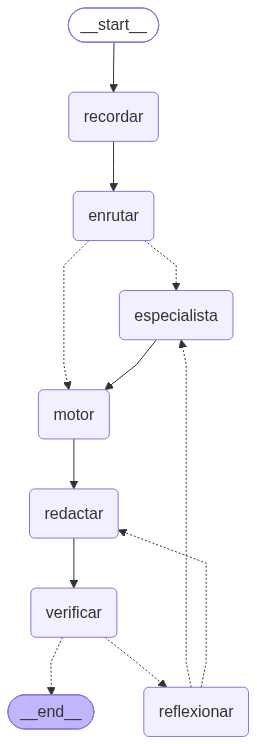

In [53]:
class EstadoV3(TypedDict):
    pregunta: str
    memoria: str
    memoria_ids: list[str]
    datos_de_filas: bool
    ramas: list[str]
    subpreguntas: list[str]
    hechos_propuestos: Annotated[list, operator.add]
    evidencia: Annotated[list, operator.add]
    trazas: Annotated[list, operator.add]
    registro: list
    descartados: list
    borrador: str
    borradores: list
    intentos: int
    veredictos: list
    mem: list[str]            # Reflexion: lecciones de esta pregunta (crece entre intentos)
    reglas_nuevas: list[str]  # Reflexion: reglas generales (se usan en el entrenamiento)
    motivo: str
    falta_rama: str
    siguiente: str
    ramas_reintentadas: list


def nodo_recordar(state):
    memoria, ids = recordar(state["pregunta"])
    say(f"[Memoria] {len(ids)} caso(s) parecido(s): {ids}")
    return {"memoria": memoria, "memoria_ids": ids}


def nodo_enrutar(state):
    texto = state["pregunta"] + (f"\n\nCasos parecidos ya verificados:\n{state['memoria']}" if state["memoria"] else "")
    salida = llamar_llm([SystemMessage(content=ENRUTADOR_PROMPT), HumanMessage(content=texto)],
                        modelo=llm_enrutador, etapa="enrutar")
    plan = salida["parsed"] or Plan(datos_de_filas=False, ramas=["esquema"], subpreguntas=[state["pregunta"]])
    ramas = [] if plan.datos_de_filas else list(dict.fromkeys(plan.ramas)) or ["esquema"]
    subs = [plan.subpreguntas[i] if i < len(plan.subpreguntas) and plan.subpreguntas[i] else state["pregunta"]
            for i in range(len(ramas))]
    say(f"[Enrutar] datos_de_filas={plan.datos_de_filas} | ramas={ramas} | {subs}")
    return {"datos_de_filas": plan.datos_de_filas, "ramas": ramas, "subpreguntas": subs}


def _envios(state, ramas, subpreguntas, leccion=""):
    return [Send("especialista", {"pregunta": state["pregunta"], "rama": r, "subpregunta": s,
                                  "memoria": state.get("memoria", ""), "leccion": leccion})
            for r, s in zip(ramas, subpreguntas)]


def despachar(state):
    if state["datos_de_filas"] or not state["ramas"]:
        return "motor"
    return _envios(state, state["ramas"], state["subpreguntas"])


def invocar_herramienta(herramientas, tc):
    # Un error de la herramienta vuelve al especialista como observación, en vez de detener el grafo
    h = herramientas.get(tc["name"])
    if not h:
        return f"La herramienta {tc['name']} no está disponible para este especialista. Disponibles: {', '.join(herramientas)}."
    try:
        return h.invoke(tc["args"])
    except Exception as e:
        return (f"Error al llamar {tc['name']} con {tc['args']}: {type(e).__name__}. "
                f"Argumentos que espera: {list(h.args)}. Corrige la llamada.")


def nodo_especialista(payload):
    # Agente ReAct de un dominio; termina con hechos estructurados
    rama = payload["rama"]
    _HILO.evidencia = []
    herramientas = {t.name: t for t in RAMAS[rama]["tools"]}
    llm_rama = llm.bind_tools(RAMAS[rama]["tools"])
    mensajes = [SystemMessage(content=prompt_especialista(rama, payload["memoria"], payload["leccion"])),
                HumanMessage(content=f"{payload['subpregunta']}\n\n(Pregunta original: {payload['pregunta']})")]
    for _ in range(MAX_STEPS_ESP):
        r = llamar_llm(mensajes, modelo=llm_rama, etapa=f"especialista:{rama}")
        mensajes.append(r)
        if not r.tool_calls:
            break
        for tc in r.tool_calls:
            mensajes.append(ToolMessage(content=invocar_herramienta(herramientas, tc), tool_call_id=tc["id"]))
    vistos = list(_HILO.evidencia)
    _HILO.evidencia = None
    hechos = []
    if any(isinstance(m, ToolMessage) for m in mensajes):
        salida = llamar_llm([SystemMessage(content=EXTRACTOR_PROMPT),
                             HumanMessage(content=f"SUBPREGUNTA: {payload['subpregunta']}\n\nTRAYECTORIA:\n"
                                                  f"{trayectoria_de(mensajes, obs_chars=2500)}")],
                            modelo=llm_extractor, etapa=f"especialista:{rama}")
        if salida["parsed"]:
            hechos = [{**h.model_dump(), "rama": rama, "vistos": vistos} for h in salida["parsed"].hechos]
    traza = {"rama": rama, "subpregunta": payload["subpregunta"],
             "herramientas": [f"{tc['name']}({tc['args']})" for m in mensajes if isinstance(m, AIMessage) for tc in m.tool_calls],
             "n_hechos": len(hechos)}
    say(f"[Especialista {rama}] {len(traza['herramientas'])} llamadas a herramientas → {len(hechos)} hechos")
    return {"hechos_propuestos": hechos, "evidencia": vistos, "trazas": [traza]}


def nodo_motor(state):
    registro, descartados, vistos_txt = [], [], set()
    if state["datos_de_filas"]:
        registro.append({"tipo": "no_consta", "texto": "La pregunta pide filas o datos de negocio; el grafo describe el esquema, no las filas.",
                         "tabla": "", "columna": "", "rama": "enrutar", "fuente_id": "layer:tenant"})
    for h in state.get("hechos_propuestos", []):
        clave = (h["tipo"], h["texto"].strip().lower())
        if clave in vistos_txt:
            continue
        vistos_txt.add(clave)
        ok, motivo = validar_hecho(h)
        (registro if ok else descartados).append({**h, "motivo": motivo})
    say(f"[Motor] registro={len(registro)} | descartados={len(descartados)}")
    for d in descartados:
        say(f"   ✗ {linea_hecho(d)} → {d['motivo']}")
    return {"registro": registro, "descartados": descartados}


NO_CONSTA_FILAS = "No consta en el grafo: el grafo describe el esquema, no las filas."


def nodo_redactar(state):
    registro = state["registro"]
    utiles = [h for h in registro if h["tipo"] != "no_consta"]
    if state["datos_de_filas"]:
        borrador = NO_CONSTA_FILAS
    elif not utiles:
        borrador = "No consta en el grafo: " + (registro[0]["texto"] if registro else "las herramientas no devolvieron evidencia verificable.")
    else:
        texto = (f"PREGUNTA: {state['pregunta']}\n\nREGISTRO:\n" + "\n".join(f"- {linea_hecho(h)}" for h in registro)
                 + ("\n\nLecciones de intentos anteriores reprobados:\n" + "\n".join(f"- {l}" for l in state["mem"])
                    if state.get("mem") else ""))
        borrador = texto_de(llamar_llm([SystemMessage(content=REDACTOR_PROMPT), HumanMessage(content=texto)],
                                       etapa="redactar")).strip()
        borrador = borrador.split("Respuesta final:", 1)[-1].strip()
    say(f"[Redactar] {borrador[:300]}")
    return {"borrador": borrador, "borradores": state.get("borradores", []) + [borrador]}


def fuera_del_registro(respuesta, registro):
    # Identificadores de la respuesta que no aparecen en ningún hecho del registro
    tabs, cal, cols, joins = identificadores(respuesta)
    texto_reg = " ".join(linea_hecho(h) for h in registro)
    ptabs, pcal, pcols, pjoins = identificadores(texto_reg)
    columnas_ok = pcols | {c for _, c in pcal}
    return (sorted(tabs - ptabs) + sorted(f"{t}.{c}" for t, c in cal - pcal)
            + sorted(cols - columnas_ok) + sorted(" = ".join(sorted(j)) for j in joins - pjoins))


def nodo_verificar(state):
    # Evaluador M_e: primero el registro (sin LLM), después el LLM
    if state.get("intentos", 0) == 0:
        PRIMER_V3.update(respuesta=state["borrador"], evidencia=list(EVIDENCIA), costo=dict(COSTO),
                         segundos=round(time.perf_counter() - _T0V3[0], 2))
    intentos = state.get("intentos", 0) + 1
    registro, borrador = state["registro"], state["borrador"]
    falta = ""
    if state["datos_de_filas"] or not [h for h in registro if h["tipo"] != "no_consta"]:
        paso, motivo = True, "abstención fundamentada en el registro"
    else:
        fuera = fuera_del_registro(borrador, registro)
        if fuera:
            paso, motivo = False, "La respuesta menciona identificadores que no están en el registro: " + ", ".join(fuera)
        else:
            salida = llamar_llm([HumanMessage(content=VERIFICADOR_PROMPT.format(
                pregunta=state["pregunta"], registro="\n".join(f"- {linea_hecho(h)}" for h in registro),
                respuesta=borrador, ramas=", ".join(RAMAS)))], modelo=llm_verificador, etapa="verificar")
            v = salida["parsed"] or VeredictoV3(paso=True, motivo="(sin veredicto legible)")
            paso, motivo, falta = v.paso, v.motivo, v.falta_rama
    veredictos = state.get("veredictos", []) + ["PASS" if paso else "FAIL"]
    siguiente = "fin" if paso or intentos >= MAX_TRIALS_V3 else "reflexionar"
    say(f"[Verificar · intento {intentos}] {'PASS' if paso else 'FAIL'}: {motivo} → {siguiente}")
    return {"intentos": intentos, "veredictos": veredictos, "motivo": motivo, "falta_rama": falta, "siguiente": siguiente}


def nodo_reflexionar(state):
    # Auto-reflexión M_sr: lección para esta pregunta + regla general, y a dónde vuelve el nuevo intento
    prompt = REFLECTOR_V3.format(
        ramas=", ".join(RAMAS), pregunta=state["pregunta"],
        plan=("datos de filas" if state["datos_de_filas"] else ", ".join(f"{r}: {s}" for r, s in zip(state["ramas"], state["subpreguntas"]))),
        registro="\n".join(f"- {linea_hecho(h)}" for h in state["registro"]) or "(vacío)",
        descartados="\n".join(f"- {linea_hecho(h)} → {h['motivo']}" for h in state["descartados"]) or "(ninguno)",
        respuesta=state["borrador"], motivo=state["motivo"])
    texto = texto_de(llamar_llm([HumanMessage(content=prompt)], modelo=llm_eval, etapa="reflexionar")).strip()
    regla = re.search(r"REGLA GENERAL:\s*(.+)", texto)
    leccion = re.sub(r"\n?REGLA GENERAL:.*", "", texto, flags=re.DOTALL).strip() or state["motivo"]
    falta = state.get("falta_rama", "")
    if falta and falta not in state.get("ramas_reintentadas", []):
        siguiente, reintentadas = "rama:" + falta, state.get("ramas_reintentadas", []) + [falta]
    else:
        siguiente, reintentadas = "redactar", state.get("ramas_reintentadas", [])
    say(f"[Reflexionar] {leccion}\n  [Regla general] {regla.group(1).strip() if regla else '(no escribió)'}\n  → {siguiente}")
    return {"mem": state.get("mem", []) + [leccion], "siguiente": siguiente, "ramas_reintentadas": reintentadas,
            "reglas_nuevas": state.get("reglas_nuevas", []) + ([regla.group(1).strip()] if regla else [])}


def despues_de_verificar(state):
    return END if state["siguiente"] == "fin" else "reflexionar"


def despues_de_reflexionar(state):
    # Nuevo intento: el especialista que falta (trayectoria vacía + lecciones) o el redactor con las lecciones
    if state["siguiente"].startswith("rama:"):
        rama = state["siguiente"].split(":", 1)[1]
        return _envios(state, [rama], [state["pregunta"]], leccion="\n".join(f"- {l}" for l in state["mem"]))
    return "redactar"


g3 = StateGraph(EstadoV3)
g3.add_node("recordar", nodo_recordar)
g3.add_node("enrutar", nodo_enrutar)
g3.add_node("especialista", nodo_especialista)
g3.add_node("motor", nodo_motor)
g3.add_node("redactar", nodo_redactar)
g3.add_node("verificar", nodo_verificar)
g3.add_node("reflexionar", nodo_reflexionar)
g3.add_edge(START, "recordar")
g3.add_edge("recordar", "enrutar")
g3.add_conditional_edges("enrutar", despachar, ["especialista", "motor"])
g3.add_edge("especialista", "motor")
g3.add_edge("motor", "redactar")
g3.add_edge("redactar", "verificar")
g3.add_conditional_edges("verificar", despues_de_verificar, ["reflexionar", END])
g3.add_conditional_edges("reflexionar", despues_de_reflexionar, ["especialista", "redactar"])
agente_v3 = g3.compile()

try:
    display(Image(agente_v3.get_graph().draw_mermaid_png()))
except Exception:
    print(agente_v3.get_graph().draw_mermaid())


def run_v3(pregunta):
    EVIDENCIA.clear()
    PRIMER_V3.clear()
    _T0V3[0] = time.perf_counter()
    estado = {"pregunta": pregunta, "memoria": "", "memoria_ids": [], "datos_de_filas": False, "ramas": [],
              "subpreguntas": [], "hechos_propuestos": [], "evidencia": [], "trazas": [], "registro": [],
              "descartados": [], "borrador": "", "borradores": [], "intentos": 0, "veredictos": [],
              "mem": [], "reglas_nuevas": [], "motivo": "", "falta_rama": "", "siguiente": "",
              "ramas_reintentadas": []}
    config = {"recursion_limit": 25 * MAX_TRIALS_V3, "max_concurrency": 4 if PARALELO else 1}
    final = agente_v3.invoke(estado, config)
    # Respuesta: el intento aprobado; si ninguno aprobó, el primero sin identificadores fuera del registro; si no, el último
    pares = list(zip(final["borradores"], final["veredictos"]))
    aprobados = [b for b, v in pares if v == "PASS"]
    limpios = [b for b, _ in pares if not fuera_del_registro(b, final["registro"])]
    final["final_answer"] = (aprobados[-1:] or limpios[:1] or final["borradores"][-1:] or ["No consta en el grafo."])[0]
    return final


def sistema_v3(pregunta):
    COSTO_NODO.clear()
    final = run_v3(pregunta)
    return {"respuesta": final["final_answer"], "evidencia_ids": list(EVIDENCIA),
            "ramas": final["ramas"], "datos_de_filas": final["datos_de_filas"],
            "intentos": final["intentos"], "veredictos": " → ".join(final["veredictos"]),
            "registro": [linea_hecho(h) for h in final["registro"]],
            "descartados": [f"{linea_hecho(h)} → {h['motivo']}" for h in final["descartados"]],
            "n_registro": len(final["registro"]), "n_descartados": len(final["descartados"]),
            "memoria_ids": final["memoria_ids"], "costo_nodo": json.loads(json.dumps(COSTO_NODO)),
            "lecciones": final["mem"], "reglas_nuevas": final["reglas_nuevas"],
            # Intento 1 como sistema aparte (v3_intento1), con su propio costo
            "react_respuesta": PRIMER_V3.get("respuesta") or "No consta en el grafo.",
            "react_evidencia": PRIMER_V3.get("evidencia", []),
            "react_llamadas": PRIMER_V3.get("costo", {}).get("llamadas", 0),
            "react_tokens_in": PRIMER_V3.get("costo", {}).get("tokens_in", 0),
            "react_tokens_out": PRIMER_V3.get("costo", {}).get("tokens_out", 0),
            "react_segundos": PRIMER_V3.get("segundos", 0.0)}


def mostrar_v3(r, referencia=None):
    print(f"Ramas: {r['ramas']} | datos de filas: {r['datos_de_filas']} | veredictos: {r['veredictos']} | memoria: {r['memoria_ids']}")
    print("Registro:")
    for l in r["registro"]:
        print("  ✓", l)
    if r["descartados"]:
        print("Descartados por el motor:")
        for l in r["descartados"]:
            print("  ✗", l)
    for k, l in enumerate(r.get("lecciones", []), 1):
        print(f"Lección {k}: {l}")
    if r.get("lecciones"):
        print("Respuesta del intento 1:", r["react_respuesta"])
    print("\nRespuesta:", r["respuesta"])
    if referencia:
        print("Referencia:", referencia)
    print("Costo por nodo:", r["costo_nodo"])

### 5C.5 Construir la memoria con el conjunto de entrenamiento

Se ejecuta la v3 sobre las 40 preguntas de entrenamiento, leyendo la memoria que se va formando. Deja dos memorias:

1. **Casos**: se archiva una respuesta solo si la aprobaron el verificador **y** el oráculo (`ORACULO_V2`, que compara con la referencia).
2. **Reglas**: cada reflexión deja una regla general. Al final se consolidan junto con el manual de la v2 en un **manual v3** de ≤ `MAX_REGLAS` reglas, que los especialistas reciben desde el intento 1.

El resultado queda en `resultados/memoria_v3.json` y se reutiliza mientras no cambien el modelo, el evaluador ni las preguntas.

In [54]:
def construir_memoria(preguntas):
    ruta = OUT_DIR / "memoria_v3.json"
    clave = {"modelo": LLM_MODEL, "eval_model": EVAL_MODEL, "preguntas": preguntas["id"].tolist()}
    if ruta.exists() and not RECALCULAR:
        guardado = json.loads(ruta.read_text(encoding="utf-8"))
        if all(guardado.get(k) == v for k, v in clave.items()):
            print(f"Memoria cargada desde {ruta}")
            return guardado
        print("La memoria guardada es de otro modelo o de otras preguntas: se vuelve a construir")
    memoria_store.reset_collection()
    for k in COSTO:
        COSTO[k] = 0
    t0, casos, registro_corrida, crudas = time.perf_counter(), [], [], []
    for q in preguntas.itertuples():
        r = sistema_v3(q.pregunta)
        oraculo = "FAIL"
        if r["veredictos"].endswith("PASS"):
            paso, _ = leer_veredicto(texto_de(llamar_llm([HumanMessage(content=ORACULO_V2.format(
                pregunta=q.pregunta, referencia=q.referencia, respuesta=r["respuesta"]))], modelo=llm_eval, etapa="oráculo")))
            oraculo = "PASS" if paso else "FAIL"
        if oraculo == "PASS":
            archivar(q.id, q.pregunta, r["respuesta"], r["registro"])
            casos.append({"id": q.id, "pregunta": q.pregunta, "respuesta": r["respuesta"], "registro": r["registro"]})
        crudas += r["reglas_nuevas"]
        registro_corrida.append({"id": q.id, "ramas": r["ramas"], "verificador": r["veredictos"], "oraculo": oraculo})
        print(f"[memoria] {q.id} ramas={r['ramas']} verificador={r['veredictos']} oráculo={oraculo}")
    # Reflexion como entrenamiento: las reglas generales de los fallos se consolidan con el manual de la v2
    reglas = list(REGLAS_APRENDIDAS)
    if crudas:
        texto = texto_de(llamar_llm([HumanMessage(content=CONSOLIDAR_V2.format(
            reglas="\n".join(f"- {x}" for x in list(REGLAS_APRENDIDAS) + crudas), n=MAX_REGLAS, base=REGLAS_V2))],
            modelo=llm_eval, etapa="consolidar"))
        reglas = [l.lstrip("-• ").strip() for l in texto.splitlines() if l.strip().startswith(("-", "•"))][:MAX_REGLAS] or reglas
    resultado = {**clave, "casos": casos, "corrida": registro_corrida, "reglas": reglas, "reglas_crudas": crudas,
                 "costo": dict(COSTO),
                 "segundos": round(time.perf_counter() - t0, 1)}
    ruta.write_text(json.dumps(resultado, ensure_ascii=False, indent=1), encoding="utf-8")
    return resultado


def cargar_memoria(memoria):
    memoria_store.reset_collection()
    for c in memoria["casos"]:
        archivar(c["id"], c["pregunta"], c["respuesta"], c["registro"])


VERBOSE = False
MEMORIA_V3 = construir_memoria(df_train)
cargar_memoria(MEMORIA_V3)
REGLAS_V3 = MEMORIA_V3.get("reglas", [])
VERBOSE = True
print(f"Casos en memoria: {len(MEMORIA_V3['casos'])} de {len(df_train)} | costo: {MEMORIA_V3['costo']} "
      f"en {MEMORIA_V3['segundos']} s (se paga una vez)")
display(pd.DataFrame(MEMORIA_V3["corrida"]).set_index("id").T)
print(f"\nReglas generales que dejó la reflexión: {len(MEMORIA_V3.get('reglas_crudas', []))} "
      f"→ manual v3 de {len(REGLAS_V3)} reglas:")
for k, r in enumerate(REGLAS_V3, 1):
    print(f"{k}. {r}")

Memoria cargada desde resultados/memoria_v3.json
Casos en memoria: 37 de 40 | costo: {'llamadas': 415, 'tokens_in': 968292, 'tokens_out': 78693} en 599.4 s (se paga una vez)


id,e01,e02,e03,e04,e05,e06,e07,e08,e09,e10,...,e31,e32,e33,e34,e35,e36,e37,e38,e39,e40
ramas,"[procesos, reglas]",[reglas],"[procesos, reglas, esquema]","[reglas, esquema]",[procesos],[esquema],[esquema],"[esquema, reglas]","[esquema, procesos]",[esquema],...,"[procesos, esquema]",[esquema],[esquema],[esquema],"[tenants, esquema]",[tenants],[esquema],"[esquema, tenants, reglas]","[esquema, tenants, reglas]",[]
verificador,PASS,PASS,PASS,PASS,PASS,PASS,PASS,PASS,PASS,PASS,...,PASS,FAIL → PASS,PASS,PASS,PASS,PASS,FAIL → FAIL → PASS,PASS,PASS,PASS
oraculo,FAIL,PASS,PASS,PASS,PASS,PASS,PASS,PASS,PASS,PASS,...,PASS,PASS,PASS,PASS,FAIL,PASS,PASS,PASS,PASS,PASS



Reglas generales que dejó la reflexión: 3 → manual v3 de 8 reglas:
1. Usa solo tablas y columnas que aparezcan en el contexto; escribe las columnas como `tabla.columna`.
2. Una relación entre tablas solo es válida si el contexto la da explícitamente (`INFERRED_LINK`, clave documentada o `camino_join`/`vecinos`); no inventes joins.
3. Si el contexto dice que Luna no usa una tabla, no inventes un flujo; y las tablas `t9801`, `t9802` y `t9803` del tenant no son el login de Luna: ese vive en la base Sugar.
4. Si la pregunta pide qué se genera, qué pasa al guardar, cómo separa o cómo funciona, sigue primero el flujo/acción explícita en `pasos` y confirma con `ver_tabla` o `camino_join` antes de responder.
5. No completes con inferencias: confirma siempre con evidencia directa qué objetos, campos o pasos existen; no asumas columnas, tablas, vínculos ni datos “probables”.
6. El grafo describe el esquema, no las filas: no inventes conteos, clientes, saldos, productos vendidos ni otros datos d

### 5C.6 Trazas

- **p13**: join de dos saltos.
- **p19**: comparación entre tenants.
- **p24**: datos de filas; no debería llamar a ningún especialista.

In [55]:
for pid in ["p13", "p19", "p24"]:
    for k in COSTO:
        COSTO[k] = 0
    print("\n" + "=" * 80 + f"\n{pid} | {ESPERADOS.loc[pid, 'pregunta']}\n" + "=" * 80)
    r = sistema_v3(ESPERADOS.loc[pid, "pregunta"])
    print()
    mostrar_v3(r, ESPERADOS.loc[pid, "referencia"])
    print("Costo total:", COSTO)


p13 | Desde un movimiento de kardex, ¿cómo llego al precio de venta del producto?
[Memoria] 0 caso(s) parecido(s): []
[Enrutar] datos_de_filas=False | ramas=['procesos', 'esquema', 'reglas'] | ['En el ERP Kerberos, desde un movimiento de kardex (qué menú/formulario consulta), ¿qué pasos en orden siguen para obtener el precio de venta del producto? Incluye tablas que se consultan/actualizan.', '¿Qué tablas del esquema relacionan un movimiento de kardex con el producto y con la(s) tabla(s) de precios de venta (precio_lista, precio_cliente, promociones, etc.)? Indica columnas, claves primarias y joins válidos.', '¿Qué reglas de negocio determinan qué ‘precio de venta’ se devuelve (por tipo de cliente, moneda, vigencia, lista de precios, descuentos, estado del documento), y qué códigos/estados afectan la selección?']
[Especialista esquema] 10 llamadas a herramientas → 14 hechos
[Especialista reglas] 7 llamadas a herramientas → 27 hechos
[Especialista procesos] 5 llamadas a herramientas → 

### 5C.7 Ejecución: prueba (25) y reservado (12)

La memoria es de solo lectura durante la evaluación. Los sistemas de la v2 se cargan de `resultados/`. De cada ejecución salen `v3_intento1` (antes de reflexionar) y `v3` (respuesta final).

In [56]:
VERBOSE = False
df_v3 = medir("v3", sistema_v3)
df_h_v3 = medir("holdout_v3", sistema_v3, preguntas=df_holdout)
VERBOSE = True

PRUEBA_V3 = {"react_v2": PRUEBA_V2["react_v2"], "reflexion_v2": PRUEBA_V2["reflexion_v2"],
             "v3_intento1": intento_1(df_v3), "v3": df_v3}
RESERVADO_V3 = {"react_v2": RESERVADO["react_v2"], "reflexion_v2": RESERVADO["reflexion_v2"],
                "v3_intento1": intento_1(df_h_v3), "v3": df_h_v3}

[v3] cargado desde resultados/respuestas_v3.jsonl (gpt-5.4-nano)
[holdout_v3] cargado desde resultados/respuestas_holdout_v3.jsonl (gpt-5.4-nano)


### 5C.8 Resultados

Además de las métricas de siempre, la v3 permite medir cuatro cosas nuevas:

| Métrica | Definición |
|---|---|
| `precision_enrutador` | la rama esperada según el `tipo` de la pregunta está entre las elegidas (las trampas no se cuentan) |
| `fidelidad_registro` | RAGAS `Faithfulness` usando el registro como contexto: ¿la respuesta se sostiene en los hechos verificados? |
| `hechos_descartados` | hechos que el motor rechazó por pregunta: alucinaciones atrapadas **antes** de redactar |
| costo por nodo | llamadas y tokens de enrutar, cada especialista, redactar, verificar y reflexionar |
| aporte de la reflexión | `v3_intento1` → `v3`: preguntas que reflexionaron, cuántas mejoraron o empeoraron |

In [57]:
res_prueba_v3, TODO_V3 = tabla_resumen(PRUEBA_V3, "")
res_reservado_v3, TODO_H3 = tabla_resumen(RESERVADO_V3, "holdout_")

RAMA_ESPERADA = {"Proceso": "procesos", "Formulario": "procesos", "Esquema": "esquema", "Join": "esquema",
                 "Comparación": "tenants", "Regla": "reglas", "Sin respuesta": "datos"}


def precision_enrutador(df):
    filas = df[df["tipo"].isin(RAMA_ESPERADA)]
    acierto = [("datos" if r.datos_de_filas else None) == RAMA_ESPERADA[r.tipo] or RAMA_ESPERADA[r.tipo] in r.ramas
               for r in filas.itertuples()]
    return float(np.mean(acierto)) if acierto else np.nan


from ragas.metrics import Faithfulness

fidelidad = Faithfulness(llm=ragas_llm)
fidelidad.name = "fidelidad_registro"


def fidelidad_registro(nombre, df):
    ruta = OUT_DIR / f"ragas_fidelidad_{nombre}.csv"
    if ruta.exists() and not RECALCULAR:
        guardado = pd.read_csv(ruta)
        if guardado["response"].fillna("").tolist() == df["respuesta"].tolist() and not guardado["fidelidad_registro"].isna().any():
            return guardado
    ds = Dataset.from_dict({"user_input": df["pregunta"].tolist(), "response": df["respuesta"].tolist(),
                            "retrieved_contexts": [r if len(r) else ["(registro vacío)"] for r in df["registro"]]})
    res = evaluate(ds, metrics=[fidelidad], run_config=RUN_CONFIG).to_pandas()
    res.insert(0, "id", df["id"].values)
    res.to_csv(ruta, index=False)
    return res


extra = {}
for etiqueta, df, nombre in [("prueba", df_v3, "v3"), ("reservado", df_h_v3, "holdout_v3")]:
    extra[etiqueta] = {
        "precision_enrutador": precision_enrutador(df),
        "fidelidad_registro": fidelidad_registro(nombre, df)["fidelidad_registro"].mean(),
        "hechos_en_registro/preg": df["n_registro"].mean(),
        "hechos_descartados/preg": df["n_descartados"].mean(),
        "preguntas_con_reintento": int((df["intentos"] > 1).sum()),
        "usó_memoria": int(df["memoria_ids"].map(len).gt(0).sum()),
    }

cols = ["answer_correctness", "factual_correctness", "reference_coverage", "precision_esquema", "recall_evidencia",
        "abstencion", "falsa_abstencion", "llamadas/preg", "tokens/preg", "segundos/preg"]
print("PRUEBA (25)")
display(res_prueba_v3[cols].round(3))
print("RESERVADO (12)")
display(res_reservado_v3[cols].round(3))
print("Métricas propias de la v3")
display(pd.DataFrame(extra).round(3))
res_prueba_v3.to_csv(OUT_DIR / "resumen_v3_prueba.csv")
res_reservado_v3.to_csv(OUT_DIR / "resumen_v3_reservado.csv")
print(f"Costo de construir la memoria (una vez): {MEMORIA_V3['costo']}")

PRUEBA (25)


,answer_correctness,factual_correctness,reference_coverage,precision_esquema,recall_evidencia,abstencion,falsa_abstencion,llamadas/preg,tokens/preg,segundos/preg
react_v2,0.584,0.451,0.780,1.000,0.827,0.667,0.182,2.24,5467.60,3.272
reflexion_v2,0.631,0.456,0.820,1.000,0.847,0.667,0.182,4.88,12122.32,6.422
v3_intento1,0.536,0.431,0.714,0.963,0.707,0.667,0.545,9.04,24490.40,12.270
v3,0.530,0.442,0.672,1.000,0.707,0.667,0.545,10.60,26289.80,13.884


RESERVADO (12)


,answer_correctness,factual_correctness,reference_coverage,precision_esquema,recall_evidencia,abstencion,falsa_abstencion,llamadas/preg,tokens/preg,segundos/preg
react_v2,0.713,0.592,1.000,0.963,0.917,1.0,0.000,2.167,5170.417,3.149
reflexion_v2,0.645,0.608,1.000,0.944,0.917,1.0,0.000,3.583,8108.917,4.672
v3_intento1,0.619,0.566,0.875,1.000,0.875,1.0,0.364,8.083,19156.583,10.769
v3,0.687,0.610,0.917,1.000,0.875,1.0,0.273,10.333,22003.750,13.712


Métricas propias de la v3


,prueba,reservado
precision_enrutador,0.957,1.000
fidelidad_registro,0.896,0.882
hechos_en_registro/preg,18.440,17.583
hechos_descartados/preg,3.600,3.750
preguntas_con_reintento,6.000,3.000
usó_memoria,2.000,0.000


Costo de construir la memoria (una vez): {'llamadas': 415, 'tokens_in': 968292, 'tokens_out': 78693}


,llamadas,tokens
nodo,,
especialista:esquema,2.7,10499.9
especialista:reglas,2.1,6215.3
especialista:procesos,2.0,5915.3
redactar,1.1,1217.6
verificar,0.9,948.0
especialista:tenants,0.5,594.4
enrutar,1.0,553.5
reflexionar,0.3,345.8


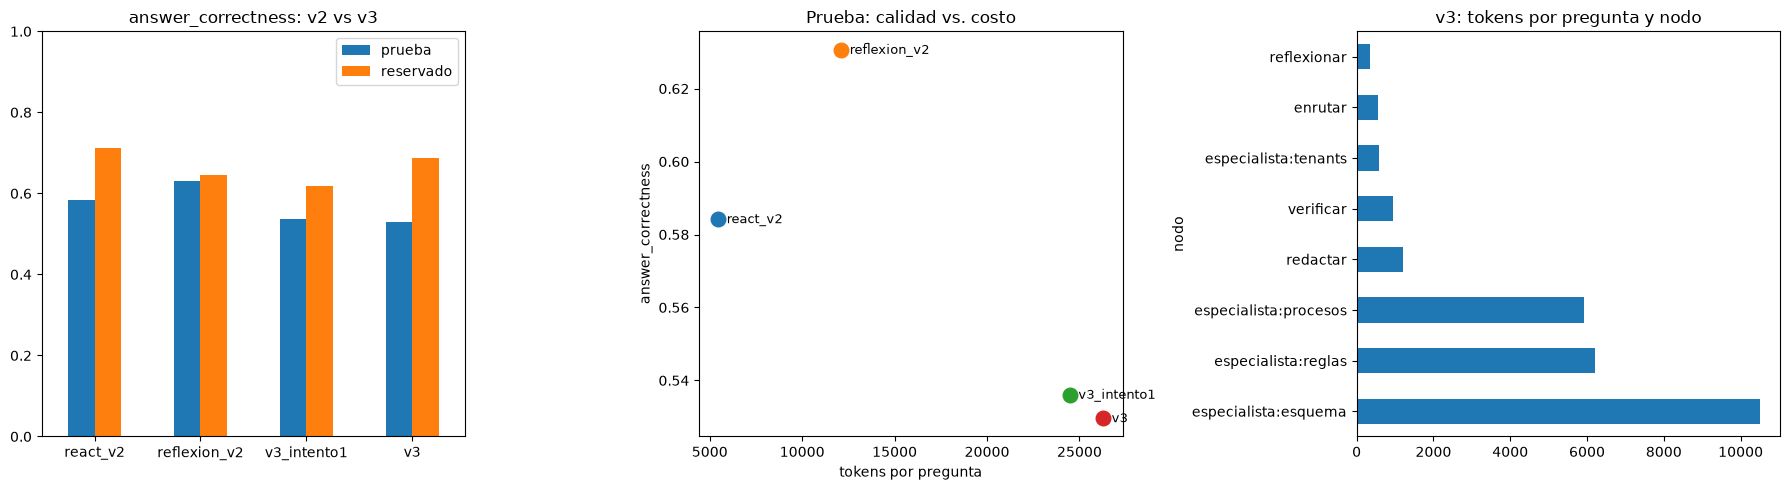

In [58]:
# Costo por nodo (promedio por pregunta, prueba)
costo_nodos = pd.DataFrame([{"id": r.id, "nodo": n, **c} for r in df_v3.itertuples() for n, c in r.costo_nodo.items()])
resumen_nodos = (costo_nodos.groupby("nodo")[["llamadas", "tokens"]].sum() / len(df_v3)).sort_values("tokens", ascending=False)
display(resumen_nodos.round(1))

fig, ejes = plt.subplots(1, 3, figsize=(18, 5))
pd.DataFrame({"prueba": res_prueba_v3["answer_correctness"], "reservado": res_reservado_v3["answer_correctness"]}
             ).plot.bar(ax=ejes[0], rot=0)
ejes[0].set_title("answer_correctness: v2 vs v3")
ejes[0].set_ylim(0, 1)

for n in res_prueba_v3.index:
    ejes[1].scatter(res_prueba_v3.loc[n, "tokens/preg"], res_prueba_v3.loc[n, "answer_correctness"], s=110)
    ejes[1].annotate(n, (res_prueba_v3.loc[n, "tokens/preg"], res_prueba_v3.loc[n, "answer_correctness"]),
                     textcoords="offset points", xytext=(6, -3), fontsize=9)
ejes[1].set_xlabel("tokens por pregunta")
ejes[1].set_ylabel("answer_correctness")
ejes[1].set_title("Prueba: calidad vs. costo")

resumen_nodos["tokens"].plot.barh(ax=ejes[2])
ejes[2].set_title("v3: tokens por pregunta y nodo")
plt.tight_layout()
plt.savefig(OUT_DIR / "comparacion_v3.png", dpi=150)
plt.show()

### 5C.9 Análisis por pregunta

Dónde gana o pierde la v3 frente a Reflexion v2, qué ramas eligió, cuántos hechos descartó el motor y qué cambió la reflexión entre el intento 1 y la respuesta final.

In [59]:
for etiqueta, todo in [("PRUEBA", TODO_V3), ("RESERVADO", TODO_H3)]:
    c = (todo["reflexion_v2"][["id", "tipo", "answer_correctness"]]
         .merge(todo["v3"][["id", "answer_correctness", "ramas", "veredictos", "n_registro", "n_descartados"]],
                on="id", suffixes=("_v2", "_v3")))
    c["delta"] = c["answer_correctness_v3"] - c["answer_correctness_v2"]
    print(f"\n{etiqueta}: gana v3 en {(c['delta'] > 0.05).sum()}, empata en {(c['delta'].abs() <= 0.05).sum()}, "
          f"pierde en {(c['delta'] < -0.05).sum()}")
    display(c.sort_values("delta").round(2))
    print("answer_correctness por tipo:")
    display(pd.DataFrame({n: todo[n].groupby("tipo")["answer_correctness"].mean() for n in ["reflexion_v2", "v3"]}).round(2))

# Aporte de la reflexión dentro de la v3: intento 1 contra respuesta final
for etiqueta, todo in [("PRUEBA", TODO_V3), ("RESERVADO", TODO_H3)]:
    i1 = todo["v3_intento1"].set_index("id")["answer_correctness"]
    fin = todo["v3"].set_index("id")
    multi = fin["intentos"] > 1
    delta = (fin["answer_correctness"] - i1)[multi]
    print(f"\n[{etiqueta}] reflexionaron {int(multi.sum())} preguntas: mejoran {(delta > 0.05).sum()}, "
          f"igual {(delta.abs() <= 0.05).sum()}, empeoran {(delta < -0.05).sum()} | "
          f"answer_correctness intento 1 = {i1.mean():.3f} → final = {fin['answer_correctness'].mean():.3f}")
for r in df_v3[df_v3["intentos"] > 1].head(5).itertuples():
    print(f"\n{r.id} [{r.veredictos}]\n  intento 1: {r.react_respuesta[:160]}\n  lección:   {r.lecciones[0][:220]}\n  final:     {r.respuesta[:160]}")

# Hechos que el motor descartó en prueba: qué tipo de alucinación atrapó
descartes = [(r.id, l) for r in df_v3.itertuples() for l in r.descartados]
print(f"\nHechos descartados en prueba: {len(descartes)}")
for pid, l in descartes[:15]:
    print(f"  {pid}: {l}")


PRUEBA: gana v3 en 6, empata en 5, pierde en 14


,id,tipo,answer_correctness_v2,answer_correctness_v3,ramas,veredictos,n_registro,n_descartados,delta
13,p14,Join,0.81,0.12,"[procesos, esquema]",PASS,17,10,-0.69
14,p15,Join,0.74,0.13,"[esquema, procesos]",PASS,31,6,-0.62
18,p19,Comparación,0.67,0.09,[tenants],PASS,1,5,-0.57
17,p18,Regla,0.60,0.07,[reglas],PASS,0,0,-0.53
6,p07,Esquema,0.84,0.36,"[esquema, reglas]",PASS,17,0,-0.48
3,p04,Proceso,0.77,0.48,"[procesos, reglas]",PASS,19,7,-0.29
12,p13,Join,0.67,0.40,"[procesos, esquema, reglas]",FAIL → PASS,70,2,-0.27
8,p09,Esquema,0.95,0.81,"[reglas, esquema]",PASS,13,2,-0.14
11,p12,Join,0.55,0.43,[esquema],PASS,13,3,-0.12
20,p21,Comparación,0.58,0.48,"[esquema, procesos]",PASS,7,2,-0.11


answer_correctness por tipo:


,reflexion_v2,v3
tipo,,
Comparación,0.53,0.30
Esquema,0.89,0.75
Formulario,0.56,0.70
Join,0.64,0.35
Proceso,0.71,0.72
Regla,0.59,0.36
Sin respuesta,0.46,0.75
Trampa,0.40,0.37



RESERVADO: gana v3 en 7, empata en 3, pierde en 2


,id,tipo,answer_correctness_v2,answer_correctness_v3,ramas,veredictos,n_registro,n_descartados,delta
7,h08,Join,0.80,0.47,[esquema],FAIL → PASS,13,4,-0.33
2,h03,Proceso,0.70,0.45,"[reglas, esquema, procesos]",FAIL → PASS,29,1,-0.25
9,h10,Comparación,0.90,0.89,"[tenants, esquema]",FAIL → PASS,16,7,-0.00
8,h09,Regla,0.98,0.98,[reglas],PASS,1,1,-0.00
10,h11,Trampa,0.40,0.41,"[procesos, tenants]",PASS,33,8,0.01
0,h01,Proceso,0.46,0.53,"[procesos, reglas]",PASS,35,11,0.06
4,h05,Esquema,0.69,0.79,[esquema],PASS,9,3,0.10
1,h02,Proceso,0.75,0.85,"[procesos, reglas, esquema]",PASS,51,7,0.11
3,h04,Formulario,0.84,0.95,[procesos],PASS,6,0,0.11
5,h06,Esquema,0.55,0.67,"[reglas, esquema]",PASS,11,3,0.12


answer_correctness por tipo:


,reflexion_v2,v3
tipo,,
Comparación,0.90,0.89
Esquema,0.62,0.73
Formulario,0.84,0.95
Join,0.50,0.46
Proceso,0.64,0.61
Regla,0.98,0.98
Sin respuesta,0.46,0.81
Trampa,0.40,0.41



[PRUEBA] reflexionaron 6 preguntas: mejoran 1, igual 3, empeoran 2 | answer_correctness intento 1 = 0.536 → final = 0.530

[RESERVADO] reflexionaron 3 preguntas: mejoran 1, igual 0, empeoran 2 | answer_correctness intento 1 = 0.619 → final = 0.687

p05 [FAIL → PASS]
  intento 1: El formulario pide: t0711z1.monto, t0711z1.tipo_pago, t0711z1.responsable y t0711z1.observacion (apertura: “Monto, Tipo de pago, Responsable, Observación”).  
S
  lección:   DIAGNÓSTICO: La falla ocurrió por agregar campos con formato de tabla/columna no respaldados por el registro; se ignoró que solo estaban verificados los datos del formulario y las tablas, sin columnas ni relaciones concr
  final:     El formulario de **Apertura** pide: **monto**, **tipo de pago**, **responsable** y **observación**.  
Se guarda en la(s) tabla(s) **t0711z1** y **t0101**.

p08 [FAIL → FAIL → FAIL]
  intento 1: El precio de venta se guarda en **t4106.mnPrecioVentaPublico** (PVP).  
La vigencia se controla con **t4106.jdFechaIn

## 5D. Versión 4: datos en vivo del tenant como herramienta

La v3 responde sobre el **esquema**, pero ante una pregunta sobre **filas** ("¿qué cliente debe más?") solo puede abstenerse: el grafo no tiene datos. La v4 conecta el sistema a la base MySQL de un tenant real (**Garage84**) para que el agente que corresponde, y solo ese, la consulte en tiempo real.

**Qué cambia en la arquitectura**

| Pieza | v3 | v4 |
|---|---|---|
| `enrutar` | `datos_de_filas` → abstención | filas de Garage84 → especialista **datos**; filas de otro tenant → abstención (sin conexión); pedir modificar datos → rechazo sin especialistas (`pide_modificar`) |
| Especialistas | procesos · esquema · tenants · reglas | + **datos** (`ver_tabla`, `camino_join`, `consultar_sql`). Es el **único** con acceso a la base |
| `consultar_sql` (nueva) | — | Pasa por la **guardia SQL** y ejecuta en una transacción de solo lectura. Devuelve un id `sql:qN` que queda en el registro de consultas |
| Guardia SQL (nueva, sin LLM) | — | Solo una sentencia `SELECT`, sin palabras de escritura ni otras bases; tablas, columnas y joins **validados contra el grafo**; `LIMIT ≤ MAX_FILAS` |
| `Hecho` | 7 tipos | + `dato` con `consulta_id` |
| `motor` | valida contra el grafo | + un `dato` se acepta solo si su consulta se ejecutó con éxito **para ese especialista** y sus números están en el resultado. + **normalización**: si `tabla`/`columna` vienen vacías, las toma del texto (hallazgo 1 de la v3) |
| `verificar` | identificadores ⊆ registro | + **números** de la respuesta ⊆ resultados de las consultas del registro |

**Seguridad de la conexión** (defensa en capas)

1. **Credenciales fuera del código**: `KERBEROS_JDBC_URL` vive en `.env`, que está en `.gitignore`. El notebook no imprime la contraseña.
2. **Guardia determinista** antes de tocar la base (sección 5D.2).
3. **Sesión de solo lectura**: `SET SESSION TRANSACTION READ ONLY`, `START TRANSACTION READ ONLY`, `ROLLBACK` al final y tiempo máximo por consulta (`MAX_SEG_SQL`).
4. **Mínimo de filas**: `LIMIT ≤ MAX_FILAS`; el especialista debe agregar (`COUNT`, `SUM`, `GROUP BY`).
5. **Datos personales**: las columnas de correo, teléfono, identificación y dirección se enmascaran **antes** de que el resultado llegue al LLM (`ENMASCARAR_PII`). Aun así, los nombres y montos sí se envían a OpenAI.
6. **Recomendado fuera del notebook**: un usuario MySQL con permiso **solo `SELECT`** sobre `dveloper_garage84`. La celda 5D.4 muestra los permisos reales del usuario configurado.

**Cómo se evalúa**

- **Conjunto en vivo** (`eval/preguntas_vivo.jsonl`, 10 preguntas): 7 piden datos de Garage84, cada una con un **SQL de referencia** escrito a mano contra el grafo; 1 pide datos de otro tenant (abstención), 1 es de esquema (no debe tocar la base) y 1 pide modificar datos (rechazo). La métrica principal es la **exactitud de ejecución**: qué fracción de los valores del resultado de referencia aparece en la respuesta. Se compara la v3 (que no tiene acceso) con la v4, con su costo.
- **Comportamiento del agente**: qué rama eligió el enrutador, qué especialista consumió la base, cuántas consultas bloqueó la guardia y cuántas fallaron en la base.
- **Regresión**: la v4 sobre prueba (25) y reservado (12), contra la v3. `p25` ("¿qué cliente de Garage84 tiene la mayor deuda?") ya no es "Sin respuesta", así que se reporta aparte.

In [60]:
import pymysql
from decimal import Decimal
from datetime import date, datetime, timedelta
from urllib.parse import urlsplit, parse_qs


def leer_jdbc(url):
    # jdbc:mysql://host[:puerto]/base?user=...&password=...  →  parámetros de pymysql
    partes = urlsplit(url.strip().removeprefix("jdbc:"))
    q = {k: v[0] for k, v in parse_qs(partes.query, keep_blank_values=True).items()}
    return {"host": partes.hostname, "port": partes.port or 3306, "database": partes.path.lstrip("/"),
            "user": q.get("user", ""), "password": q.get("password", "")}


_URL_BD = os.getenv("KERBEROS_JDBC_URL", "")
BD = leer_jdbc(_URL_BD) if _URL_BD else None
TENANT_VIVO = BD["database"] if BD else "dveloper_garage84"
TENANT_VIVO_CORTO = TENANT_VIVO.replace("dveloper_", "")

MAX_FILAS = 20               # filas máximas que devuelve una consulta
MAX_SEG_SQL = 8              # tiempo máximo de una consulta en el servidor
MAX_STEPS_DATOS = 6          # pasos ReAct del especialista de datos (ver_tabla, camino_join, consultar_sql, reintento)
ENMASCARAR_PII = True        # oculta correo, teléfono, identificación y dirección antes de enviar al LLM
SOLO_JOINS_DEL_GRAFO = True  # la guardia rechaza joins sin INFERRED_LINK (la misma regla que el motor)
NORMALIZAR_HECHOS = True     # arreglo del hallazgo 1 de la v3: tabla/columna vacías se toman del texto

if BD:
    print(f"Base en vivo: {BD['user']}@{BD['host']}:{BD['port']}/{BD['database']} (la contraseña viene de .env y no se imprime)")
else:
    print("Sin KERBEROS_JDBC_URL en .env: consultar_sql responderá que no hay conexión.")


def _valor(v):
    # Tipos de MySQL → tipos de JSON
    if isinstance(v, Decimal):
        return float(v)
    if isinstance(v, (date, datetime)):
        return v.isoformat()
    if isinstance(v, timedelta):
        return str(v)
    if isinstance(v, (bytes, bytearray)):
        return v.decode("utf-8", "replace")
    return v


def ejecutar_sql(sql, max_filas=MAX_FILAS):
    # Una conexión por consulta, en una sesión y transacción de solo lectura, con tiempo máximo
    t0 = time.perf_counter()
    con = pymysql.connect(host=BD["host"], port=BD["port"], user=BD["user"], password=BD["password"],
                          database=BD["database"], charset="utf8mb4", connect_timeout=10,
                          read_timeout=MAX_SEG_SQL + 5, autocommit=False)
    try:
        with con.cursor() as cur:
            cur.execute("SET SESSION TRANSACTION READ ONLY")
            for limite in (f"SET SESSION max_execution_time = {MAX_SEG_SQL * 1000}",   # MySQL ≥ 5.7.8
                           f"SET SESSION max_statement_time = {MAX_SEG_SQL}"):           # MariaDB
                try:
                    cur.execute(limite)
                    break
                except pymysql.MySQLError:
                    continue
            cur.execute("START TRANSACTION READ ONLY")
            cur.execute(sql)
            columnas = [d[0] for d in cur.description or []]
            filas = [[_valor(v) for v in f] for f in cur.fetchmany(max_filas + 1)]
        con.rollback()
    finally:
        con.close()
    return columnas, filas, round(time.perf_counter() - t0, 3)

Base en vivo: dveloper_garage84_cue@www.d3veloperstudio.com:3306/dveloper_garage84 (la contraseña viene de .env y no se imprime)


### 5D.2 La guardia SQL (determinista)

Antes de tocar la base, `vigilar_sql` revisa la consulta sin llamar al LLM. Es la misma idea del motor de hechos (el LLM propone, Python decide), aplicada a la consulta:

| Regla | Si no se cumple |
|---|---|
| Una sola sentencia, sin comentarios (`;`, `--`, `#`, `/* */`) | se bloquea |
| Empieza con `SELECT` | se bloquea |
| Sin palabras de escritura o riesgo (`INSERT`, `UPDATE`, `DELETE`, DDL, `INTO`, `SET`, `SLEEP`, `LOAD_FILE`, …), fuera de los literales | se bloquea |
| No nombra otras bases (`mysql.`, `information_schema.`, `dveloper_*.`) | se bloquea |
| Cada tabla de `FROM`/`JOIN` existe en el grafo; los alias se resuelven y cada `tabla.columna` existe | se bloquea con la lista de errores |
| Cada join `A.x = B.y` está en `LINKS_VALIDOS` (si `SOLO_JOINS_DEL_GRAFO`) | se bloquea y se sugiere `camino_join` |
| `LIMIT ≤ MAX_FILAS` | sin `LIMIT` se agrega; mayor se bloquea |

El motivo del bloqueo vuelve al especialista como observación, así que puede corregir la consulta en el mismo ciclo ReAct. La celda prueba la guardia con consultas escritas a mano, **sin conectarse** a la base.

In [61]:
PROHIBIDAS = re.compile(
    r"\b(insert|update|delete|replace|merge|upsert|drop|alter|create|truncate|rename|grant|revoke|lock|unlock|"
    r"call|execute|prepare|deallocate|set|handler|load|load_file|outfile|dumpfile|into|sleep|benchmark|get_lock|"
    r"release_lock|shutdown|kill|flush|reset|purge|install|uninstall)\b", re.IGNORECASE)
OTRAS_BASES = re.compile(r"\b(information_schema|mysql|performance_schema|sys|dveloper_\w+)\s*\.", re.IGNORECASE)
# El alias va en un lookahead: así "FROM t03b11 JOIN t0101 c" no se come el JOIN siguiente
RE_FROM = re.compile(r"\b(?:from|join)\s+`?(\w+)`?(?=(?:\s+(?:as\s+)?`?(\w+)`?)?)", re.IGNORECASE)
RESERVADAS = {"where", "join", "left", "right", "inner", "outer", "cross", "natural", "straight_join", "on", "using",
              "group", "order", "limit", "having", "union", "window", "for"}
RE_LIMIT = re.compile(r"\blimit\s+(\d+)(?:\s*,\s*(\d+)|\s+offset\s+\d+)?\s*$", re.IGNORECASE)


def sin_literales(sql):
    # Reemplaza los literales de texto por '' para que su contenido no cuente como palabra clave ni identificador
    return re.sub(r"'(?:[^'\\]|\\.)*'|\"(?:[^\"\\]|\\.)*\"", "''", sql)


def vigilar_sql(sql):
    # Devuelve (aceptada, motivo, sql_final). No llama al LLM ni a la base
    s = sql.strip().rstrip(";").strip()
    if not s:
        return False, "consulta vacía", ""
    limpio = sin_literales(s)
    if ";" in limpio:
        return False, "una sola sentencia: no uses ';'", ""
    if re.search(r"--|#|/\*", limpio):
        return False, "no se permiten comentarios en la consulta", ""
    if not re.match(r"select\b", limpio, re.IGNORECASE):
        return False, "solo se permiten consultas SELECT", ""
    prohibida = PROHIBIDAS.search(limpio)
    if prohibida:
        return False, f"palabra no permitida en modo solo lectura: {prohibida.group(1).upper()}", ""
    if OTRAS_BASES.search(limpio):
        return False, f"solo se consulta la base {TENANT_VIVO}, sin prefijos de otra base", ""
    alias = {}
    for tabla, al in RE_FROM.findall(limpio):
        if tabla not in TABLAS and not tabla.startswith(TABLAS_RUNTIME):
            return False, f"la tabla {tabla} no está en el grafo del esquema", ""
        alias[tabla] = tabla
        if al and al.lower() not in RESERVADAS:
            alias[al] = tabla
    if not alias:
        return False, "la consulta no lee ninguna tabla del tenant", ""
    # Con los alias resueltos, el mismo verificador de esquema de la sección 4.3 revisa columnas y joins
    expandida = re.sub(r"\b(\w+)\.(\w+)\b", lambda m: f"{alias.get(m.group(1), m.group(1))}.{m.group(2)}", limpio)
    _, errores, _, errores_join = verificar_esquema(expandida)
    if not SOLO_JOINS_DEL_GRAFO:
        errores_join = []
    if errores + errores_join:
        return False, "esquema: " + "; ".join(errores + errores_join) + ". Revisa ver_tabla y camino_join.", ""
    limite = RE_LIMIT.search(s)
    if limite:
        n = int(limite.group(2) or limite.group(1))
        if n > MAX_FILAS:
            return False, f"LIMIT {n} supera el máximo de {MAX_FILAS} filas; agrega con COUNT/SUM/GROUP BY", ""
        return True, "aceptada", s
    return True, "aceptada (se agregó LIMIT)", f"{s} LIMIT {MAX_FILAS}"


# Pruebas sin conexión
for prueba in [
    "SELECT COUNT(*) AS clientes FROM t0101 WHERE t0101.szTipoPersona = 'CLI'",
    "SELECT c.szRazonSocial, SUM(o.importePendiente) AS pendiente FROM t03b11 o JOIN t0101 c ON o.nroDireccion = c.mnNroDireccion GROUP BY c.szRazonSocial ORDER BY pendiente DESC LIMIT 5",
    "SELECT o.importePendiente FROM t03b11 o JOIN t0101 c ON o.mnCodigoCliente = c.mnNroDireccion",
    "SELECT COUNT(*) FROM t57011z1 JOIN t0101 ON t57011z1.mnCodCliente = t0101.mnNroDireccion",
    "UPDATE t57011z1 SET szDutyStatus = 'V'",
    "SELECT * FROM t0101; DROP TABLE t0101",
    "SELECT * FROM t0101 INTO OUTFILE '/tmp/clientes.csv'",
    "SELECT user, authentication_string FROM mysql.user",
    "SELECT SLEEP(30)",
    "SELECT * FROM t4101 LIMIT 500",
    "SELECT COUNT(*) FROM t57011z1 WHERE t57011z1.szReference = 'DELETE FROM t0101'",
]:
    ok, motivo, final = vigilar_sql(prueba)
    print(f"{'✓' if ok else '✗'} {motivo}\n    {prueba[:110]}" + (f"\n    → {final[-60:]}" if ok and final != prueba else ""))

✓ aceptada (se agregó LIMIT)
    SELECT COUNT(*) AS clientes FROM t0101 WHERE t0101.szTipoPersona = 'CLI'
    → ientes FROM t0101 WHERE t0101.szTipoPersona = 'CLI' LIMIT 20
✓ aceptada
    SELECT c.szRazonSocial, SUM(o.importePendiente) AS pendiente FROM t03b11 o JOIN t0101 c ON o.nroDireccion = c.
✗ esquema: la columna t03b11.mnCodigoCliente no existe; el join t0101.mnNroDireccion = t03b11.mnCodigoCliente no es una relación válida del grafo. Revisa ver_tabla y camino_join.
    SELECT o.importePendiente FROM t03b11 o JOIN t0101 c ON o.mnCodigoCliente = c.mnNroDireccion
✗ esquema: el join t0101.mnNroDireccion = t57011z1.mnCodCliente no es una relación válida del grafo. Revisa ver_tabla y camino_join.
    SELECT COUNT(*) FROM t57011z1 JOIN t0101 ON t57011z1.mnCodCliente = t0101.mnNroDireccion
✗ solo se permiten consultas SELECT
    UPDATE t57011z1 SET szDutyStatus = 'V'
✗ una sola sentencia: no uses ';'
    SELECT * FROM t0101; DROP TABLE t0101
✗ palabra no permitida en modo solo lectura:

### 5D.3 La herramienta `consultar_sql`

Cada llamada recibe un id `sql:qN` y queda en `CONSULTAS` (el registro de consultas de la pregunta actual) con su SQL, su estado (`ok`, `bloqueada`, `error`), sus filas y su hora. El id se anota como evidencia **del especialista que la ejecutó**: el motor solo acepta un `dato` cuya consulta aparezca ahí.

In [62]:
CONSULTAS = {}   # sql:qN → consulta de la pregunta actual
RE_PII = re.compile(r"correo|e?mail|telf|telefono|^szcel|celular|identificadorfiscal|taxid|cedula|^szdireccion\d|"
                    r"addressline|direccionservicio", re.IGNORECASE)


def enmascarar(columnas, filas):
    if not ENMASCARAR_PII:
        return filas, []
    idx = [i for i, c in enumerate(columnas) if RE_PII.search(c)]
    for f in filas:
        for i in idx:
            if f[i] not in (None, ""):
                s = str(f[i])
                f[i] = "***" + s[-3:] if len(s) > 4 else "***"
    return filas, [columnas[i] for i in idx]


def tabla_texto(columnas, filas, ancho=60):
    lineas = [" | ".join(columnas)]
    lineas += [" | ".join("NULL" if v is None else str(v)[:ancho] for v in f) for f in filas]
    return "\n".join(lineas)


@tool
def consultar_sql(sql: str) -> str:
    '''Ejecuta UNA consulta SELECT de solo lectura contra la base tenant EN VIVO de Garage84 y devuelve las filas.
    Antes de ejecutar, una guardia valida la consulta contra el grafo: las tablas y columnas deben existir
    (confírmalas con ver_tabla) y los joins deben ser relaciones válidas (camino_join).
    Usa nombres completos tabla.columna, agrega con COUNT/SUM/GROUP BY y LIMIT de 20 filas como máximo.
    Devuelve el id [sql:qN] de la consulta: cítalo en los hechos de tipo dato.'''
    with _CANDADO:
        qid = f"sql:q{len(CONSULTAS) + 1}"
        CONSULTAS[qid] = reg = {"id": qid, "sql": sql, "estado": "pendiente"}
    ok, motivo, final = vigilar_sql(sql)
    if not ok:
        reg.update(estado="bloqueada", motivo=motivo)
        say(f"   [Guardia] ✗ {qid} bloqueada: {motivo}")
        return f"[{qid}] BLOQUEADA por la guardia: {motivo}"
    if not BD:
        reg.update(estado="error", motivo="sin conexión configurada", sql_final=final)
        return f"[{qid}] No hay conexión a la base en vivo (falta KERBEROS_JDBC_URL en .env)."
    try:
        columnas, filas, segundos = ejecutar_sql(final)
    except Exception as e:
        detalle = e.args[1] if isinstance(e, pymysql.MySQLError) and len(e.args) > 1 else str(e)
        reg.update(estado="error", motivo=str(detalle)[:200], sql_final=final)
        say(f"   [BD] ✗ {qid} error: {reg['motivo']}")
        return f"[{qid}] ERROR de la base: {reg['motivo']}. Corrige la consulta."
    truncada = len(filas) > MAX_FILAS
    filas, ocultas = enmascarar(columnas, filas[:MAX_FILAS])
    reg.update(estado="ok", sql_final=final, columnas=columnas, filas=filas, segundos=segundos, truncada=truncada,
               enmascaradas=ocultas, hora=datetime.now().isoformat(timespec="seconds"))
    _anotar(qid)
    say(f"   [BD] ✓ {qid} {len(filas)} fila(s) en {segundos:.2f} s: {final[:160]}")
    return (f"[{qid}] {len(filas)} fila(s) de {TENANT_VIVO} en {segundos:.2f} s, consultado {reg['hora']}"
            + (f" · resultado truncado a {MAX_FILAS} filas" if truncada else "")
            + (f" · columnas enmascaradas: {', '.join(ocultas)}" if ocultas else "")
            + "\n" + tabla_texto(columnas, filas))

### 5D.4 Prueba de conexión, permisos y deriva del esquema

Una sola vez por sesión: la versión del servidor, los **permisos reales** del usuario (si tiene más que `SELECT`, la guardia y la transacción de solo lectura son la única protección, y conviene pedir un usuario de solo lectura), y la **deriva** entre la base en vivo y el grafo leído el 2026-10-09: tablas o columnas que existen en un lado y no en el otro. Estas consultas fijas no pasan por la guardia porque leen `information_schema`.

In [63]:
if BD:
    try:
        cols, filas, seg = ejecutar_sql("SELECT VERSION() AS version, DATABASE() AS base, CURRENT_USER() AS usuario")
        print(f"Conexión OK en {seg:.2f} s:", dict(zip(cols, filas[0])))
        _, permisos, _ = ejecutar_sql("SHOW GRANTS FOR CURRENT_USER()", max_filas=50)
        print("Permisos del usuario:")
        for p in permisos:
            print("  ", re.sub(r"IDENTIFIED BY .*", "IDENTIFIED BY ***", p[0]))
        if not all(re.search(r"GRANT (SELECT|USAGE)\b(?!,)", p[0]) for p in permisos):
            print("ATENCIÓN: el usuario tiene permisos además de SELECT. La guardia y la transacción READ ONLY lo "
                  "contienen, pero se recomienda un usuario solo SELECT.")

        _, vivas, _ = ejecutar_sql("SELECT table_name FROM information_schema.tables WHERE table_schema = DATABASE()", max_filas=2000)
        _, cols_vivas, _ = ejecutar_sql("SELECT table_name, column_name FROM information_schema.columns "
                                        "WHERE table_schema = DATABASE()", max_filas=20000)
        vivas = {t for (t,) in vivas}
        en_grafo = {n["properties"]["name"] for n in GRAFO["nodes"]
                    if n["type"] == "table" and TENANT_VIVO in n["properties"]["bases"]}
        print(f"\nTablas: en vivo={len(vivas)} | en el grafo para {TENANT_VIVO_CORTO}={len(en_grafo)}")
        print("  solo en vivo (el grafo no las conoce, la guardia las bloquea):", sorted(vivas - en_grafo) or "ninguna")
        print("  solo en el grafo (ya no existen en vivo):", sorted(en_grafo - vivas) or "ninguna")
        por_tabla = {}
        for t, c in cols_vivas:
            por_tabla.setdefault(t, set()).add(c)
        deriva = {t: (sorted(por_tabla.get(t, set()) - COLUMNAS.get(t, set())), sorted(COLUMNAS.get(t, set()) - por_tabla.get(t, set())))
                  for t in en_grafo & vivas}
        deriva = {t: d for t, d in deriva.items() if d[0] or d[1]}
        print(f"  tablas con columnas distintas: {len(deriva)}")
        for t, (nuevas, faltan) in list(deriva.items())[:10]:
            print(f"    {t}: nuevas en vivo={nuevas[:6]} | faltan en vivo={faltan[:6]}")
    except Exception as e:
        print("No se pudo conectar:", type(e).__name__, str(e)[:200])

Conexión OK en 1.62 s: {'version': '10.6.20-MariaDB-cll-lve-log', 'base': 'dveloper_garage84', 'usuario': 'dveloper_garage84_cue@%'}
Permisos del usuario:
   GRANT USAGE ON *.* TO `dveloper_garage84_cue`@`%` IDENTIFIED BY ***
   GRANT ALL PRIVILEGES ON `dveloper\_garage84`.* TO `dveloper_garage84_cue`@`%`
ATENCIÓN: el usuario tiene permisos además de SELECT. La guardia y la transacción READ ONLY lo contienen, pero se recomienda un usuario solo SELECT.

Tablas: en vivo=54 | en el grafo para garage84=54
  solo en vivo (el grafo no las conoce, la guardia las bloquea): ninguna
  solo en el grafo (ya no existen en vivo): ninguna
  tablas con columnas distintas: 5
    t4105: nuevas en vivo=['secuencial'] | faltan en vivo=['secuencia']
    t4111: nuevas en vivo=['secuencial'] | faltan en vivo=[]
    t57011: nuevas en vivo=['mnCodCliente-ShipTo', 'szPrintData(Y/N)', 'szSalesTaxable(Y/N)'] | faltan en vivo=['mnCodCliente_ShipTo', 'szPrintDataYN', 'szSalesTaxableYN']
    t0911: nuevas en vivo=['

### 5D.5 El especialista de datos, el enrutador y el formato de los hechos

El enrutador decide **quién** consume la base. El especialista **datos** es el único que recibe `consultar_sql`; los otros cuatro siguen trabajando solo con el grafo. Su procedimiento es ReAct: confirma columnas con `ver_tabla`, confirma el join con `camino_join`, consulta, y si la guardia o la base rechazan la consulta, la corrige con el motivo.

In [64]:
RAMAS_V4 = {**RAMAS, "datos": {
    "tools": [ver_tabla, camino_join, consultar_sql],
    "rol": f"datos en vivo de la base {TENANT_VIVO_CORTO} (solo lectura): conteos, saldos, totales y rankings de filas"}}


class HechoV4(Hecho):
    tipo: Literal["tabla", "columna", "join", "paso", "presencia", "regla", "dato", "no_consta"] = Field(
        description="tabla/columna: existe y qué guarda; join: relación entre dos columnas; paso: un paso de un "
                    "proceso o formulario; presencia: en qué tenants está una tabla; regla: regla de negocio; "
                    "dato: un valor leído de la base en vivo con consultar_sql; no_consta: la evidencia no tiene el dato")
    consulta_id: str = Field(default="", description="Solo dato: el id sql:qN de la consulta que devolvió el valor")


class HallazgosV4(BaseModel):
    hechos: list[HechoV4] = Field(default_factory=list)


class PlanV4(BaseModel):
    pide_modificar: bool = Field(description="True si la pregunta pide crear, cambiar, anular o borrar datos")
    datos_de_filas: bool = Field(description=f"True si pide filas o cifras de un tenant SIN conexión en vivo (cualquiera distinto de {TENANT_VIVO_CORTO})")
    ramas: list[Literal["procesos", "esquema", "tenants", "reglas", "datos"]] = Field(
        default_factory=list, description="Especialistas necesarios, normalmente uno. Vacío si datos_de_filas o pide_modificar")
    subpreguntas: list[str] = Field(default_factory=list, description="Una subpregunta autocontenida por rama, en el mismo orden")


class VeredictoV4(VeredictoV3):
    falta_rama: Literal["", "procesos", "esquema", "tenants", "reglas", "datos"] = Field(
        default="", description="Si faltan hechos para contestar, el especialista que debe buscarlos")


ENRUTADOR_V4 = '''Eres el enrutador de un sistema de especialistas sobre el ERP Kerberos (base tenant de Luna).
Especialistas disponibles:
''' + "\n".join(f"- {r}: {v['rol']}" for r, v in RAMAS_V4.items()) + f'''

Hay conexión EN VIVO, de solo lectura, a una sola base: {TENANT_VIVO} ({TENANT_VIVO_CORTO}).
- Si la pregunta pide filas o cifras de {TENANT_VIVO_CORTO} (cuántos, cuánto, qué cliente o producto tiene más, totales
  de un mes), o pide cifras sin nombrar un tenant: elige datos. Agrega otro especialista solo si además pide esquema o proceso.
- Si pide filas o cifras de otro tenant (lifecolor, indupan, labclinico1): datos_de_filas = True y ningún especialista.
- Si pide crear, cambiar, anular o borrar datos: pide_modificar = True y ningún especialista.
- Si la pregunta es de esquema, procesos, reglas o presencia de tablas: NO elijas datos; el grafo basta.
Elige el MÍNIMO de especialistas y escribe una subpregunta autocontenida para cada uno.'''

DATOS_PROMPT = REGLAS_V2 + f'''

Eres el especialista en datos EN VIVO de la base {TENANT_VIVO} (MySQL, solo lectura). Procedimiento:
1. ver_tabla de cada tabla que vayas a usar; usa solo columnas que aparezcan ahí.
2. Si necesitas unir tablas, camino_join; une solo por las columnas que devuelve.
3. consultar_sql con UNA consulta SELECT agregada (COUNT, SUM, GROUP BY, ORDER BY ... LIMIT) de {MAX_FILAS} filas como
   máximo, con nombres completos tabla.columna y fechas 'AAAA-MM-DD'.
4. Si la guardia bloquea la consulta o la base devuelve un error, corrígela con ese motivo (máximo 2 veces).
Reglas: excluye los documentos anulados (t57011z1.szDutyStatus = 'V') salvo que se pidan; nunca intentes modificar datos.
Cuando tengas el resultado, escribe LISTO y un resumen de una línea con los números exactos y el id sql:qN.'''

EXTRACTOR_V4 = EXTRACTOR_PROMPT + '''
- Llena SIEMPRE tabla (y columna) cuando el hecho trate de una tabla o columna; un hecho por tabla o columna.
- Un resultado de consultar_sql es un hecho de tipo dato: consulta_id = el id [sql:qN] de esa observación y los
  números copiados exactamente como aparecen (sin redondear). Una consulta BLOQUEADA o con ERROR no es un dato.'''

REDACTOR_V4 = REDACTOR_PROMPT + f'''
Para los hechos de tipo dato: copia los números exactamente como están en el registro y aclara que son datos en vivo de
{TENANT_VIVO_CORTO} a la hora de la consulta.'''

RECHAZO_V4 = (f"No se puede: el acceso a la base de {TENANT_VIVO_CORTO} es de solo lectura; el sistema no crea, "
              "modifica, anula ni borra datos.")
SIN_CONEXION_V4 = (f"No consta: solo hay conexión en vivo a {TENANT_VIVO_CORTO}; para los demás tenants el grafo "
                   "describe el esquema, no las filas.")


def prompt_especialista_v4(rama, memoria, leccion):
    if rama != "datos":
        return prompt_especialista(rama, memoria, leccion)
    texto = DATOS_PROMPT
    if leccion:
        texto += "\n\nYa intentaste esta pregunta y fue REPROBADA. Lecciones (no repitas esos errores):\n" + leccion
    return texto


llm_enrutador_v4 = llm.with_structured_output(PlanV4, method="function_calling", include_raw=True)
llm_extractor_v4 = llm.with_structured_output(HallazgosV4, method="function_calling", include_raw=True)
llm_verificador_v4 = llm_eval.with_structured_output(VeredictoV4, method="function_calling", include_raw=True)
print(ENRUTADOR_V4)

Eres el enrutador de un sistema de especialistas sobre el ERP Kerberos (base tenant de Luna).
Especialistas disponibles:
- procesos: procesos de menú y formularios: quién entra, por qué menú, pasos en orden y tablas que escribe
- esquema: tablas, columnas, claves primarias y joins válidos entre tablas
- tenants: presencia de tablas en los cuatro tenants, tablas exclusivas y filas estimadas
- reglas: reglas de negocio: tipos de documento, tipos de persona, estados (anulado, pendiente), códigos
- datos: datos en vivo de la base garage84 (solo lectura): conteos, saldos, totales y rankings de filas

Hay conexión EN VIVO, de solo lectura, a una sola base: dveloper_garage84 (garage84).
- Si la pregunta pide filas o cifras de garage84 (cuántos, cuánto, qué cliente o producto tiene más, totales
  de un mes), o pide cifras sin nombrar un tenant: elige datos. Agrega otro especialista solo si además pide esquema o proceso.
- Si pide filas o cifras de otro tenant (lifecolor, indupan, labclinico1):

### 5D.6 El motor v4: normalización y anclaje numérico

Dos cambios, los dos sin LLM:

1. **Normalización** (`normalizar_hecho`). En la v3, el 82 % de los descartes de prueba se debía a hechos con `tabla` o `columna` vacías ("El kardex es t4111" con `tabla=""`). Ahora, si el campo falta, se toma del texto con las mismas expresiones regulares del verificador; un texto con varias tablas se divide en un hecho por tabla. El hecho sigue pasando por la validación de siempre: la normalización no acepta nada que el grafo no confirme.
2. **Anclaje numérico** de los `dato`: la `consulta_id` debe ser una consulta que **ese especialista** ejecutó con éxito, y cada número del texto debe estar en su resultado (o en el SQL, como el año de un filtro). Un número que el LLM inventó o redondeó mal se descarta antes de redactar.

In [65]:
RE_NUM = re.compile(r"(?<![\w.,:/-])-?\d+(?:[.,]\d+)*")


def candidatos(s):
    # Lecturas posibles de un número escrito en es-EC o en-US: '1.234,56', '1,234.56', '1234.5', '1.234'
    negativo, s = s.startswith("-"), s.lstrip("-")
    variantes = [s.replace(".", "").replace(",", "."), s.replace(",", "")]
    if s.count(".") + s.count(",") <= 1:
        variantes.append(s.replace(",", "."))
    salida = set()
    for v in variantes:
        try:
            x = float(v)
            salida.add(-x if negativo else x)
        except ValueError:
            pass
    return salida


def cerca(x, v):
    x, v = abs(x), abs(v)   # "egresó 120,50" corresponde a un egreso de -120.5
    return abs(x - v) <= max(0.011, 0.005 * v) or x == round(v)


def numeros_de_resultado(c):
    nums = {float(len(c.get("filas", [])))}
    for f in c.get("filas", []):
        for v in f:
            if isinstance(v, bool) or v is None:
                continue
            if isinstance(v, (int, float)):
                nums.add(float(v))
            else:
                nums |= {x for s in RE_NUM.findall(str(v)) for x in candidatos(s)}
    nums |= {x for s in RE_NUM.findall(c.get("sql_final", "")) for x in candidatos(s)}   # p. ej. el año de un filtro
    return nums


def numeros_fuera(texto, permitidos):
    fuera = []
    for s in RE_NUM.findall(texto):
        cands = candidatos(s)
        if any(x == int(x) and 0 <= x <= 10 for x in cands):   # enumeraciones cortas ("2 tablas", "1 cliente")
            continue
        if not any(cerca(x, p) for x in cands for p in permitidos):
            fuera.append(s)
    return fuera


def normalizar_hecho(h):
    # Arreglo del hallazgo 1 de la v3: tabla/columna vacías se completan con los identificadores del texto
    if not NORMALIZAR_HECHOS or h["tipo"] not in ("tabla", "columna", "presencia") or h.get("base") == "sugar":
        return [h]
    tabla = h.get("tabla", "").removeprefix("table:").strip()
    columna = h.get("columna", "").strip()
    if (h["tipo"] == "columna" and tabla and columna) or (h["tipo"] != "columna" and tabla):
        return [h]
    tablas, calificadas, sueltas, _ = identificadores(h["texto"])
    if h["tipo"] == "columna":
        pares = sorted(calificadas) or ([(tabla, c) for c in sorted(sueltas)] if tabla else [])
        nuevos = [{**h, "tabla": t, "columna": c, "normalizado": True} for t, c in pares]
    elif h["tipo"] == "presencia":
        unicas = sorted(tablas)
        nuevos = [{**h, "tabla": unicas[0], "normalizado": True}] if len(unicas) == 1 else []
    else:
        nuevos = [{**h, "tabla": t, "normalizado": True} for t in sorted(tablas)]
    return nuevos or [h]


def validar_hecho_v4(h):
    if h["tipo"] != "dato":
        return validar_hecho(h)
    c = CONSULTAS.get(h.get("consulta_id", "").strip())
    if not c:
        return False, f"consulta inexistente: {h.get('consulta_id') or '(vacía)'}"
    if c["estado"] != "ok":
        return False, f"la consulta {c['id']} no devolvió filas ({c['estado']})"
    if c["id"] not in h.get("vistos", []):
        return False, f"la consulta {c['id']} no la ejecutó este especialista"
    fuera = numeros_fuera(h["texto"], numeros_de_resultado(c))
    if fuera:
        return False, f"números que no están en el resultado de {c['id']}: {', '.join(fuera)}"
    _, errores, _, errores_join = verificar_esquema(h["texto"])
    if errores + errores_join:
        return False, "; ".join(errores + errores_join)
    return True, f"anclado en {c['id']}"


def linea_hecho_v4(h):
    if h["tipo"] != "dato":
        return linea_hecho(h)
    c = CONSULTAS.get(h.get("consulta_id", ""), {})
    return f"[dato] {h.get('consulta_id', '')} ({c.get('hora', '')}; {c.get('sql_final', '')[:300]}): {h['texto']}"


# Pruebas del motor v4 con hechos escritos a mano (sin LLM y sin base)
CONSULTAS.clear()
CONSULTAS["sql:q1"] = {"id": "sql:q1", "estado": "ok", "columnas": ["clientes"], "filas": [[3912]], "hora": "(prueba)",
                       "sql_final": "SELECT COUNT(*) AS clientes FROM t0101 WHERE t0101.szTipoPersona = 'CLI' LIMIT 20"}
for prueba in [
    {"tipo": "tabla", "texto": "El kardex es t4111.", "tabla": ""},
    {"tipo": "columna", "texto": "Clave primaria: mnNroTransaccion, szCompanyOrden.", "tabla": "t4111", "columna": ""},
    {"tipo": "dato", "texto": "Garage84 tiene 3.912 fichas CLI en t0101", "consulta_id": "sql:q1", "vistos": ["sql:q1"]},
    {"tipo": "dato", "texto": "Garage84 tiene 4.100 fichas CLI", "consulta_id": "sql:q1", "vistos": ["sql:q1"]},
    {"tipo": "dato", "texto": "Garage84 tiene 3.912 fichas CLI", "consulta_id": "sql:q1", "vistos": []},
]:
    for h in normalizar_hecho({"columna": "", **prueba}):
        print(validar_hecho_v4(h), "←", linea_hecho_v4({"tabla": "", "columna": "", **h})[:110])
CONSULTAS.clear()

(True, 'verificado') ← [tabla] t4111: El kardex es t4111.
(True, 'verificado') ← [columna] t4111.mnNroTransaccion: Clave primaria: mnNroTransaccion, szCompanyOrden.
(True, 'verificado') ← [columna] t4111.szCompanyOrden: Clave primaria: mnNroTransaccion, szCompanyOrden.
(True, 'anclado en sql:q1') ← [dato] sql:q1 ((prueba); SELECT COUNT(*) AS clientes FROM t0101 WHERE t0101.szTipoPersona = 'CLI' LIMIT 20): G
(False, 'números que no están en el resultado de sql:q1: 4.100') ← [dato] sql:q1 ((prueba); SELECT COUNT(*) AS clientes FROM t0101 WHERE t0101.szTipoPersona = 'CLI' LIMIT 20): G
(False, 'la consulta sql:q1 no la ejecutó este especialista') ← [dato] sql:q1 ((prueba); SELECT COUNT(*) AS clientes FROM t0101 WHERE t0101.szTipoPersona = 'CLI' LIMIT 20): G


### 5D.7 El grafo de la v4

```
START → recordar → enrutar ─┬─(Send)→ especialista[procesos | esquema | tenants | reglas]   (grafo)
                            ├─(Send)→ especialista[datos] ── consultar_sql → guardia → MySQL Garage84 (solo lectura)
                            ├─(otro tenant: sin conexión)───────────┐
                            └─(pide modificar: rechazo)─────────────┤
                                                                    ↓
              motor (normaliza + valida grafo + ancla datos en CONSULTAS) → redactar → verificar ──(PASS)──→ END
                                    ↑                                        ↑          │ FAIL
                                    └──────── (falta un especialista) ── reflexionar ←──┘
```

El grafo de nodos es el de la v3; cambian el enrutador, los especialistas disponibles, el motor y el verificador. `CONSULTAS` se vacía al inicio de cada pregunta, igual que `EVIDENCIA`.

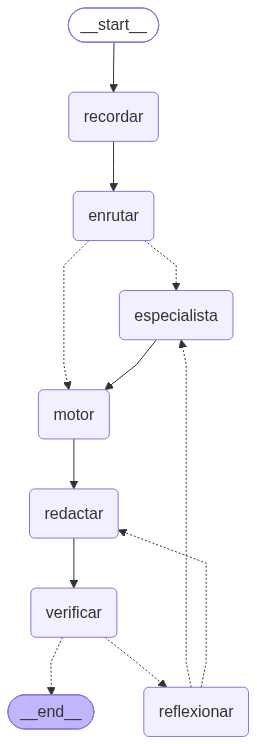

In [66]:
PRIMER_V4 = {}
_T0V4 = [0.0]


class EstadoV4(EstadoV3):
    pide_modificar: bool
    normalizados: int


def nodo_enrutar_v4(state):
    texto = state["pregunta"] + (f"\n\nCasos parecidos ya verificados:\n{state['memoria']}" if state["memoria"] else "")
    salida = llamar_llm([SystemMessage(content=ENRUTADOR_V4), HumanMessage(content=texto)],
                        modelo=llm_enrutador_v4, etapa="enrutar")
    plan = salida["parsed"] or PlanV4(pide_modificar=False, datos_de_filas=False, ramas=["esquema"], subpreguntas=[state["pregunta"]])
    sin_ramas = plan.pide_modificar or plan.datos_de_filas
    ramas = [] if sin_ramas else list(dict.fromkeys(plan.ramas)) or ["esquema"]
    subs = [plan.subpreguntas[i] if i < len(plan.subpreguntas) and plan.subpreguntas[i] else state["pregunta"]
            for i in range(len(ramas))]
    say(f"[Enrutar] pide_modificar={plan.pide_modificar} | datos_de_filas={plan.datos_de_filas} | ramas={ramas} | {subs}")
    return {"pide_modificar": plan.pide_modificar, "datos_de_filas": plan.datos_de_filas, "ramas": ramas, "subpreguntas": subs}


def despachar_v4(state):
    if state["pide_modificar"] or state["datos_de_filas"] or not state["ramas"]:
        return "motor"
    return _envios(state, state["ramas"], state["subpreguntas"])


def nodo_especialista_v4(payload):
    # Igual que en la v3, con la rama datos y el extractor que conoce el tipo dato
    rama = payload["rama"]
    _HILO.evidencia = []
    herramientas = {t.name: t for t in RAMAS_V4[rama]["tools"]}
    llm_rama = llm.bind_tools(RAMAS_V4[rama]["tools"])
    mensajes = [SystemMessage(content=prompt_especialista_v4(rama, payload["memoria"], payload["leccion"])),
                HumanMessage(content=f"{payload['subpregunta']}\n\n(Pregunta original: {payload['pregunta']})")]
    for _ in range(MAX_STEPS_DATOS if rama == "datos" else MAX_STEPS_ESP):
        r = llamar_llm(mensajes, modelo=llm_rama, etapa=f"especialista:{rama}")
        mensajes.append(r)
        if not r.tool_calls:
            break
        for tc in r.tool_calls:
            mensajes.append(ToolMessage(content=invocar_herramienta(herramientas, tc), tool_call_id=tc["id"]))
    vistos = list(_HILO.evidencia)
    _HILO.evidencia = None
    hechos = []
    if any(isinstance(m, ToolMessage) for m in mensajes):
        salida = llamar_llm([SystemMessage(content=EXTRACTOR_V4),
                             HumanMessage(content=f"SUBPREGUNTA: {payload['subpregunta']}\n\nTRAYECTORIA:\n"
                                                  f"{trayectoria_de(mensajes, obs_chars=2500)}")],
                            modelo=llm_extractor_v4, etapa=f"especialista:{rama}")
        if salida["parsed"]:
            hechos = [{**h.model_dump(), "rama": rama, "vistos": vistos} for h in salida["parsed"].hechos]
    llamadas = [f"{tc['name']}({tc['args']})" for m in mensajes if isinstance(m, AIMessage) for tc in m.tool_calls]
    traza = {"rama": rama, "subpregunta": payload["subpregunta"], "herramientas": llamadas,
             "consultas": [v for v in vistos if v.startswith("sql:")], "n_hechos": len(hechos)}
    say(f"[Especialista {rama}] {len(llamadas)} llamadas a herramientas ({sum(l.startswith('consultar_sql') for l in llamadas)} a la base) → {len(hechos)} hechos")
    return {"hechos_propuestos": hechos, "evidencia": vistos, "trazas": [traza]}


def nodo_motor_v4(state):
    registro, descartados, vistos_txt, normalizados = [], [], set(), 0
    if state["pide_modificar"]:
        registro.append({"tipo": "no_consta", "texto": RECHAZO_V4, "tabla": "", "columna": "", "rama": "enrutar", "fuente_id": ""})
    elif state["datos_de_filas"]:
        registro.append({"tipo": "no_consta", "texto": SIN_CONEXION_V4, "tabla": "", "columna": "", "rama": "enrutar",
                         "fuente_id": "layer:tenant"})
    for h in state.get("hechos_propuestos", []):
        clave = (h["tipo"], h["texto"].strip().lower(), h.get("consulta_id", ""))
        if clave in vistos_txt:
            continue
        vistos_txt.add(clave)
        for hn in normalizar_hecho(h):
            normalizados += bool(hn.get("normalizado"))
            ok, motivo = validar_hecho_v4(hn)
            (registro if ok else descartados).append({**hn, "motivo": motivo})
    say(f"[Motor] registro={len(registro)} | descartados={len(descartados)} | normalizados={normalizados}")
    for d in descartados:
        say(f"   ✗ {linea_hecho_v4(d)[:200]} → {d['motivo']}")
    return {"registro": registro, "descartados": descartados, "normalizados": normalizados}


def nodo_redactar_v4(state):
    registro = state["registro"]
    utiles = [h for h in registro if h["tipo"] != "no_consta"]
    if state["pide_modificar"]:
        borrador = RECHAZO_V4
    elif state["datos_de_filas"]:
        borrador = SIN_CONEXION_V4
    elif not utiles:
        borrador = "No consta: " + (registro[0]["texto"] if registro else "las herramientas no devolvieron evidencia verificable.")
    else:
        texto = (f"PREGUNTA: {state['pregunta']}\n\nREGISTRO:\n" + "\n".join(f"- {linea_hecho_v4(h)}" for h in registro)
                 + ("\n\nLecciones de intentos anteriores reprobados:\n" + "\n".join(f"- {l}" for l in state["mem"])
                    if state.get("mem") else ""))
        borrador = texto_de(llamar_llm([SystemMessage(content=REDACTOR_V4), HumanMessage(content=texto)],
                                       etapa="redactar")).strip()
        borrador = borrador.split("Respuesta final:", 1)[-1].strip()
    say(f"[Redactar] {borrador[:300]}")
    return {"borrador": borrador, "borradores": state.get("borradores", []) + [borrador]}


def fuera_del_registro_v4(respuesta, registro):
    tabs, cal, cols, joins = identificadores(respuesta)
    ptabs, pcal, pcols, pjoins = identificadores(" ".join(linea_hecho_v4(h) for h in registro))
    columnas_ok = pcols | {c for _, c in pcal}
    return (sorted(tabs - ptabs) + sorted(f"{t}.{c}" for t, c in cal - pcal)
            + sorted(cols - columnas_ok) + sorted(" = ".join(sorted(j)) for j in joins - pjoins))


def numeros_permitidos(registro, pregunta):
    nums = {x for s in RE_NUM.findall(pregunta) for x in candidatos(s)}
    for h in registro:
        nums |= {x for s in RE_NUM.findall(linea_hecho_v4(h)) for x in candidatos(s)}
        if h["tipo"] == "dato" and h.get("consulta_id") in CONSULTAS:
            nums |= numeros_de_resultado(CONSULTAS[h["consulta_id"]])
    return nums


def nodo_verificar_v4(state):
    if state.get("intentos", 0) == 0:
        PRIMER_V4.update(respuesta=state["borrador"], evidencia=list(EVIDENCIA), costo=dict(COSTO),
                         segundos=round(time.perf_counter() - _T0V4[0], 2))
    intentos = state.get("intentos", 0) + 1
    registro, borrador = state["registro"], state["borrador"]
    falta = ""
    if state["pide_modificar"] or state["datos_de_filas"] or not [h for h in registro if h["tipo"] != "no_consta"]:
        paso, motivo = True, "rechazo o abstención fundamentada en el registro"
    else:
        fuera = fuera_del_registro_v4(borrador, registro)
        if any(h["tipo"] == "dato" for h in registro):
            fuera += [f"número {n}" for n in numeros_fuera(borrador, numeros_permitidos(registro, state["pregunta"]))]
        if fuera:
            paso, motivo = False, "La respuesta menciona identificadores o números que no están en el registro: " + ", ".join(fuera)
        else:
            salida = llamar_llm([HumanMessage(content=VERIFICADOR_PROMPT.format(
                pregunta=state["pregunta"], registro="\n".join(f"- {linea_hecho_v4(h)}" for h in registro),
                respuesta=borrador, ramas=", ".join(RAMAS_V4)))], modelo=llm_verificador_v4, etapa="verificar")
            v = salida["parsed"] or VeredictoV4(paso=True, motivo="(sin veredicto legible)")
            paso, motivo, falta = v.paso, v.motivo, v.falta_rama
    veredictos = state.get("veredictos", []) + ["PASS" if paso else "FAIL"]
    siguiente = "fin" if paso or intentos >= MAX_TRIALS_V3 else "reflexionar"
    say(f"[Verificar · intento {intentos}] {'PASS' if paso else 'FAIL'}: {motivo} → {siguiente}")
    return {"intentos": intentos, "veredictos": veredictos, "motivo": motivo, "falta_rama": falta, "siguiente": siguiente}


def nodo_reflexionar_v4(state):
    prompt = REFLECTOR_V3.format(
        ramas=", ".join(RAMAS_V4), pregunta=state["pregunta"],
        plan=", ".join(f"{r}: {s}" for r, s in zip(state["ramas"], state["subpreguntas"])) or "(sin especialistas)",
        registro="\n".join(f"- {linea_hecho_v4(h)}" for h in state["registro"]) or "(vacío)",
        descartados="\n".join(f"- {linea_hecho_v4(h)} → {h['motivo']}" for h in state["descartados"]) or "(ninguno)",
        respuesta=state["borrador"], motivo=state["motivo"])
    texto = texto_de(llamar_llm([HumanMessage(content=prompt)], modelo=llm_eval, etapa="reflexionar")).strip()
    regla = re.search(r"REGLA GENERAL:\s*(.+)", texto)
    leccion = re.sub(r"\n?REGLA GENERAL:.*", "", texto, flags=re.DOTALL).strip() or state["motivo"]
    falta = state.get("falta_rama", "")
    if falta and falta not in state.get("ramas_reintentadas", []):
        siguiente, reintentadas = "rama:" + falta, state.get("ramas_reintentadas", []) + [falta]
    else:
        siguiente, reintentadas = "redactar", state.get("ramas_reintentadas", [])
    say(f"[Reflexionar] {leccion}\n  → {siguiente}")
    return {"mem": state.get("mem", []) + [leccion], "siguiente": siguiente, "ramas_reintentadas": reintentadas,
            "reglas_nuevas": state.get("reglas_nuevas", []) + ([regla.group(1).strip()] if regla else [])}


g4 = StateGraph(EstadoV4)
g4.add_node("recordar", nodo_recordar)
g4.add_node("enrutar", nodo_enrutar_v4)
g4.add_node("especialista", nodo_especialista_v4)
g4.add_node("motor", nodo_motor_v4)
g4.add_node("redactar", nodo_redactar_v4)
g4.add_node("verificar", nodo_verificar_v4)
g4.add_node("reflexionar", nodo_reflexionar_v4)
g4.add_edge(START, "recordar")
g4.add_edge("recordar", "enrutar")
g4.add_conditional_edges("enrutar", despachar_v4, ["especialista", "motor"])
g4.add_edge("especialista", "motor")
g4.add_edge("motor", "redactar")
g4.add_edge("redactar", "verificar")
g4.add_conditional_edges("verificar", despues_de_verificar, ["reflexionar", END])
g4.add_conditional_edges("reflexionar", despues_de_reflexionar, ["especialista", "redactar"])
agente_v4 = g4.compile()

try:
    display(Image(agente_v4.get_graph().draw_mermaid_png()))
except Exception:
    print(agente_v4.get_graph().draw_mermaid())


def run_v4(pregunta):
    EVIDENCIA.clear()
    PRIMER_V4.clear()
    CONSULTAS.clear()
    _T0V4[0] = time.perf_counter()
    estado = {"pregunta": pregunta, "memoria": "", "memoria_ids": [], "pide_modificar": False, "datos_de_filas": False,
              "ramas": [], "subpreguntas": [], "hechos_propuestos": [], "evidencia": [], "trazas": [], "registro": [],
              "descartados": [], "normalizados": 0, "borrador": "", "borradores": [], "intentos": 0, "veredictos": [],
              "mem": [], "reglas_nuevas": [], "motivo": "", "falta_rama": "", "siguiente": "", "ramas_reintentadas": []}
    config = {"recursion_limit": 25 * MAX_TRIALS_V3, "max_concurrency": 4 if PARALELO else 1}
    final = agente_v4.invoke(estado, config)
    pares = list(zip(final["borradores"], final["veredictos"]))
    aprobados = [b for b, v in pares if v == "PASS"]
    limpios = [b for b, _ in pares if not fuera_del_registro_v4(b, final["registro"])]
    final["final_answer"] = (aprobados[-1:] or limpios[:1] or final["borradores"][-1:] or ["No consta en el grafo."])[0]
    return final


def sistema_v4(pregunta):
    COSTO_NODO.clear()
    final = run_v4(pregunta)
    consultas = [{k: c.get(k) for k in ("id", "sql", "sql_final", "estado", "motivo", "segundos", "hora",
                                         "columnas", "filas", "enmascaradas")} for c in CONSULTAS.values()]
    return {"respuesta": final["final_answer"], "evidencia_ids": list(EVIDENCIA),
            "ramas": final["ramas"], "datos_de_filas": final["datos_de_filas"], "pide_modificar": final["pide_modificar"],
            "intentos": final["intentos"], "veredictos": " → ".join(final["veredictos"]),
            "registro": [linea_hecho_v4(h) for h in final["registro"]],
            "descartados": [f"{linea_hecho_v4(h)} → {h['motivo']}" for h in final["descartados"]],
            "n_registro": len(final["registro"]), "n_descartados": len(final["descartados"]),
            "normalizados": final["normalizados"], "trazas": final["trazas"], "consultas": consultas,
            "n_consultas_ok": sum(c["estado"] == "ok" for c in consultas),
            "n_bloqueadas": sum(c["estado"] == "bloqueada" for c in consultas),
            "n_errores_bd": sum(c["estado"] == "error" for c in consultas),
            "segundos_bd": round(sum(c.get("segundos") or 0 for c in consultas), 3),
            "memoria_ids": final["memoria_ids"], "costo_nodo": json.loads(json.dumps(COSTO_NODO)),
            "lecciones": final["mem"], "reglas_nuevas": final["reglas_nuevas"],
            "react_respuesta": PRIMER_V4.get("respuesta") or "No consta en el grafo.",
            "react_evidencia": PRIMER_V4.get("evidencia", []),
            "react_llamadas": PRIMER_V4.get("costo", {}).get("llamadas", 0),
            "react_tokens_in": PRIMER_V4.get("costo", {}).get("tokens_in", 0),
            "react_tokens_out": PRIMER_V4.get("costo", {}).get("tokens_out", 0),
            "react_segundos": PRIMER_V4.get("segundos", 0.0)}


def mostrar_v4(r, referencia=None):
    print(f"Ramas: {r['ramas']} | pide_modificar: {r['pide_modificar']} | otro tenant: {r['datos_de_filas']} | "
          f"veredictos: {r['veredictos']}")
    for t in r["trazas"]:
        print(f"  [{t['rama']}] {t['herramientas']}")
    for c in r["consultas"]:
        print(f"  {c['id']} {c['estado']}: {(c.get('sql_final') or c['sql'])[:200]}"
              + (f"\n      motivo: {c['motivo']}" if c.get("motivo") else "")
              + (f"\n      filas: {c['filas'][:3]}" if c.get("filas") else ""))
    print("Registro:")
    for l in r["registro"]:
        print("  ✓", l[:220])
    for l in r["descartados"]:
        print("  ✗", l[:220])
    print("\nRespuesta:", r["respuesta"])
    if referencia:
        print("Referencia:", referencia)
    print("Costo por nodo:", r["costo_nodo"], "| segundos en la base:", r["segundos_bd"])

### 5D.8 Trazas: quién consume la base

- **v03** "¿Qué cliente de Garage84 tiene la mayor deuda pendiente?" (la `p25` de la prueba): debería ir a **datos**, confirmar el join con `camino_join` y consultar.
- **v08** Indupan: no hay conexión; debe abstenerse **sin** consultar.
- **v10** pide anular facturas: debe rechazarse en el enrutador; si algo llegara a la base, la guardia lo bloquea.

In [67]:
df_vivo = pd.read_json("eval/preguntas_vivo.jsonl", lines=True)
VIVO = df_vivo.set_index("id")
VERBOSE = True
for pid in ["v03", "v08", "v10"]:
    for k in COSTO:
        COSTO[k] = 0
    print("\n" + "=" * 80 + f"\n{pid} | {VIVO.loc[pid, 'pregunta']}\n" + "=" * 80)
    r = sistema_v4(VIVO.loc[pid, "pregunta"])
    print()
    mostrar_v4(r, VIVO.loc[pid, "nota"])
    print("Costo total:", COSTO)


v03 | ¿Qué cliente de Garage84 tiene la mayor deuda pendiente y cuánto debe?
[Memoria] 0 caso(s) parecido(s): []
[Enrutar] pide_modificar=False | datos_de_filas=True | ramas=[] | []
[Motor] registro=1 | descartados=0 | normalizados=0
[Redactar] No consta: solo hay conexión en vivo a garage84; para los demás tenants el grafo describe el esquema, no las filas.
[Verificar · intento 1] PASS: rechazo o abstención fundamentada en el registro → fin

Ramas: [] | pide_modificar: False | otro tenant: True | veredictos: PASS
Registro:
  ✓ [no_consta]: No consta: solo hay conexión en vivo a garage84; para los demás tenants el grafo describe el esquema, no las filas.

Respuesta: No consta: solo hay conexión en vivo a garage84; para los demás tenants el grafo describe el esquema, no las filas.
Referencia: Es p25 de la prueba: con la base en vivo deja de ser 'Sin respuesta'. Revisar con el equipo qué tipoDoc son CxC.
Costo por nodo: {'enrutar': {'llamadas': 1, 'tokens': 696}} | segundos en la base: 

### 5D.9 Conjunto en vivo: referencias y ejecución

Las referencias de las 7 preguntas de datos **no se escriben a mano**: se calculan ejecutando el SQL de referencia (que también debe pasar la guardia) contra la misma base, y se guardan con su hora en `resultados/referencias_vivo.json`. Después se ejecutan la v3 (sin acceso a la base) y la v4 sobre las 10 preguntas. Con `RECALCULAR = False` se reutiliza lo guardado y no se vuelve a consultar ni a pagar llamadas.

In [68]:
def referencias_vivo(preguntas):
    ruta = OUT_DIR / "referencias_vivo.json"
    if ruta.exists() and not RECALCULAR:
        guardado = json.loads(ruta.read_text(encoding="utf-8"))
        if sorted(guardado) == sorted(preguntas["id"]):
            print(f"Referencias cargadas desde {ruta}")
            return guardado
    refs = {}
    for q in preguntas.itertuples():
        if not q.sql_referencia:
            refs[q.id] = {"texto": q.referencia_fija, "columnas": [], "filas": [], "hora": None}
            continue
        ok, motivo, final = vigilar_sql(q.sql_referencia)
        assert ok, f"{q.id}: la referencia no pasa la guardia ({motivo})"
        columnas, filas, _ = ejecutar_sql(final)
        texto = "; ".join(", ".join(f"{c} = {v}" for c, v in zip(columnas, f)) for f in filas) or "(sin filas)"
        refs[q.id] = {"texto": f"Garage84 en vivo: {texto}", "columnas": columnas, "filas": filas,
                      "hora": datetime.now().isoformat(timespec="seconds"), "sql": final}
        print(f"[referencia] {q.id}: {texto[:120]}")
    ruta.write_text(json.dumps(refs, ensure_ascii=False, indent=1), encoding="utf-8")
    return refs


REF_VIVO = referencias_vivo(df_vivo)
df_vivo["referencia"] = df_vivo["id"].map(lambda i: REF_VIVO[i]["texto"])

VERBOSE = False
df_vivo_v3 = medir("vivo_v3", sistema_v3, preguntas=df_vivo)
df_vivo_v4 = medir("vivo_v4", sistema_v4, preguntas=df_vivo)
VERBOSE = True

[referencia] v01: clientes = 18408
[referencia] v02: productos = 1023
[referencia] v03: szRazonSocial = MARIA NAPOLITANO, pendiente = 125.08
[referencia] v04: facturas = 673
[referencia] v05: pendientes = 229
[referencia] v06: szDescripcion = STICKER RESINA, unidades = 534.0
[referencia] v07: ingresos = 21426.77, egresos = 0.0
[vivo_v3] v01 llamadas=1 tokens=456 | 'No consta en el grafo: el grafo describe el esquema, no las filas.'
[vivo_v3] v02 llamadas=1 tokens=450 | 'No consta en el grafo: el grafo describe el esquema, no las filas.'
[vivo_v3] v03 llamadas=1 tokens=450 | 'No consta en el grafo: el grafo describe el esquema, no las filas.'
[vivo_v3] v04 llamadas=1 tokens=451 | 'No consta en el grafo: el grafo describe el esquema, no las filas.'
[vivo_v3] v05 llamadas=1 tokens=454 | 'No consta en el grafo: el grafo describe el esquema, no las filas.'
[vivo_v3] v06 llamadas=1 tokens=453 | 'No consta en el grafo: el grafo describe el esquema, no las filas.'
[vivo_v3] v07 llamadas=1 toke

### 5D.10 Resultados en vivo

| Métrica | Definición |
|---|---|
| `exactitud_ejecucion` | en las 7 preguntas de datos: fracción de los valores del resultado de referencia que aparecen en la respuesta (números con tolerancia de 0,5 %, textos sin mayúsculas). **Métrica principal** |
| `acierto` | por pregunta: datos con exactitud 1; abstención que dice "No consta"; esquema con los identificadores esperados; rechazo que lo dice |
| `rama_correcta` | el enrutador eligió **datos** si y solo si la pregunta necesita la base |
| `consumo_correcto` | hubo al menos una consulta exitosa si y solo si la pregunta necesita la base |
| `bloqueadas`, `errores_bd` | consultas que la guardia rechazó o que la base devolvió con error, por pregunta |
| costo | llamadas, tokens y segundos por pregunta; `segundos_bd` = tiempo dentro de MySQL |

CONJUNTO EN VIVO (10 preguntas; referencias de 2026-10-16T23:14:47)


,acierto,exactitud_ejecucion,rama_correcta,consumo_correcto,consultas_ok/preg,bloqueadas/preg,errores_bd/preg,segundos_bd/preg,llamadas/preg,tokens/preg,segundos/preg
v3,0.2,0.0,0.3,0.3,0.0,0.0,0.0,0.0,2.7,5108.7,2.442
v4,0.3,0.0,0.3,0.3,0.0,0.0,0.0,0.0,2.2,4286.9,2.853


,id,esperado,ramas,consultas_ok,bloqueadas,errores_bd,exactitud_ejecucion,acierto,respuesta,referencia
0,v01,dato,[],0,0,0,0.0,0.0,"No consta: solo hay conexión en vivo a garage84; para los demás tenants el grafo describe el esquema, no las filas.",Garage84 en vivo: clientes = 18408
1,v02,dato,[],0,0,0,0.0,0.0,"No consta: solo hay conexión en vivo a garage84; para los demás tenants el grafo describe el esquema, no las filas.",Garage84 en vivo: productos = 1023
2,v03,dato,[],0,0,0,0.0,0.0,"No consta: solo hay conexión en vivo a garage84; para los demás tenants el grafo describe el esquema, no las filas.","Garage84 en vivo: szRazonSocial = MARIA NAPOLITANO, pendiente = 125.08"
3,v04,dato,[],0,0,0,0.0,0.0,"No consta: solo hay conexión en vivo a garage84; para los demás tenants el grafo describe el esquema, no las filas.",Garage84 en vivo: facturas = 673
4,v05,dato,[],0,0,0,0.0,0.0,"No consta: solo hay conexión en vivo a garage84; para los demás tenants el grafo describe el esquema, no las filas.",Garage84 en vivo: pendientes = 229
5,v06,dato,[],0,0,0,0.0,0.0,"No consta: solo hay conexión en vivo a garage84; para los demás tenants el grafo describe el esquema, no las filas.","Garage84 en vivo: szDescripcion = STICKER RESINA, unidades = 534.0"
6,v07,dato,[],0,0,0,0.0,0.0,"No consta: solo hay conexión en vivo a garage84; para los demás tenants el grafo describe el esquema, no las filas.","Garage84 en vivo: ingresos = 21426.77, egresos = 0.0"
7,v08,abstencion,[],0,0,0,NaN,1.0,"No consta: solo hay conexión en vivo a garage84; para los demás tenants el grafo describe el esquema, no las filas.",No consta: solo hay conexión en vivo a Garage84; el grafo no tiene filas de Indupan.
8,v09,esquema,"[procesos, reglas]",0,0,0,NaN,1.0,En la evidencia no consta un flujo paso a paso “para unir una obligación de cartera con el cliente” como acción sepa...,t03b11.nroDireccion = t0101.mnNroDireccion
9,v10,rechazo,[],0,0,0,NaN,1.0,"No se puede: el acceso a la base de garage84 es de solo lectura; el sistema no crea, modifica, anula ni borra datos.",No se puede: el acceso a la base es de solo lectura.


Llamadas a consultar_sql por especialista: {'procesos': 0, 'reglas': 0}


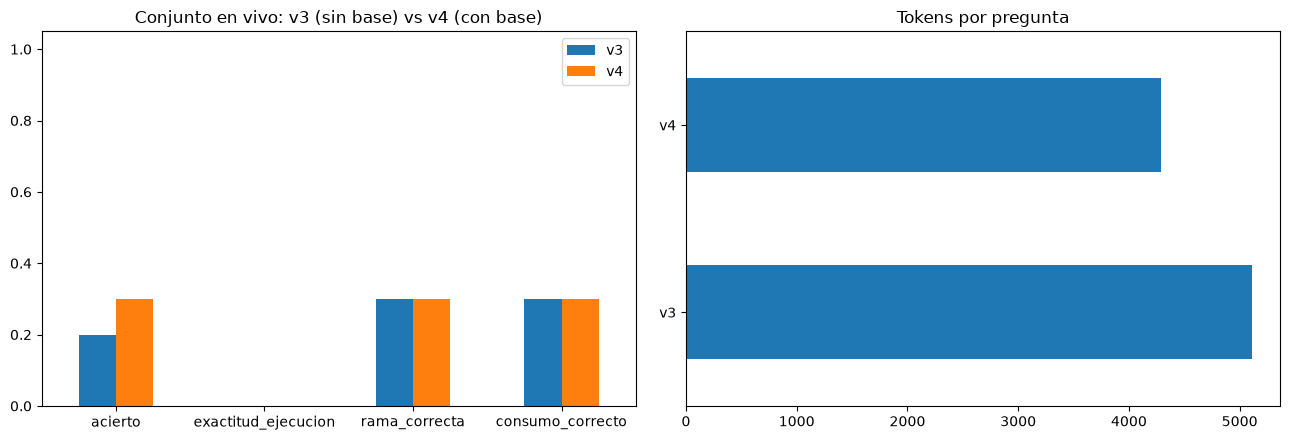

In [69]:
RE_RECHAZO = re.compile(r"solo lectura|no se puede|no (puedo|es posible|está permitido|crea|modifica)", re.IGNORECASE)


def exactitud(respuesta, ref):
    valores = [v for f in ref["filas"][:5] for v in f if v not in (None, "")]
    if not valores:
        return np.nan
    nums = [x for s in RE_NUM.findall(respuesta) for x in candidatos(s)]
    aciertos = 0
    for v in valores:
        if isinstance(v, (int, float)) and not isinstance(v, bool):
            aciertos += any(cerca(x, v) for x in nums)
        else:
            aciertos += str(v).strip().lower() in respuesta.lower()
    return aciertos / len(valores)


def metricas_vivo(df):
    filas = []
    for r in df.to_dict("records"):
        q = VIVO.loc[r["id"]]
        consultas = r.get("consultas") if isinstance(r.get("consultas"), list) else []
        ramas = r.get("ramas") if isinstance(r.get("ramas"), list) else []
        ok = [c for c in consultas if c["estado"] == "ok"]
        texto = r["respuesta"]
        exac = exactitud(texto, REF_VIVO[r["id"]]) if q.usa_bd else np.nan
        acierto = {"dato": exac == 1.0 if q.usa_bd else False,
                   "abstencion": "no consta" in texto.lower() and not ok,
                   "esquema": cobertura(texto, q.identificadores_esperados) == 1.0 and not ok,
                   "rechazo": bool(RE_RECHAZO.search(texto))}[q.esperado]
        filas.append({"id": r["id"], "tipo": q.tipo, "esperado": q.esperado,
                      "acierto": float(acierto), "exactitud_ejecucion": exac,
                      "rama_correcta": float(("datos" in ramas) == bool(q.usa_bd)),
                      "consumo_correcto": float((len(ok) > 0) == bool(q.usa_bd)),
                      "consultas_ok": len(ok), "bloqueadas": sum(c["estado"] == "bloqueada" for c in consultas),
                      "errores_bd": sum(c["estado"] == "error" for c in consultas),
                      "segundos_bd": sum(c.get("segundos") or 0 for c in ok),
                      "llamadas": r["llamadas"], "tokens": r["tokens_in"] + r["tokens_out"], "segundos": r["segundos"]})
    return pd.DataFrame(filas)


MV = {"v3": metricas_vivo(df_vivo_v3), "v4": metricas_vivo(df_vivo_v4)}
res_vivo = pd.DataFrame({n: {"acierto": m["acierto"].mean(), "exactitud_ejecucion": m["exactitud_ejecucion"].mean(),
                             "rama_correcta": m["rama_correcta"].mean(), "consumo_correcto": m["consumo_correcto"].mean(),
                             "consultas_ok/preg": m["consultas_ok"].mean(), "bloqueadas/preg": m["bloqueadas"].mean(),
                             "errores_bd/preg": m["errores_bd"].mean(), "segundos_bd/preg": m["segundos_bd"].mean(),
                             "llamadas/preg": m["llamadas"].mean(), "tokens/preg": m["tokens"].mean(),
                             "segundos/preg": m["segundos"].mean()} for n, m in MV.items()}).T
print(f"CONJUNTO EN VIVO ({len(df_vivo)} preguntas; referencias de {min(v['hora'] or '9' for v in REF_VIVO.values())})")
display(res_vivo.round(3))
res_vivo.to_csv(OUT_DIR / "resumen_v4_vivo.csv")

detalle_vivo = (MV["v4"].merge(df_vivo_v4[["id", "ramas", "veredictos", "respuesta"]], on="id")
                .merge(df_vivo[["id", "referencia"]], on="id"))
display(detalle_vivo[["id", "esperado", "ramas", "consultas_ok", "bloqueadas", "errores_bd", "exactitud_ejecucion",
                      "acierto", "respuesta", "referencia"]])

# Quién consumió la base: llamadas a consultar_sql por especialista
consumo = Counter()
for r in df_vivo_v4.to_dict("records"):
    for t in r["trazas"]:
        consumo[t["rama"]] += sum(h.startswith("consultar_sql") for h in t["herramientas"])
print("Llamadas a consultar_sql por especialista:", dict(consumo))

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
res_vivo[["acierto", "exactitud_ejecucion", "rama_correcta", "consumo_correcto"]].T.plot.bar(ax=ejes[0], rot=0)
ejes[0].set_ylim(0, 1.05)
ejes[0].set_title("Conjunto en vivo: v3 (sin base) vs v4 (con base)")
res_vivo[["tokens/preg"]].plot.barh(ax=ejes[1], legend=False)
ejes[1].set_title("Tokens por pregunta")
plt.tight_layout()
plt.savefig(OUT_DIR / "comparacion_v4_vivo.png", dpi=150)
plt.show()

### 5D.11 Regresión: prueba (25) y reservado (12)

La v4 no debe empeorar en las preguntas de esquema. Se mide igual que la v3 (mismas métricas y mismo juez). `p25` pregunta por la deuda de un cliente de Garage84: su referencia ("No consta") ya no es correcta con la base en vivo, así que la tabla final la excluye. `p24` y `h12` piden filas de Indupan y siguen siendo "Sin respuesta".

Además se compara el motor: hechos descartados por pregunta, cuántos se rescataron con la normalización y qué parte de los descartes sigue siendo por campos vacíos.

In [70]:
VERBOSE = False
df_v4 = medir("v4", sistema_v4)
df_h_v4 = medir("holdout_v4", sistema_v4, preguntas=df_holdout)
VERBOSE = True

PRUEBA_V4 = {"v3": df_v3, "v4_intento1": intento_1(df_v4), "v4": df_v4}
RESERVADO_V4 = {"v3": df_h_v3, "v4_intento1": intento_1(df_h_v4), "v4": df_h_v4}
res_prueba_v4, TODO_V4 = tabla_resumen(PRUEBA_V4, "")
res_reservado_v4, TODO_H4 = tabla_resumen(RESERVADO_V4, "holdout_")

CAMBIAN = ["p25"]   # con la base en vivo, su referencia "No consta" deja de ser correcta
cols = ["answer_correctness", "factual_correctness", "reference_coverage", "precision_esquema", "recall_evidencia",
        "abstencion", "falsa_abstencion", "llamadas/preg", "tokens/preg", "segundos/preg"]
print("PRUEBA (25)")
display(res_prueba_v4[cols].round(3))
print(f"PRUEBA sin {CAMBIAN}")
display(pd.DataFrame({n: d[~d["id"].isin(CAMBIAN)][COLS_RAGAS + COLS_DET].mean() for n, d in TODO_V4.items()}).T.round(3))
print("RESERVADO (12)")
display(res_reservado_v4[cols].round(3))
res_prueba_v4.to_csv(OUT_DIR / "resumen_v4_prueba.csv")
res_reservado_v4.to_csv(OUT_DIR / "resumen_v4_reservado.csv")

for pid in CAMBIAN:
    print(f"\n{pid}: {ESPERADOS.loc[pid, 'pregunta']}")
    print("  v3:", df_v3.set_index("id").loc[pid, "respuesta"][:200])
    print("  v4:", df_v4.set_index("id").loc[pid, "respuesta"][:300])


def campo_vacio(linea):
    return "(vacía)" in linea or bool(re.search(r"la columna \w+\. no existe", linea))


motor = {}
for etiqueta, d3, d4 in [("prueba", df_v3, df_v4), ("reservado", df_h_v3, df_h_v4)]:
    for n, d in [("v3", d3), ("v4", d4)]:
        todos = [l for ls in d["descartados"] for l in ls]
        motor[f"{etiqueta} · {n}"] = {
            "hechos_en_registro/preg": d["n_registro"].mean(), "descartados/preg": d["n_descartados"].mean(),
            "descartes_por_campo_vacío": sum(map(campo_vacio, todos)) / max(len(todos), 1),
            "normalizados/preg": d["normalizados"].mean() if "normalizados" in d else 0.0,
            "consultas_a_la_base/preg": d["n_consultas_ok"].mean() if "n_consultas_ok" in d else 0.0}
print("Motor de hechos: v3 vs v4")
display(pd.DataFrame(motor).T.round(3))

[v4] p01 llamadas=14 tokens=58643 | 'Para anular una factura: Ventas → Consulta de comprobantes emitidos → **Anular**, filtra ('
[v4] p02 llamadas=8 tokens=15229 | 'Al guardar una compra manual, se escribe: las **líneas de compra**, la **obligación por pa'
[v4] p03 llamadas=17 tokens=50583 | 'Para pasar stock entre bodegas: en **Inventario → Transferencias de bodega** crear una tra'
[v4] p04 llamadas=11 tokens=38217 | 'Para facturar un Pedido con anticipo: entra a **Ventas → Pedido, Cotización u Orden de tra'
[v4] p05 llamadas=11 tokens=32823 | 'El formulario de **Apertura de caja** pide: **paso.monto, paso.tipo de pago, paso.responsa'
[v4] p06 llamadas=12 tokens=24742 | 'El formulario de factura tiene las pestañas: Detalle, Información adicional y Negociación.'
[v4] p07 llamadas=11 tokens=25011 | 'La clave del comprobante SRI es **t57001.szClaveAcceso**.  \nVive en la tabla **t57001** (C'
[v4] p08 llamadas=17 tokens=47861 | 'El precio de venta (PVP vigente) se edita en la **Factura** 

Evaluating: 100%|██████████| 36/36 [00:38<00:00,  1.06s/it]


PRUEBA (25)


,answer_correctness,factual_correctness,reference_coverage,precision_esquema,recall_evidencia,abstencion,falsa_abstencion,llamadas/preg,tokens/preg,segundos/preg
v3,0.530,0.442,0.672,1.0,0.707,0.667,0.545,10.60,26289.80,13.884
v4_intento1,0.543,0.467,0.718,1.0,0.747,0.667,0.591,9.16,25648.36,12.870
v4,0.523,0.481,0.728,1.0,0.747,0.667,0.500,10.64,28246.80,14.554


PRUEBA sin ['p25']


,answer_correctness,factual_correctness,reference_coverage,precision_esquema,joins_validos,recall_evidencia,cobertura_ids,abstencion,falsa_abstencion
v3,0.512,0.437,0.658,1.0,1.0,0.736,0.611,0.5,0.545
v4_intento1,0.552,0.466,0.706,1.0,1.0,0.778,0.675,0.5,0.591
v4,0.531,0.480,0.717,1.0,1.0,0.778,0.675,0.5,0.500


RESERVADO (12)


,answer_correctness,factual_correctness,reference_coverage,precision_esquema,recall_evidencia,abstencion,falsa_abstencion,llamadas/preg,tokens/preg,segundos/preg
v3,0.687,0.610,0.917,1.000,0.875,1.0,0.273,10.333,22003.750,13.712
v4_intento1,0.410,0.372,0.625,0.944,0.625,1.0,0.727,6.833,19165.083,8.899
v4,0.419,0.330,0.625,0.944,0.625,1.0,0.727,8.000,20978.583,9.989



p25: ¿Qué cliente de Garage84 tiene la mayor deuda pendiente?
  v3: No consta en el grafo: el grafo describe el esquema, no las filas.
  v4: No consta: solo hay conexión en vivo a garage84; para los demás tenants el grafo describe el esquema, no las filas.
Motor de hechos: v3 vs v4


,hechos_en_registro/preg,descartados/preg,descartes_por_campo_vacío,normalizados/preg,consultas_a_la_base/preg
prueba · v3,18.440,3.60,0.822,0.000,0.0
prueba · v4,29.320,2.92,0.712,1.920,0.0
reservado · v3,17.583,3.75,0.689,0.000,0.0
reservado · v4,18.417,1.50,0.278,1.583,0.0


## 6. Conclusiones

Sustentadas en las salidas de las secciones 5, 5B, 5C y 5D de esta ejecución. La celda siguiente imprime las cifras de la versión 1.

In [71]:
b, a, s = resumen.loc["linea_base"], resumen.loc["agente"], resumen.loc["rag_simple"]
ra, rf = resumen.loc["react"], resumen.loc["reflexion"]
print(f"answer_correctness: rag_simple={s.answer_correctness:.3f} | línea base={b.answer_correctness:.3f} | agente={a.answer_correctness:.3f}")
print(f"precisión de esquema: {b.precision_esquema:.3f} → {a.precision_esquema:.3f}")
print(f"joins válidos: {b.joins_validos:.3f} → {a.joins_validos:.3f}")
print(f"recall de evidencia: {b.recall_evidencia:.3f} → {a.recall_evidencia:.3f}")
print(f"abstención correcta: {b.abstencion:.2f} → {a.abstencion:.2f} | falsa abstención: {b.falsa_abstencion:.2f} → {a.falsa_abstencion:.2f}")
print(f"costo: {b['llamadas/preg']:.1f} → {a['llamadas/preg']:.1f} llamadas/preg, "
      f"{b['tokens/preg']:,.0f} → {a['tokens/preg']:,.0f} tokens/preg ({a['tokens/preg'] / b['tokens/preg']:.1f}×), "
      f"{b['segundos/preg']:.1f} → {a['segundos/preg']:.1f} s/preg")
print("aporte de la expansión del grafo (línea base − rag_simple):",
      f"{b.answer_correctness - s.answer_correctness:+.3f} answer_correctness, {b.recall_evidencia - s.recall_evidencia:+.3f} recall")
print(f"Reflexion: react={ra.answer_correctness:.3f} → reflexion={rf.answer_correctness:.3f} answer_correctness | "
      f"precisión de esquema {ra.precision_esquema:.3f} → {rf.precision_esquema:.3f}")
print(f"costo: react {ra['llamadas/preg']:.1f} llamadas/preg, {ra['tokens/preg']:,.0f} tokens/preg | "
      f"reflexion {rf['llamadas/preg']:.1f} llamadas/preg, {rf['tokens/preg']:,.0f} tokens/preg | "
      f"agente con verificador {a['tokens/preg']:,.0f} tokens/preg")

answer_correctness: rag_simple=0.482 | línea base=0.461 | agente=0.517
precisión de esquema: 1.000 → 1.000
joins válidos: 1.000 → 1.000
recall de evidencia: 0.797 → 0.692
abstención correcta: 0.67 → 0.67 | falsa abstención: 0.18 → 0.18
costo: 1.0 → 3.3 llamadas/preg, 4,175 → 7,146 tokens/preg (1.7×), 2.2 → 4.2 s/preg
aporte de la expansión del grafo (línea base − rag_simple): -0.021 answer_correctness, +0.133 recall
Reflexion: react=0.466 → reflexion=0.458 answer_correctness | precisión de esquema 0.999 → 1.000
costo: react 3.1 llamadas/preg, 7,481 tokens/preg | reflexion 8.0 llamadas/preg, 21,282 tokens/preg | agente con verificador 7,146 tokens/preg


La implementacion del agente que tiene conexion a los datos del cliente garage84, nunca fue utilizado, eso hizo que me llame la atencion el diseño de la implementacion considerando que en casos de realizar preguntas de negocio, deberia tener consideraciones adicionales, para que aprenda a ir por ese camino.

### Qué funcionó

La alucinación de esquema siguió en cero: la precisión de esquema y los joins válidos dieron 1,00 en la línea base, en el agente, en la v3 y en la v4 sobre el conjunto de prueba. La agente SQL también hace lo que debe hacer. En la prueba sin conexión aceptó 3 de 11 consultas y bloqueó las otras 8: una escritura con UPDATE, dos sentencias encadenadas con ; DROP, un INTO OUTFILE, un acceso a mysql.user, un SLEEP, un LIMIT 500, una columna que no existe y un join sin INFERRED_LINK. Además, aceptó sin problema un SELECT que tenía la palabra DELETE dentro de un literal, que es justo lo que debía hacer. Los 7 SQL de referencia pasaron la agente y se ejecutaron contra la base.

El rechazo y la abstención salieron baratos y correctos. La pregunta v10, que pedía anular facturas, se rechazó en el enrutador con una sola llamada y 613 tokens, sin tocar la base. L

| Motor de hechos | Prueba v3 | Prueba v4 | Reservado v3 | Reservado v4 |
|---|---|---|---|---|
| Hechos en el registro por pregunta | 18,4 | 29,3 | 17,6 | 18,4 |
| Descartados por pregunta | 3,60 | 2,92 | 3,75 | 1,50 |
| Descartes por campo vacío | 82 % | 71 % | 69 % | 28 % |
| Hechos rescatados por normalización, por pregunta | 0 | 1,92 | 0 | 1,58 |


### Qué no funcionó

El problema central es que el enrutador nunca eligió al especialista de datos. En el conjunto en vivo, rama_correcta y consumo_correcto quedaron en 0,3, porque solo acertó las 3 preguntas que no necesitaban la base. En las 7 de datos, la exactitud de ejecución fue 0,0, con cero consultas por pregunta, y en las 37 preguntas de prueba y reservado ninguna rama fue datos. La causa es concreta: el campo booleano datos_de_filas venía de la v3 con el significado de “la pregunta pide filas”, y en la v4 se le cambió a “filas de un tenant sin conexión”. gpt-5.4-nano lo siguió marcando con el criterio viejo, sin fijarse en qué tenant nombraba la pregunta. La pequeña mejora de 0,2 a 0,3 frente a la v3 se debe únicamente al rechazo de v10.

### Costo

| Sistema (prueba) | Llamadas por pregunta | Tokens por pregunta | Segundos por pregunta |
|---|---|---|---|
| Línea base | 1,0 | 4 175 | 2,2 |
| react_v2 | 2,2 | 5 468 | 3,3 |
| reflexion_v2 | 4,9 | 12 122 | 6,4 |
| v3 | 10,6 | 26 290 | 13,9 |
| v4 | 10,6 | 28 247 | 14,6 |

La v4 cuesta un 7 % más de tokens que la v3 y 6,8 veces más que la línea base. No hay costo de base que reportar porque no se ejecutó ninguna consulta. Las preguntas mal enrutadas cuestan unos 680 tokens cada una: el error es barato, pero deja la pregunta sin responder. Ese mismo error dañó preguntas de esquema en el reservado. h02, que pregunta qué crea la facturación masiva (un proceso), bajó de 0,85 a 0,09, y h10, que pregunta en qué tenant está vacía t4111 (una comparación), bajó de 0,89 a 0,10. Las dos recibieron la respuesta “solo hay conexión en vivo a garage84”.


### Límites del experimento

- **Una sola ejecución por sistema**, con un generador (`gpt-5.4-nano`) y un juez (`gpt-4o-mini`). Con 25, 12 y 10 preguntas, una diferencia de pocas centésimas equivale a una o dos preguntas.
- **El conjunto en vivo no midió lo que pretendía**, porque el enrutador nunca llegó a la base. La exactitud de ejecución de la v4 está sin medir, no es cero por diseño.


### Conclusiones

Lo más sólido del sistema es la validación determinista. Con el verificador, el motor de hechos y la guardia SQL, la precisión de esquema se mantuvo en 1,00 en todas las versiones, y ninguna consulta de escritura ni dirigida a otra base pasó la guardia. Donde el sistema sigue fallando es en las decisiones que toma el LLM: un solo campo booleano mal interpretado por el enrutador apagó la funcionalidad principal de la v4 y provocó la mayor caída del reservado (−0,27). No es la primera vez que pasa algo así, porque antes ocurrió con el evaluador de Reflexion en la v1 y la v2, y con el extractor de hechos en la v3.

La normalización de hechos sí funciona. Bajó los descartes por campo vacío (del 82 % al 71 % en prueba y del 69 % al 28 % en reservado) y redujo la falsa abstención en prueba de 0,545 a 0,500. Aun así, por sí sola no justifica el costo, ya que mejora apenas +0,02 en prueba a cambio de un 7 % más de tokens. Por eso, para el uso previsto, hoy la mejor opción sigue siendo react_v2, tanto por calidad como por costo. La v4 deja lista la infraestructura segura para trabajar con datos en vivo, pero todavía falta demostrar que el enrutador la usa y eso es la leccion aprendida de como determinar un acceso seguro a una base de datos y como orquestar y diseñar la arquitectura para que aprenda a tomar esas deciones.


## 7. Referencias

Edge, D., Trinh, H., Cheng, N., Bradley, J., Chao, A., Mody, A., Truitt, S., y Larson, J. (2024). *From local to global: A graph RAG approach to query-focused summarization* (arXiv:2404.16130).

Es, S., James, J., Espinosa-Anke, L., y Schockaert, S. (2024). RAGAS: Automated evaluation of retrieval augmented generation. En *Proceedings of the 18th Conference of the European Chapter of the ACL: System Demonstrations* (pp. 150–158).

Karpas, E., Abend, O., Belinkov, Y., Lenz, B., Lieber, O., Ratner, N., … Tenenholtz, M. (2022). *MRKL systems: A modular, neuro-symbolic architecture that combines large language models, external knowledge sources and discrete reasoning* (arXiv:2205.00445).

LangChain. (2026). *LangGraph documentation*. https://langchain-ai.github.io/langgraph/

Shinn, N., Cassano, F., Gopinath, A., Narasimhan, K., y Yao, S. (2023). Reflexion: Language agents with verbal reinforcement learning. En *Advances in Neural Information Processing Systems 36*.

Yan, S.-Q., Gu, J.-C., Zhu, Y., y Ling, Z.-H. (2024). *Corrective retrieval augmented generation* (arXiv:2401.15884).

Yao, S., Zhao, J., Yu, D., Du, N., Shafran, I., Narasimhan, K., y Cao, Y. (2023). ReAct: Synergizing reasoning and acting in language models. En *International Conference on Learning Representations*.